# SARGen: an automated, explainable SAR ADC generator in SKY130

**IEEE SSCS Code-a-Chip - ISSCC 2027**

| Name | Affiliation | Contact | IEEE member | SSCS member |
|---|---|---|---|---|
| Rajinthan Rameshkumar | Final-year undergraduate, Dept. of Electronic and Telecommunication Engineering, University of Moratuwa, Sri Lanka | rajinthan519@gmail.com, [rajinthan.com](https://rajinthan.com) | Yes | Yes |

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/SAR_ADC_Generator/SAR_ADC_Generator.ipynb)
(before the merge: [open from the submission branch](https://colab.research.google.com/github/rajinthanr/sscs-ose-code-a-chip.github.io/blob/sar-adc-generator/ISSCC27/submitted_notebooks/SAR_ADC_Generator/SAR_ADC_Generator.ipynb))
&nbsp; | &nbsp; License: Apache-2.0 (`LICENSE`) &nbsp; | &nbsp; All tools and the PDK are open source.

## Abstract
Successive-approximation (SAR) ADCs are the workhorse of low-power data conversion, yet the path from a specification
("N bits at f<sub>s</sub>") to sized transistors and a clean layout is usually manual and undocumented. **SARGen**
automates that path on the open SkyWater SKY130 PDK and explains every step. From two inputs - resolution (4 to 8
bits) and sample rate - the notebook characterizes the PDK by simulation, sizes every block from a written rule that
logs its reason, writes the transistor-level netlist and verifies it (linearity, ENOB, Monte Carlo, corners), then
**generates the layout from the PDK's own cells**, signs it off (two DRC engines, LVS, antenna) and re-simulates the
extraction.

The same code, unchanged, produced signed-off 4-, 6- and 8-bit cores at 10 MS/s: **post-layout ENOB 3.96 / 6.02 /
7.71 bit** (7.88 at -0.5 dBFS), **max |DNL| <= 0.25 LSB**, no missing codes, 0.003 - 0.016 mm<sup>2</sup> and
26 - 289 uW. Checks that failed - hot-corner leakage, antenna ratios, device matching - were fixed in the generator,
never by hand.

## At a glance
**What SARGen does**: you ask for an ADC, and it designs, draws and checks one, explaining every step.

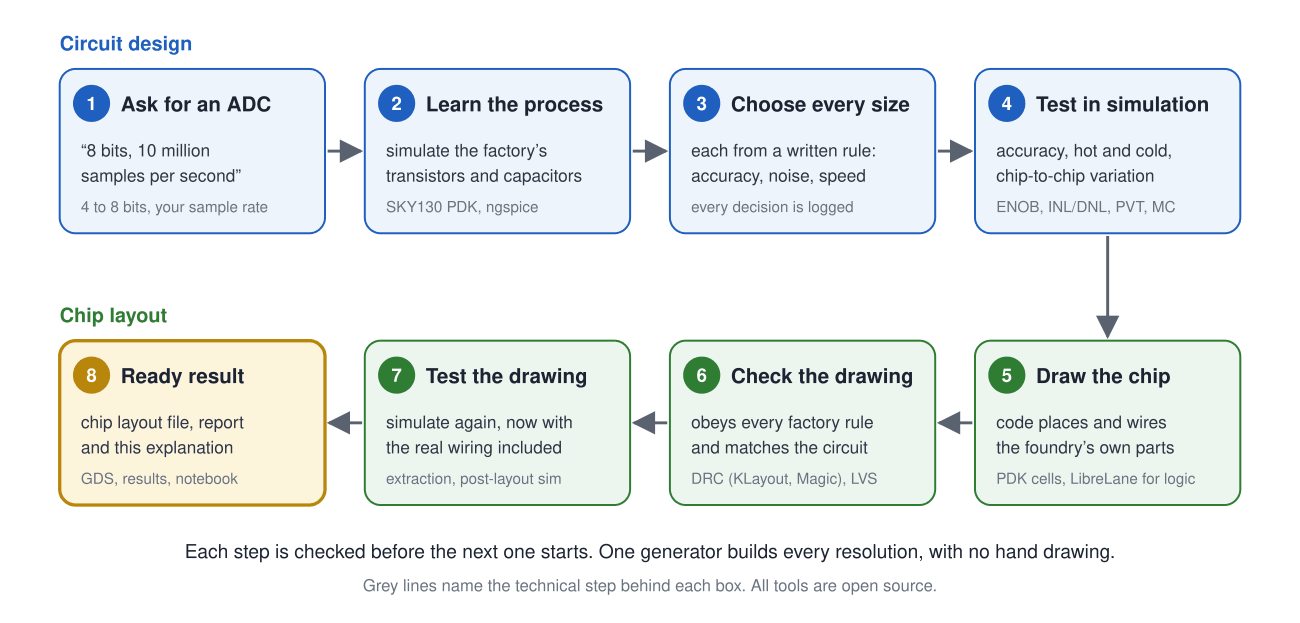

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

def glance(p, width=950):
    p = Path(p)
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:                       # Colab: the repository folder is opened by the setup cell below
        print(f"({p} is in the project folder; run the setup cell first)")

glance("docs/sargen_workflow.png")

**What it produced**: the same generator, unchanged, at 4, 6 and 8 bits. The table is computed from the result
files of sections 11 and 13: transistor-level simulation of each *extracted* layout against its schematic.

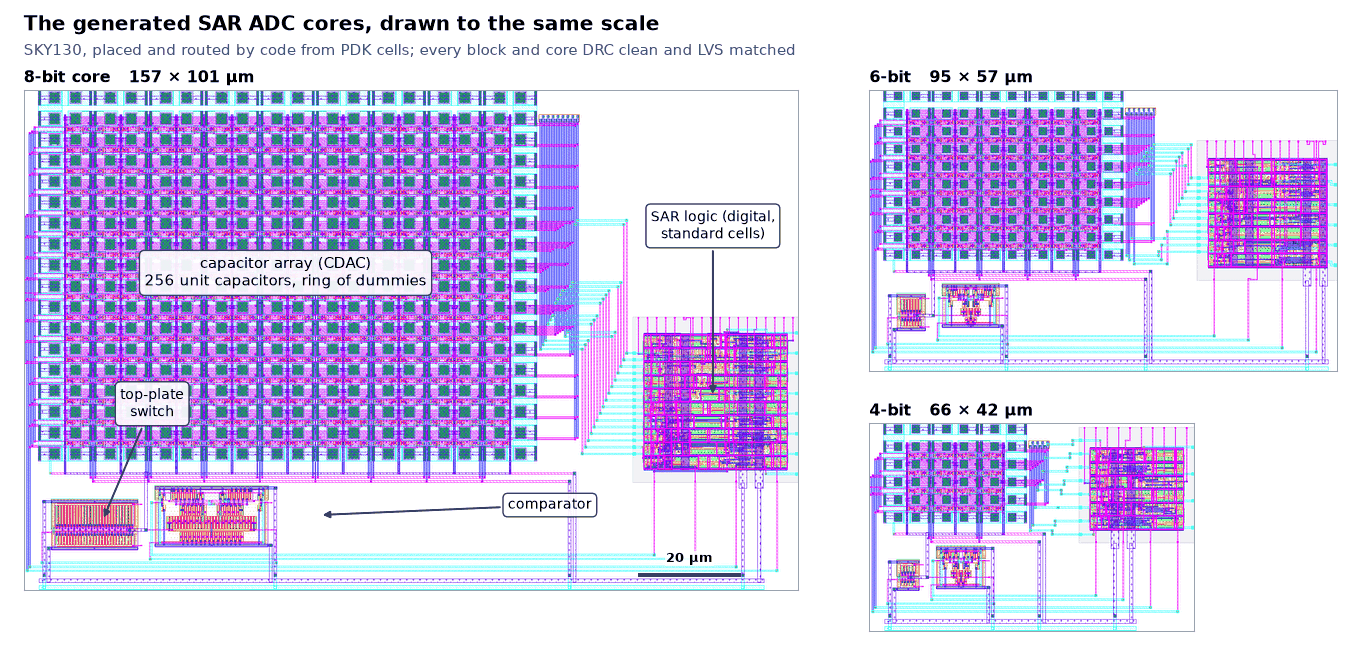

| resolution | core area | ENOB, schematic → layout | max DNL / INL, layout | power, layout | Walden FoM, layout |
|---|---|---|---|---|---|
| 4 bit | 2762 µm² | 3.97 → 3.96 | 0.07 / 0.08 LSB | 26 µW | 170 fJ/step |
| 6 bit | 5382 µm² | 6.01 → 6.02 | 0.05 / 0.07 LSB | 63 µW | 97 fJ/step |
| 8 bit | 15854 µm² | 7.68 → 7.71 | 0.25 / 0.22 LSB | 289 µW | 138 fJ/step |

8-bit layout ENOB at -0.5 dBFS (no clipping): **7.88** - the full-scale test sine clips on the extracted core's offset of 1.4 LSB (section 13).

In [2]:
glance("docs/layouts_to_scale.png")
rows = ["| resolution | core area | ENOB, schematic → layout | max DNL / INL, layout | power, layout | Walden FoM, layout |",
        "|---|---|---|---|---|---|"]
for b in (4, 6, 8):
    pp = Path(f"results/{b}bit/layout/prepost.json")
    if not pp.exists():
        continue
    r = json.loads(pp.read_text())
    s, x = r["schematic"], r["full core from layout"]
    fs = json.loads(Path(f"results/{b}bit/summary.json").read_text())["spec"]["fs"]
    core = next(ln for ln in Path(f"results/{b}bit/layout/signoff.md").read_text().splitlines() if "core (all blocks" in ln)
    fom = x["p_uw"] * 1e-6 / (2 ** x["enob"] * fs) * 1e15
    rows.append(f"| {b} bit | {core.split('|')[3].strip()} µm² | {s['enob']:.2f} → {x['enob']:.2f} | "
                f"{x['dnl_t']:.2f} / {x['inl_t']:.2f} LSB | {x['p_uw']:.0f} µW | {fom:.0f} fJ/step |")
bo = Path("results/8bit/layout/sine_backoff.md")
if bo.exists():   # the 8-bit full-scale sine clips on the core's offset (section 13)
    r = next(ln for ln in bo.read_text().splitlines() if ln.startswith("| full core"))
    rows.append(f"\n8-bit layout ENOB at -0.5 dBFS (no clipping): **{r.split('|')[3].strip()}** - the full-scale test "
                f"sine clips on the extracted core's offset of {-x['offset_lsb']:.1f} LSB (section 13).")
display(Markdown("\n".join(rows)))

**Does it meet its own specification?** The generator sizes every block for the targets of section 1; this table
checks them against the simulated results, at every resolution.

In [3]:
def md_rows(path):
    # the rows of the first markdown table in a result file, as dicts
    lines = [l for l in Path(path).read_text().splitlines() if l.startswith("|")]
    head = [c.strip() for c in lines[0].strip("|").split("|")]
    return [dict(zip(head, (c.strip() for c in l.strip("|").split("|")))) for l in lines[2:]]

def spec_check():
    ok = lambda v, t: "✅" if v <= t + 1e-9 else "❌"
    rows, lvs = {}, {}
    for b in (4, 6, 8):
        sp = json.loads(Path(f"results/{b}bit/summary.json").read_text())
        spec, lsb_mv = sp["spec"], sp["spec"]["lsb"] * 1e3
        x = json.loads(Path(f"results/{b}bit/layout/prepost.json").read_text())["full core from layout"]
        cmp_ = next(r for r in md_rows(f"results/{b}bit/layout/comparator_layout_ab.md") if r["layout"] == "after")
        sig = float(cmp_["Monte Carlo sigma [mV] (n)"].split()[0])
        noise = next(r for r in md_rows("results/comparator_noise.md") if r["bits"] == str(b))
        num, den = noise["sigma / LSB"].split("/")
        core = next(ln for ln in Path(f"results/{b}bit/layout/signoff.md").read_text().splitlines() if "core (all" in ln)
        c = [v.strip() for v in core.strip("|").split("|")]
        lvs[b] = "match ✅" if c[5].startswith("match") else "fail ❌"
        rows[b] = [("missing codes, extracted core", 0, x["missing"], "{:.0f}"),
                   ("max DNL, extracted core [LSB]", spec["dnl_3sigma_lsb"], x["dnl_t"], "{:.2f}"),
                   ("DNL, 99 % of chips (mismatch MC) [LSB]", spec["dnl_3sigma_lsb"], sp["mc"]["dnl_p99"], "{:.2f}"),
                   ("comparator offset 3 sigma, extracted [LSB]", spec["offset_3sigma_lsb"], 3 * sig / lsb_mv, "{:.2f}"),
                   ("comparator noise sigma [LSB]", spec["noise_lsb"], float(num) / float(den), "{:.3f}"),
                   ("DRC errors (KLayout + Magic), core", 0, float(c[3]) + float(c[4]), "{:.0f}")]
    out = ["| requirement | target | 4 bit | 6 bit | 8 bit |", "|---|---|---|---|---|"]
    for k, (name, tgt, _, f) in enumerate(rows[4]):
        cells = [f"{f.format(rows[b][k][2])} {ok(rows[b][k][2], rows[b][k][1])}" for b in (4, 6, 8)]
        out.append(f"| {name} | {'0' if tgt == 0 else '<= ' + format(tgt, 'g')} | " + " | ".join(cells) + " |")
    out.append("| LVS, core | match | " + " | ".join(lvs[b] for b in (4, 6, 8)) + " |")
    return "\n".join(out)

display(Markdown(spec_check()))

| requirement | target | 4 bit | 6 bit | 8 bit |
|---|---|---|---|---|
| missing codes, extracted core | 0 | 0 ✅ | 0 ✅ | 0 ✅ |
| max DNL, extracted core [LSB] | <= 0.5 | 0.07 ✅ | 0.05 ✅ | 0.25 ✅ |
| DNL, 99 % of chips (mismatch MC) [LSB] | <= 0.5 | 0.13 ✅ | 0.30 ✅ | 0.44 ✅ |
| comparator offset 3 sigma, extracted [LSB] | <= 1 | 0.26 ✅ | 0.98 ✅ | 0.91 ✅ |
| comparator noise sigma [LSB] | <= 0.1 | 0.004 ✅ | 0.016 ✅ | 0.024 ✅ |
| DRC errors (KLayout + Magic), core | 0 | 0 ✅ | 0 ✅ | 0 ✅ |
| LVS, core | match | match ✅ | match ✅ | match ✅ |

All at 10 MS/s, 1.8 V and the typical corner; every block and core passes DRC (KLayout and Magic) and LVS (Netgen).
Layout keeps the schematic's accuracy; power rises with the wiring the logic drives (section 13). The 8-bit linearity
is resolved to 1/4 LSB (4 ramp points per code). Limits and open items are listed at the end.

## Contents - and where to look first
**Five minutes:** *At a glance* (above), *Prior work and what SARGen adds* (below), the layouts and signoff of section 13
and the conclusion in section 14.

| section | what it shows |
|---|---|
| 1-3 | the specification, the SAR conversion animated and in 3D, one call that runs the whole flow |
| 4-5 | SKY130 characterized by simulation; every block sized from a written rule, with the reason logged |
| 6-10 | the generated transistor-level netlist: one conversion, comparator offset (and a gm/Id check), static and dynamic linearity, yield |
| 11 | the same generator from 4 to 8 bits |
| 12 | robustness: process, temperature, supply, input frequency, sample rate, mismatch; the 8-bit design beyond nominal |
| 13 | automated layout from PDK cells, DRC / LVS / antenna signoff, extraction and post-layout simulation, benchmark |
| 14 | specification check, conclusion, limitations, roadmap, references |

## Prior work and what SARGen adds
Automated SAR ADC design exists, mostly on commercial processes: the **OpenSAR** compiler [11] goes from specification
to GDS in 40 nm, the **compiled SAR** of Wulff and Ytterdal [12] is laid out from a netlist and rule files, and
**BAG2** [13] generates layouts across processes from designer-written scripts. On the open SKY130 PDK, Tiny Tapeout 6
carried an 8-bit SAR [14], and Code-a-Chip has seen a Flash ADC generator (VLSI25) and an R-2R DAC flow (ISSCC26).

| | process / PDK | sizing from a specification | layout | verified by | open and reproducible |
|---|---|---|---|---|---|
| OpenSAR [11] | 40 nm, commercial | yes (optimizer) | generated | measured silicon | compiler open, PDK not |
| Compiled SAR [12] | 28 nm FDSOI, commercial | no (from a netlist) | compiled from rule files | measured silicon | no |
| BAG2 [13] | several, commercial | designer scripts | generated | measured silicon | framework open, PDKs not |
| TT06 SAR [14] | SKY130, open | - | - | simulation | yes |
| **SARGen** (this work) | **SKY130, open** | **yes: written rules, PDK characterized by simulation, reasons logged** | **generated from PDK cells** | **DRC (2 engines), LVS, antenna, post-layout simulation** | **yes, one notebook** |

SARGen adds, in one reproducible notebook on an open PDK:
* **every size from a written rule** that cites its numbers, measured from the PDK by simulation, not assumed;
* **layout generated from the PDK's own cells** and signed off, for 4 to 8 bits without hand drawing;
* **post-layout verification** that compares schematic and extracted layout on the same testbench, and explains
  each difference with a measured cause (section 13);
* **checks beyond a nominal run** - corners, mismatch, noise, kickback, wiring resistance, real sources, device
  matching - that fed back into the generator: a leakage-aware top-plate switch, antenna diodes and a matching rework
  were added because the checks found problems.
The benchmark at the end of section 13 places the result against published SAR ADCs.

## How to run
Everything uses open-source tools inside the **IIC-OSIC-TOOLS** container (tested with tag `2026.10`:
ngspice-47, Magic, Netgen, KLayout, SKY130A).

```bash
docker run -it --rm -p 127.0.0.1:8888:8888 -v $PWD:/foss/designs hpretl/iic-osic-tools:2026.10 -s jupyter lab
```

| tool | version used | role |
|---|---|---|
| IIC-OSIC-TOOLS | 2026.10 | container with everything below |
| SKY130A PDK | open_pdks 1689ac3f | models, PCells, rule decks |
| ngspice | 47 | every simulation |
| Magic | 8.3.685 | PCells, DRC, extraction, antenna check |
| KLayout | 0.30.12 | DRC (sky130A_mr + capm.10 deck), rendering |
| Netgen | 1.5.324 | LVS |
| LibreLane | 3.1.0.dev3 (Yosys 0.70, OpenROAD) | SAR logic hardening |
| gdsfactory / gLayout | 7.7.0 / 0.2.0 | layout generators |
| Python | 3.12 | numpy, matplotlib, pillow |
or, headless: `python3 run_flow.py --bits 4`. Python dependencies: numpy, matplotlib, pillow (all in the image).
A complete 4-bit run takes about 11 minutes on a 12-core laptop (simulations run in parallel).

**Google Colab:** run the next cell first. It installs ngspice (conda-forge) and the SKY130 PDK (`ciel`) in about
8 minutes and switches to a quicker test setting, because Colab has only 2 CPU cores. Locally it does nothing.

In [ ]:
# Google Colab only: installs ngspice (conda-forge) and the SKY130 PDK (ciel) - about 8 min, once per runtime.
# Locally (IIC-OSIC-TOOLS container) this cell does nothing.
import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/rajinthanr/sscs-ose-code-a-chip.github.io"
BRANCH = "sar-adc-generator"
PROJECT = "ISSCC27/submitted_notebooks/SAR_ADC_Generator"
SKY130_VERSION = "792ef67037d74c8c51811eab3ce23cf793491296"   # ciel sky130 build tested with this notebook

if IN_COLAB and not os.path.exists("/content/eda/bin/ngspice"):
    subprocess.run(["bash", "-c", f"""
        set -e; cd /content
        [ -d cac ] || (git clone -q --depth 1 --filter=blob:none --sparse -b {BRANCH} {REPO} cac &&
                       git -C cac sparse-checkout set {PROJECT})
        curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
        ./bin/micromamba create -y -q -p /content/eda -c conda-forge ngspice
        pip install -q ciel
        for i in 1 2 3; do   # retry: large downloads occasionally hit transient network errors
            ciel enable --pdk-family sky130 --pdk-root /content/pdk {SKY130_VERSION} && break
            [ $i = 3 ] && exit 1; sleep 15
        done
    """], check=True)
if IN_COLAB:
    os.environ["PATH"] = "/content/eda/bin:" + os.environ["PATH"]
    os.environ["PDK_ROOT"] = "/content/pdk"
    os.chdir(f"/content/cac/{PROJECT}")
QUICK = IN_COLAB      # Colab has 2 CPUs: fewer ramp hits / FFT points

## 1. Specification
Change `BITS` (4..8) and `FS` and re-run the notebook - every number below is regenerated.

In [5]:
import json, os
from pathlib import Path
from IPython.display import Image, Markdown, display

from sargen import SarSpec
from sargen.flow import run_flow
from sargen.model import SarModel
from sargen.anim import animate_conversion
from sargen.sizing import sizing_table_md

BITS = 4          # resolution (4..8)
FS = 10e6         # sample rate [S/s]
spec = SarSpec(bits=BITS, fs=FS)
FLOW_OPTS = dict(hits=8, fft_n=64, mc_runs=300) if globals().get("QUICK") else {}
OUT = Path(f"build/{BITS}bit")
sp = spec.to_dict()
display(Markdown("\n".join([
    "| specification | value | used for |", "|---|---|---|",
    f"| resolution / sample rate | {sp['bits']} bit / {sp['fs'] / 1e6:g} MS/s | everything |",
    f"| supply, reference, common mode | {sp['vdd']} V, {sp['vref']} V, {sp['vcm']} V | LSB = {sp['lsb'] * 1e3:.1f} mV |",
    f"| SAR clock | {sp['fclk'] / 1e6:g} MHz ({sp['cycles']} cycles per conversion) | switch and comparator timing |",
    f"| DNL target (3 sigma, capacitor mismatch) | {sp['dnl_3sigma_lsb']} LSB | unit capacitor size |",
    f"| comparator offset target (3 sigma) | {sp['offset_3sigma_lsb']} LSB | input-pair size |",
    f"| comparator noise target | {sp['noise_lsb']} LSB | kT/C and input pair |",
    f"| settling target | {sp['settle_lsb']} LSB | switch and driver widths |",
    f"| sizing condition | {sp['corner']}, {sp['temp']:g} C | (corners are checked in section 12) |"])))

| specification | value | used for |
|---|---|---|
| resolution / sample rate | 4 bit / 10 MS/s | everything |
| supply, reference, common mode | 1.8 V, 1.8 V, 0.9 V | LSB = 112.5 mV |
| SAR clock | 60 MHz (6 cycles per conversion) | switch and comparator timing |
| DNL target (3 sigma, capacitor mismatch) | 0.5 LSB | unit capacitor size |
| comparator offset target (3 sigma) | 1.0 LSB | input-pair size |
| comparator noise target | 0.1 LSB | kT/C and input pair |
| settling target | 0.25 LSB | switch and driver widths |
| sizing condition | tt, 27 C | (corners are checked in section 12) |

## 2. How a SAR ADC works - animated
The input is sampled on the bottom plates of a binary-weighted capacitor array [1] while the top plate is held at
V<sub>cm</sub>. Afterwards the bottom plates are switched to V<sub>ref</sub> or ground one bit at a time
(MSB first). Charge conservation makes the top plate move by
$V_x - V_{cm} = \sum_i b_i\,\frac{C_i}{C_{tot}}V_{ref} - V_{in}$, so the comparator only has to decide the
*sign*: if the DAC voltage is still below V<sub>in</sub> the bit is kept, otherwise it is cleared.
After N decisions the bits are the binary code of V<sub>in</sub>.
The circuit SARGen generates (single-ended, bottom-plate sampling; source `docs/sar_architecture.svg`):

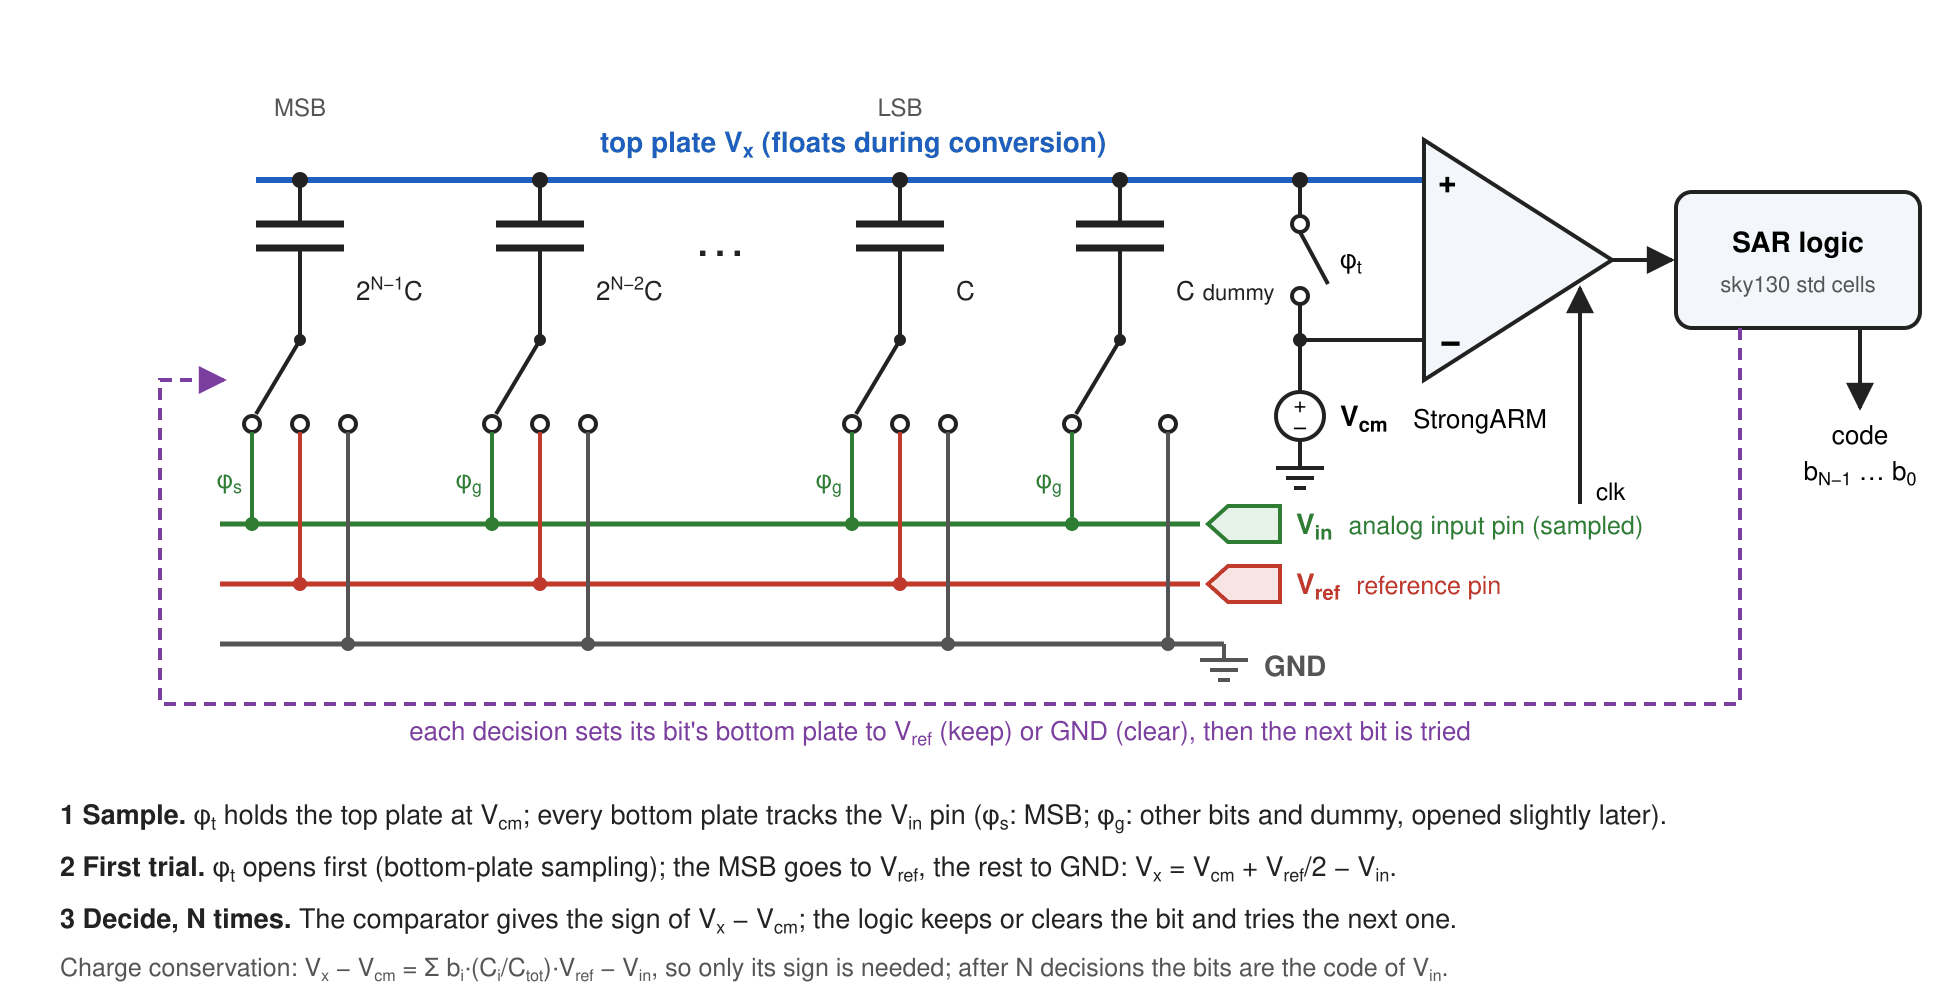

In [6]:
display(Image(filename="docs/sar_architecture.png", width=900))

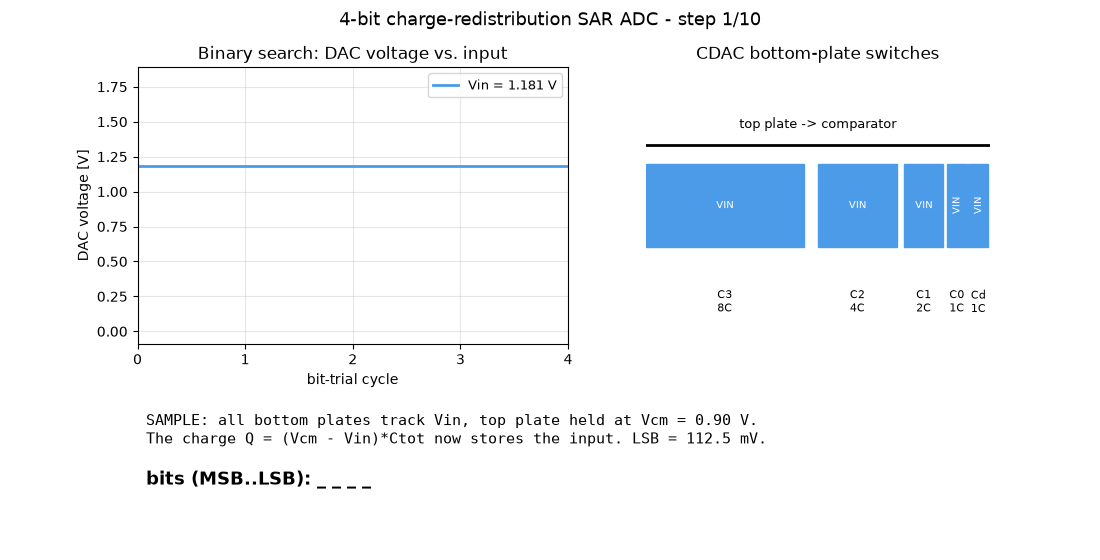

In [7]:
OUT.mkdir(parents=True, exist_ok=True)
vin_demo = round(0.6 * 2**BITS) * spec.lsb + 0.5 * spec.lsb
animate_conversion(SarModel(BITS, spec.vref), vin_demo, OUT / "sar_animation.gif")
Image(filename=str(OUT / "sar_animation.gif"))

The animation follows one input. The figure below runs the same search for one input per code at once (ideal 4-bit converter, computed below with `SarModel.trace`).

In [8]:
%matplotlib inline
# Look shared by the explanatory figures below (matplotlib only): quiet panes and grid, one accent colour,
# a validated categorical palette, and text in ink colours rather than series colours.
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import proj3d
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection

INK, NOTE, MUTED, GRID = "#1d2330", "#4b5563", "#6b7280", "#d7dbe0"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9bdc5"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#e8f1fb", "#9cc3ee", "#2a78d6", "#123f78"])
RAMP = LinearSegmentedColormap.from_list("ramp", ["#9cc3ee", "#2a78d6", "#123f78"])

def style3d(ax):
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_facecolor("#f7f8fa"); a.pane.set_edgecolor(GRID)
        a._axinfo["grid"].update(color=GRID, linewidth=0.6)
    ax.tick_params(labelsize=9.5, colors=INK)

def heading(fig, title, note, y=0.955):
    fig.text(0.03, y, title, fontsize=15, fontweight="bold", color=INK)
    fig.text(0.03, y - 0.045, note, fontsize=10.5, color=NOTE, va="top")

def pin(fig, ax, x, y, z, text="", dx=0.0, dy=0.0, marker=True, ha="center", va="bottom", **kw):
    # a marker / label that stays in front of 3D surfaces: project the 3D point, then draw in figure coordinates
    fig.canvas.draw()
    X, Y, _ = proj3d.proj_transform(x, y, z, ax.get_proj())
    fx, fy = fig.transFigure.inverted().transform(ax.transData.transform((X, Y)))
    if marker:
        fig.add_artist(plt.Line2D([fx], [fy], marker="o", ms=6.5, color=INK, mec="white", mew=1.2))
    if text:
        if dx or dy:
            fig.add_artist(plt.Line2D([fx, fx + dx], [fy, fy + dy], color=MUTED, lw=0.8))
        fig.text(fx + dx, fy + dy, text, ha=ha, va=va, **{"color": INK, **kw})
    return fx, fy

def render(fig):
    # show the figure as a PNG with a 192-colour palette: flat-colour figures stay sharp at about 1/3 of the size
    from io import BytesIO
    from PIL import Image as PILImage
    raw, small = BytesIO(), BytesIO()
    fig.savefig(raw, format="png", dpi=100, facecolor="white"); plt.close(fig)
    PILImage.open(raw).convert("RGB").quantize(colors=192, dither=PILImage.Dither.NONE).save(small, "PNG", optimize=True)
    display(Image(data=small.getvalue()))

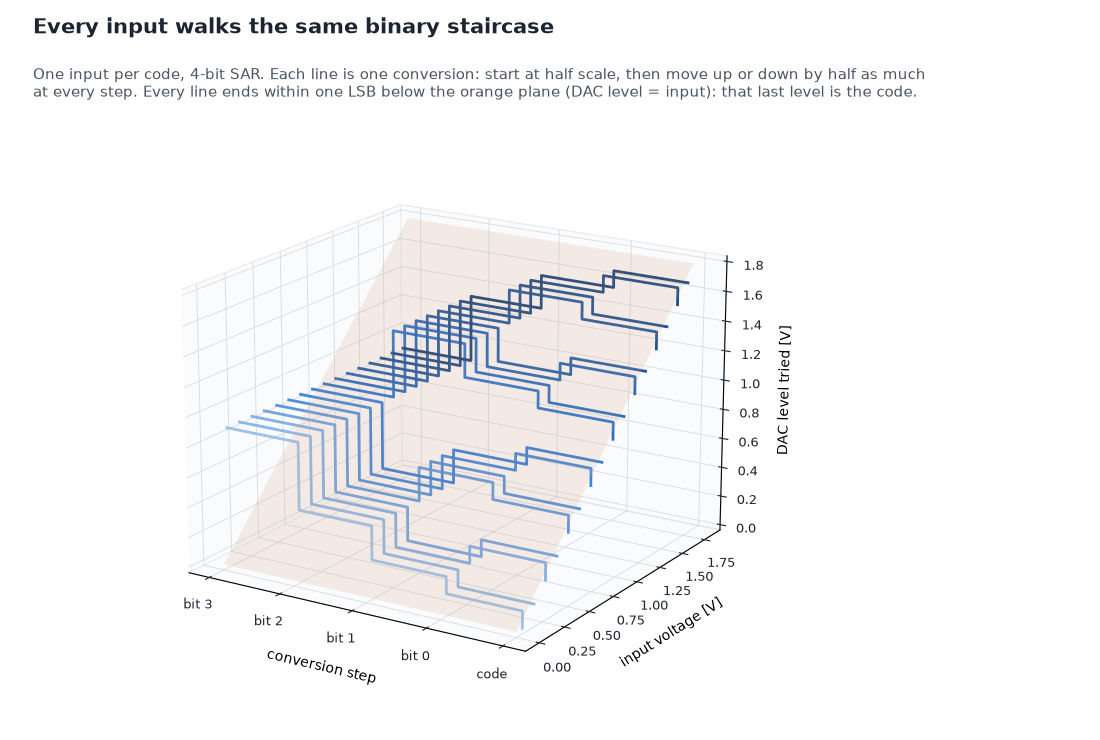

In [9]:
# @title Every input's binary search, from SARGen's behavioral model: one input per code of a 4-bit SAR.
m = SarModel(4, spec.vref)
fig = plt.figure(figsize=(11, 7.4))
ax = fig.add_axes([0.02, 0.02, 0.78, 0.82], projection="3d")
for code in range(2**m.bits):
    vin = (code + 0.5) * m.vref / 2**m.bits
    steps = m.trace(vin)                                   # sample, one trial per bit, done
    level = [s["vdac"] for s in steps if s["phase"] == "trial"] + [steps[-1]["vdac"]]
    x = np.repeat(np.arange(1, len(level) + 1), 2)[1:]     # draw steps, not ramps
    z = np.repeat(level, 2)[:-1]
    ax.plot(x, np.full(x.shape, vin), z, color=RAMP(code / (2**m.bits - 1)), lw=2)
X, V = np.meshgrid([1, m.bits + 1], [0, m.vref])
ax.plot_surface(X, V, V, color="#f2b48f", alpha=0.18, linewidth=0)          # where the DAC level equals the input
ax.set_xticks(range(1, m.bits + 2))
ax.set_xticklabels([f"bit {m.bits - 1 - i}" for i in range(m.bits)] + ["code"])
ax.set_xlabel("conversion step", labelpad=10); ax.set_ylabel("input voltage [V]", labelpad=8)
ax.set_zlabel("DAC level tried [V]", labelpad=6); ax.view_init(elev=18, azim=-58); style3d(ax)
heading(fig, "Every input walks the same binary staircase",
        "One input per code, 4-bit SAR. Each line is one conversion: start at half scale, then move up or down by half as "
        "much\nat every step. Every line ends within one LSB below the orange plane (DAC level = input): that last level "
        "is the code.")
render(fig)

## 3. Run the automated flow
`run_flow` executes all stages; each is explained in the following sections.
PDK characterization is cached in `build/char/` after the first run.

In [9]:
res = run_flow(spec, OUT, **FLOW_OPTS)

[   0.0s] 1/8 PDK characterization (A_VT, R_on, MIM)
[   0.0s] 2/8 sizing
[   0.0s] 3/8 netlist + single-conversion transient


[  18.6s] 4/8 comparator offset Monte Carlo (24 x 8 instances)


[ 158.3s] 5/8 ramp test: 32 hits/code, transistor level


[ 552.4s] 6/8 sine test: 128-point coherent FFT, transistor level


[ 659.8s] 7/8 mismatch Monte Carlo: behavioral model x 1000 (+0 SPICE seeds)


[ 661.4s] 8/8 animation + report


[ 667.2s] done -> build/4bit


## 4. PDK characterization (ngspice, SKY130 `tt` / `tt_mm`)
No textbook constants are used. The flow measures:
* **A<sub>VT</sub>** (Pelgrom [2]): 200 mismatch instances per geometry of diode-connected nfet/pfet in one netlist; A<sub>VT</sub> = sqrt(2) sigma(V<sub>GS</sub>) sqrt(WL).
* **R<sub>on</sub> x W** of transmission gates (worst case over the input range) and of the NMOS/PMOS DAC drivers -
  at nominal conditions *and* at the worst corners (ss/-40 C, ss/125 C, tt/-10 % supply). A standard-V<sub>t</sub> gate
  passing mid-rail at ss/-40 C is 36x weaker than at tt (both devices barely on), so the generator compares
  standard and **low-V<sub>t</sub>** (`nfet/pfet_01v8_lvt`) gates and picks the better one for the sampling switches.
* **MIM capacitance** per area and per perimeter (AC simulation of three geometries), and the **MIM matching
  coefficient** read from the PDK model card (`sigma(dC/C) = 2.8 %/sqrt(WL)`).

In [11]:
c = res["char"]
display(Markdown(f'''
| quantity | value |
|---|---|
| A_VT nfet / pfet | {c["avt_n_mVum"]:.2f} / {c["avt_p_mVum"]:.2f} mV um |
| TG (Wn=1, Wp=2) R_on W, std, tt 27 C | {c["ron_tg_ohm_um"]/1e3:.2f} kOhm um |
| TG R_on W, worst corner: std / lvt | {c["ron_tg_worst_ohm_um"]["std"]/1e3:.1f} / {c["ron_tg_worst_ohm_um"]["lvt"]/1e3:.1f} kOhm um ({c["ron_worst_where"]["tg_std"]}) |
| NMOS / PMOS driver R_on W | {c["ron_n_ohm_um"]:.0f} / {c["ron_p_ohm_um"]:.0f} Ohm um |
| MIM density | {c["mim_ca_fF_um2"]:.3f} fF/um^2 + {c["mim_cp_fF_um"]:.3f} fF/um perimeter |
| MIM matching | {c["mim_match_pct_um"]} % um |
'''))


| quantity | value |
|---|---|
| A_VT nfet / pfet | 7.38 / 9.18 mV um |
| TG (Wn=1, Wp=2) R_on W, std, tt 27 C | 12.11 kOhm um |
| TG R_on W, worst corner: std / lvt | 434.9 / 7.4 kOhm um (ss -40C 1.80V) |
| NMOS / PMOS driver R_on W | 669 / 3095 Ohm um |
| MIM density | 2.000 fF/um^2 + 0.165 fF/um perimeter |
| MIM matching | 2.8 % um |


The transmission-gate row of that table across the whole input range: both flavours at four PVT points. The gate is weakest near mid-rail, which is where the top-plate switch connects to V<sub>cm</sub>.

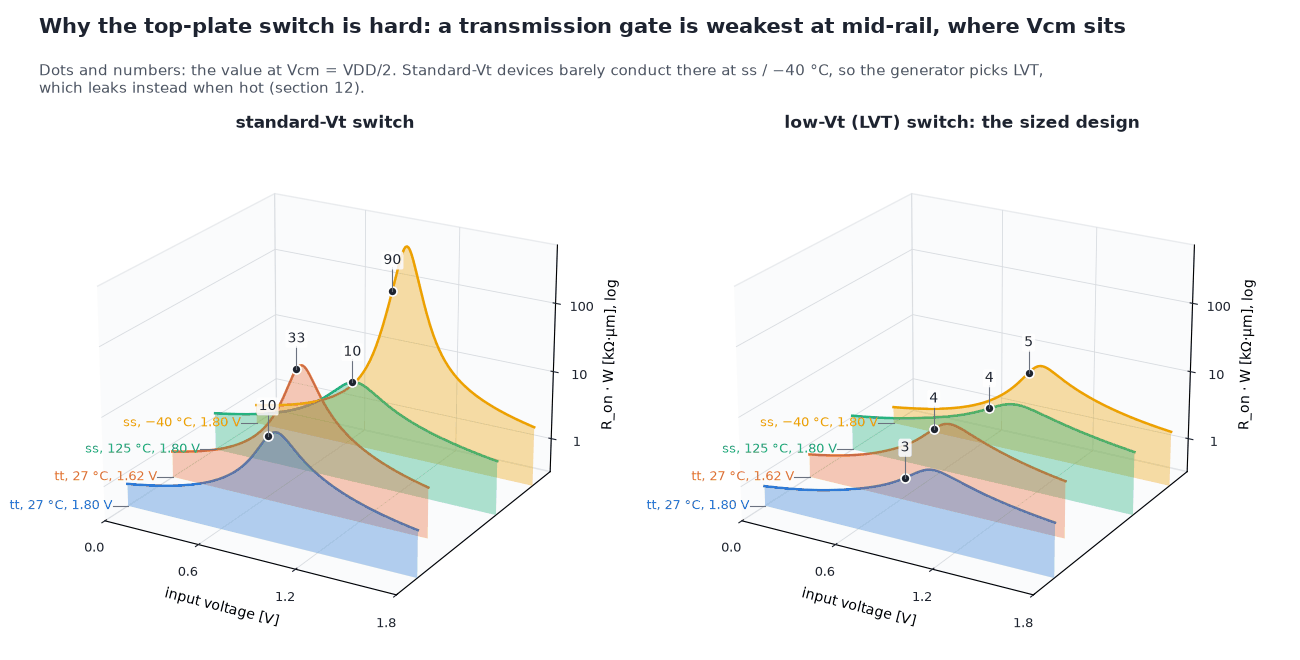

In [12]:
# @title Transmission-gate on-resistance across its input range: standard-Vt vs. LVT at four PVT points (ngspice DC sweeps of
# a 1 um / 2 um gate, 5 mV across it, from the characterization step; results/pdk/ron_curves.json).
curves = json.loads(Path("results/pdk/ron_curves.json").read_text())
top_z = math.log10(max(max(c["std_kohm_um"]) for c in curves.values())) + 0.2
fig = plt.figure(figsize=(13, 6.6))
for k, (key, title) in enumerate((("std_kohm_um", "standard-Vt switch"), ("lvt_kohm_um", "low-Vt (LVT) switch: the sized design"))):
    ax = fig.add_axes([0.0 + 0.49 * k, 0.02, 0.50, 0.78], projection="3d")
    for i, (lab, c) in enumerate(curves.items()):
        v, r = np.array(c["vin"]), np.array(c[key]); z = np.log10(r)
        ax.add_collection3d(Poly3DCollection([list(zip(v, np.full(v.shape, i), z)) + [(v[-1], i, -0.5), (v[0], i, -0.5)]],
                                             facecolor=CAT[i], edgecolor="none", alpha=0.35))
        ax.plot(v, np.full(v.shape, i), z, color=CAT[i], lw=1.8)
    ax.set_xlim(0, 1.8); ax.set_ylim(-0.5, len(curves) - 0.5); ax.set_zlim(-0.5, top_z)
    ax.set_xticks([0, 0.6, 1.2, 1.8]); ax.set_yticks([])
    ticks = [t for t in range(4) if t <= top_z]
    ax.set_zticks(ticks, [f"{10 ** t:g}" for t in ticks])
    ax.set_xlabel("input voltage [V]", labelpad=6); ax.set_zlabel("R_on · W [kΩ·µm], log", labelpad=4)
    ax.view_init(elev=22, azim=-60); style3d(ax)
    ax.set_title(title, fontsize=12.5, fontweight="bold", color=INK, pad=0)
    for i, (lab, c) in enumerate(curves.items()):
        v, r = np.array(c["vin"]), np.array(c[key])
        j = np.argmin(np.abs(v - c["vdd"] / 2))                 # Vcm = VDD/2: where the top-plate switch sits
        pin(fig, ax, v[j], i, math.log10(r[j]), f"{r[j]:.0f}", dy=0.035, fontsize=10,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
        pin(fig, ax, 0, i, -0.5, lab, dx=-0.012, marker=False, ha="right", va="center", fontsize=9, color=CAT[i])
heading(fig, "Why the top-plate switch is hard: a transmission gate is weakest at mid-rail, where Vcm sits",
        "Dots and numbers: the value at Vcm = VDD/2. Standard-Vt devices barely conduct there at ss / −40 °C, so the "
        "generator picks LVT,\nwhich leaks instead when hot (section 12).", y=0.95)
render(fig)

## 5. Specification-driven sizing
Each row is one design decision: the rule, the numbers that went in, and the result.

In [13]:
design = json.loads((OUT / "design.json").read_text())
display(Markdown(sizing_table_md(design)))

| block | rule | numbers | result |
|---|---|---|---|
| spec | LSB = Vref / 2^N | 1.8 V / 16 | **112.50 mV** |
| timing | Tclk = 1 / ((N + 2) * fs) | fs = 10 MS/s, 6 cycles | **16.67 ns (60.0 MHz)** |
| CDAC | sigma_DNL(mid-code) = sqrt(2^N - 1) * sigma_u <= DNL_3sigma / 3 | sigma_u <= 4.303 %, A_C = 2.8 %um | **side >= 0.65 um (matching)** |
| CDAC | kT/C: sqrt(kT / C_total) <= noise_lsb * LSB | C_total >= 0.0327 fF | **negligible at this resolution** |
| CDAC | Cu = Ca * s^2 + Cp * 4s (characterized MIM) | s = 2.00 um, limited by min. size | **Cu = 9.32 fF, C_total = 149.1 fF** |
| comparator | offset only shifts the transfer curve here (no DNL/INL): spec = offset error | 3 sigma_os <= 1.0 LSB | **sigma_os <= 37.50 mV** |
| comparator | sigma_os ~ A_VT / sqrt(W L) <= offset_3sigma * LSB / 3 | A_VT = 7.38 mVum, target 37.50 mV | **W L >= 0.039 um^2 -> W/L = 2.0/0.3 (est. 9.52 mV)** |
| comparator | pre-amplifier needed if W L > 20 um^2 (input cap / kick-back) | W L = 0.04 um^2 | **no - StrongARM alone** |
| comparator | tail = 1.5 W_in, latch = W_in / 2, reset / inverters fixed |  | **tail 3.0, nlatch 1.0, platch 1.0 um** |
| sampling | TG device flavour = lowest worst-case R_on W (ss/-40C, ss/125C, tt/-10% supply) | std: 434.9 kOhm um, lvt: 7.4 kOhm um, mix: 13.3 kOhm um, mixp: 112.4 kOhm um, mixl: 262.7 kOhm um, lvtp5: 12.7 kOhm um, lvtp7: 17.9 kOhm um, lvtp10: 23.9 kOhm um | **lvt transistors** |
| sampling | tau = T_track / ln(2^N / settle_lsb); 1/4 bit switch, 3/4 top switch | T_track = 14.17 ns, tau <= 3406 ps | **R_unit <= 91.4 kOhm, R_top <= 17136 Ohm** |
| sampling | W_n = (R_on W)_TG,worst / R  (Wp = 2 Wn), bit-i switch = 2^i units | worst (R_on W) = 7.45 kOhm um (ss -40C 1.80V) | **unit TG 0.45/0.90 um** |
| sampling | top-plate switch: sized at Vcm; least hot-leakage flavour among those <= 4x the narrowest (plate droop per conversion, ff 125C, fs 125C, plate Vref/2^(k+1) from Vcm while bit k is tried; budget 0.25 LSB) | std: 5.3 um, 0.53 LSB, lvt: 0.5 um, 0.97 LSB, mix: 0.8 um, 1.6 LSB, mixp: 0.5 um, 0.05 LSB, mixl: 0.7 um, 9.3e-05 LSB, lvtp5: 0.5 um, 0.17 LSB, lvtp7: 0.5 um, 0.05 LSB, lvtp10: 0.5 um, 0.021 LSB | **mixl: top TG 0.65/1.30 um (10.38 kOhm um at Vcm, 0.000 LSB)** |
| DAC driver | tau = 0.45 Tclk / ln(2^N / settle_lsb), per unit cap (binary scaled) | tau <= 1803 ps, R_unit <= 96.8 kOhm | **unit NMOS 0.45 um, unit PMOS 0.45 um** |

The unit-capacitor row of that table, over the generator's whole range: the same rule evaluated for every resolution and DNL target.

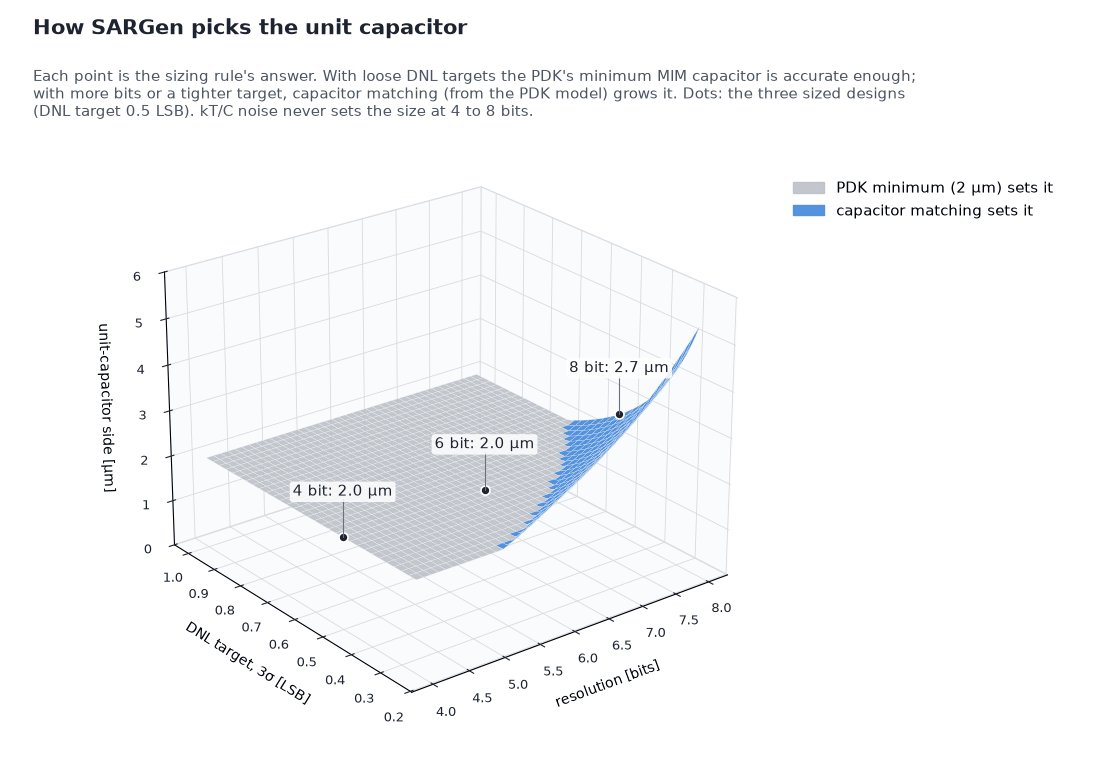

In [14]:
# @title The unit-capacitor rule of sargen/sizing.py, evaluated over the generator's whole range.
from sargen.pdk import MIM_MIN_SIDE
ch = json.loads(Path("results/8bit/summary.json").read_text())["char"]       # PDK characterization (section 4)
a_c, ca, cp = ch["mim_match_pct_um"] / 100, ch["mim_ca_fF_um2"] * 1e-15, ch["mim_cp_fF_um"] * 1e-15

def unit_side(bits, dnl3, s=SarSpec(bits=8)):
    # side = max(matching, kT/C, PDK minimum); returns (side in um, what sets it)
    match = a_c * 3 * math.sqrt(2**bits - 1) / dnl3
    c_ktc = 1.380649e-23 * (s.temp + 273.15) / (s.noise_lsb * s.vref / 2**bits) ** 2
    ktc = (-4 * cp + math.sqrt(16 * cp**2 + 4 * ca * c_ktc / 2**bits)) / (2 * ca)
    return max([(match, "matching"), (ktc, "kT/C"), (MIM_MIN_SIDE, "min")])

B, D = np.meshgrid(np.linspace(4, 8, 81), np.linspace(0.25, 1.0, 61))
S = np.vectorize(lambda b, d: unit_side(b, d)[0])(B, D)
lim = np.vectorize(lambda b, d: unit_side(b, d)[1])(B, D)
colors = {"min": to_rgba(GREY, 0.85), "matching": to_rgba(BLUE, 0.80), "kT/C": to_rgba(ORANGE, 0.85)}
names = {"min": "PDK minimum (2 µm) sets it", "matching": "capacitor matching sets it", "kT/C": "kT/C noise sets it"}
fig = plt.figure(figsize=(11, 7.6))
ax = fig.add_axes([0.02, 0.02, 0.76, 0.82], projection="3d")
ax.plot_surface(B, D, S, facecolors=np.array([[colors[l] for l in row] for row in lim]), rstride=2, cstride=2,
                linewidth=0.15, edgecolor="white", shade=False)
for b in (4, 6, 8):
    s = json.loads(Path(f"results/{b}bit/summary.json").read_text())["design"]["cu"]["side"]
ax.set_xlabel("resolution [bits]", labelpad=8); ax.set_ylabel("DNL target, 3σ [LSB]", labelpad=8)
ax.set_zlabel("unit-capacitor side [µm]", labelpad=6); ax.set_zlim(0, np.ceil(S.max()))
ax.view_init(elev=24, azim=-128); style3d(ax)
for b in (4, 6, 8):
    s = json.loads(Path(f"results/{b}bit/summary.json").read_text())["design"]["cu"]["side"]
    pin(fig, ax, b, 0.5, s, f"{b} bit: {s:.1f} µm", dy=0.05, fontsize=10.5,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
used = [k for k in names if (lim == k).any()]
fig.legend(handles=[Patch(color=colors[k], label=names[k]) for k in used], loc="upper right",
           bbox_to_anchor=(0.97, 0.78), frameon=False, fontsize=11)
heading(fig, "How SARGen picks the unit capacitor",
        "Each point is the sizing rule's answer. With loose DNL targets the PDK's minimum MIM capacitor is accurate "
        "enough;\nwith more bits or a tighter target, capacitor matching (from the PDK model) grows it. Dots: the "
        "three sized designs\n(DNL target 0.5 LSB)." + ("" if "kT/C" in used else " kT/C noise never sets the size at 4 to 8 bits."))
render(fig)

## 6. Generated netlist and a single conversion
The testbench below is written by `sargen.netlist`. The SAR logic is built from SKY130 standard cells
(`sky130_fd_sc_hd` DFF with reset, OR, NAND/NOR sized by fan-out); only the clock phases come from ideal sources.
Watch the top plate: it jumps with every bit trial and converges back to V<sub>cm</sub>, the binary search in silicon.

Three switching-order rules keep the top plate inside the supply rails, so no switch junction is ever
forward-biased (each one was found by the flow's own simulations, see the git history):
1. **MSB first:** when sampling ends, the MSB plate goes to V<sub>ref</sub> immediately.
2. **Track, then ground:** the other plates keep tracking V<sub>in</sub> until the MSB has settled and only then go to
   ground. Grounding them first pulled the top plate to V<sub>cm</sub> - V<sub>in</sub> (-0.85 V, 7 missing codes at 8 bit);
   letting them float instead pushed it to V<sub>cm</sub> + V<sub>ref</sub> - V<sub>in</sub> (2.6 V, INL bow).
3. **Release before set:** a rejected bit returns to ground (trial ends at 0.92 T<sub>clk</sub>, decision latched at
   0.80 T<sub>clk</sub>) before the next bit is tried; otherwise the top plate glitches by one bit weight every cycle.

* SAR ADC 4-bit testbench (generated by sargen)
.lib /foss/pdks/sky130A/libs.tech/ngspice/sky130.lib.spice tt
.include /foss/pdks/sky130A/libs.ref/sky130_fd_sc_hd/spice/sky130_fd_sc_hd.spice
.temp 27.0
.option method=gear
.subckt strongarm inp inn clk qp qn vdd vss
XMt tail clk vss vss sky130_fd_pr__nfet_01v8 L=0.15 W=3 nf=1 ad=0.87 as=0.87 pd=6.58 ps=6.58 nrd=0.09667 nrs=0.09667 sa=0 sb=0 sd=0 mult=1 m=1
XMi1 xp inp tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMi2 xn inn tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMn1 outn outp xp vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMn2 outp outn xn vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMp1 outn outp vdd vdd sky130_fd_pr__pf

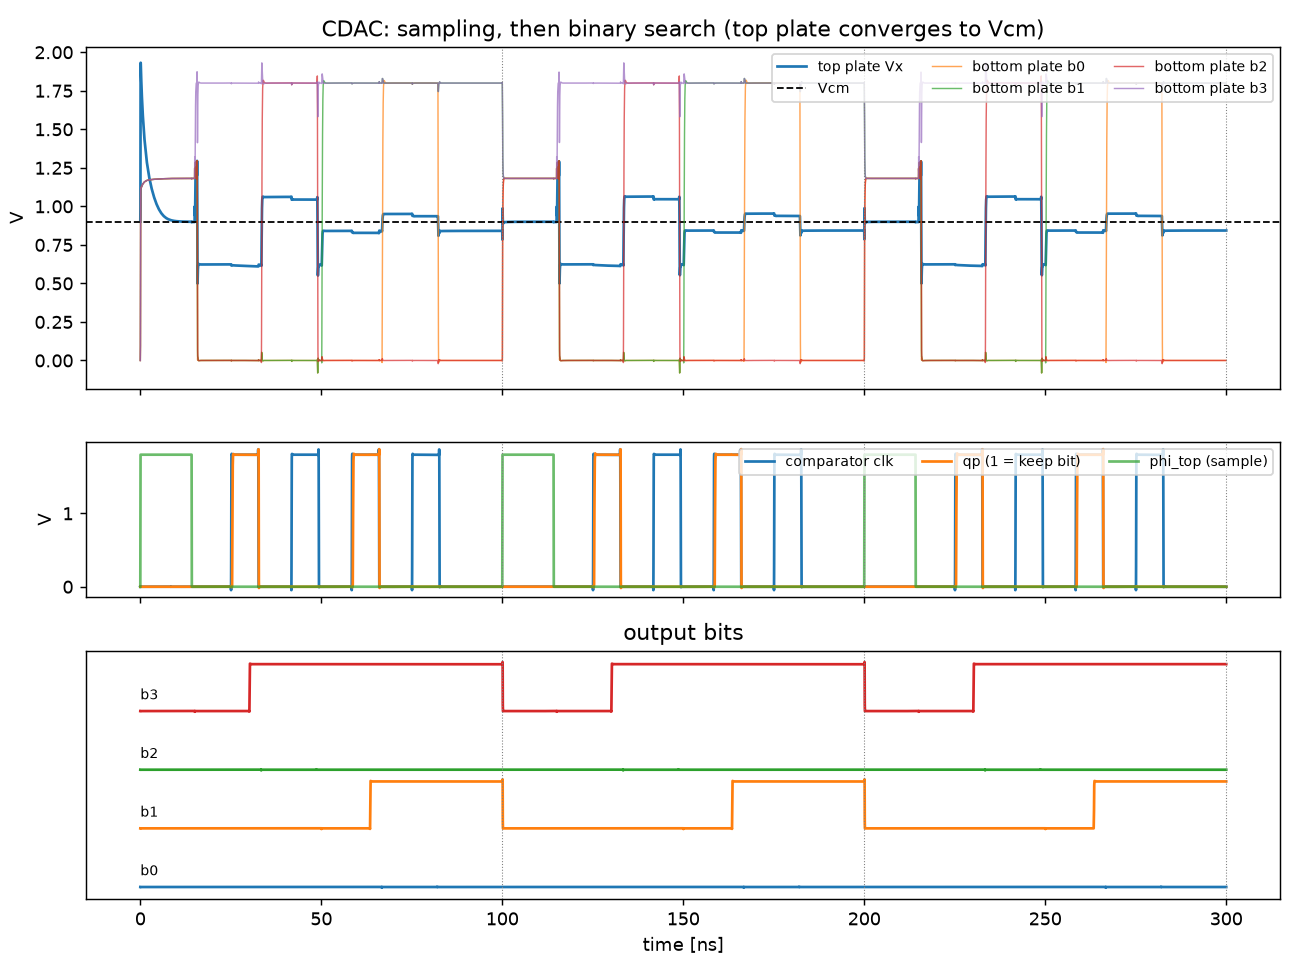

**Key insight:** the top plate steps once per bit trial and settles back towards V<sub>cm</sub>; the 4 decisions spell code 10 for V<sub>in</sub> = 1.181 V - exactly the ideal code.

In [15]:
tb = (OUT / f"sar_adc_{BITS}b_tb.spice").read_text().splitlines()
print("\n".join(tb[:12] + ["..."] + [l for l in tb if l.startswith(("* ----", "abr", "aff"))][:20]))
print(f"\nVin = {res['single']['vin']:.4f} V -> code {res['single']['code']} (ideal {res['single']['ideal']})")
display(Image(filename=str(OUT / "waveforms.png")))
sg = res["single"]
display(Markdown(f"**Key insight:** the top plate steps once per bit trial and settles back towards V<sub>cm</sub>; the "
                 f"{BITS} decisions spell code {sg['code']} for V<sub>in</sub> = {sg['vin']:.3f} V - "
                 f"{'exactly the ideal code' if sg['code'] == sg['ideal'] else 'ideal: ' + str(sg['ideal'])}."))

## 7. Comparator offset Monte Carlo
192 StrongARM instances with independent SKY130 mismatch are swept with a slow ramp. In this single-ended,
conventional-switching SAR the comparator offset only shifts the whole transfer curve (offset error); it does
not create DNL. That is why a small, fast comparator is enough at low resolution.

sigma_os = 8.64 mV  (0.077 LSB), mean = 0.83 mV, n = 192


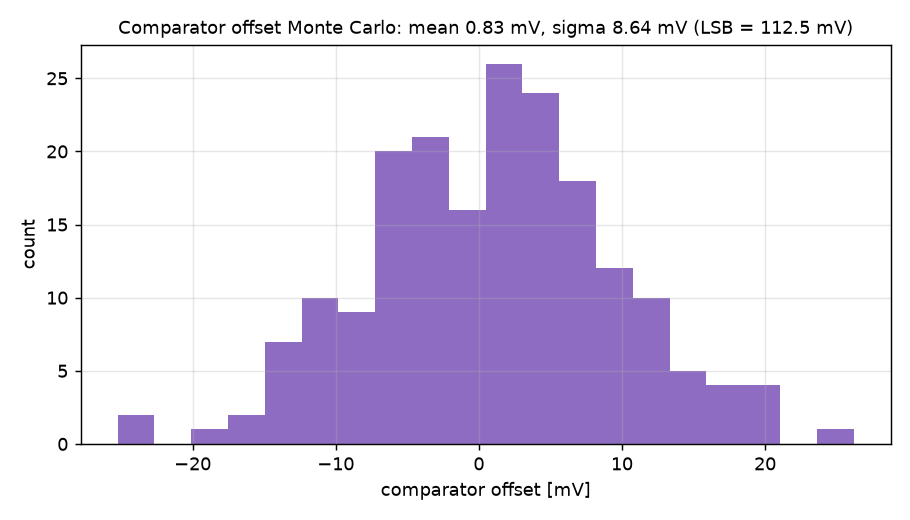

**Key insight:** 3 sigma = 0.23 LSB against a target of 1 LSB. In this single-ended SAR the offset only shifts the whole transfer curve; it does not create DNL.

In [16]:
o = res["comparator_offset"]
print(f"sigma_os = {o['sigma']*1e3:.2f} mV  ({o['sigma']/spec.lsb:.3f} LSB), mean = {o['mean']*1e3:.2f} mV, n = {o['n']}")
display(Image(filename=str(OUT / "comparator_offset.png")))
display(Markdown(f"**Key insight:** 3 sigma = {3 * o['sigma'] / spec.lsb:.2f} LSB against a target of "
                 f"{spec.offset_3sigma_lsb:g} LSB. In this single-ended SAR the offset only shifts the whole transfer curve; "
                 "it does not create DNL."))

**7b. Checking the comparator design with gm/Id.** The sizing step chose the input pair from its offset target (Pelgrom [2]). These two figures check the result from the device side: where the pair actually operates while it integrates, and whether offset, noise and decision speed meet their targets at every resolution.

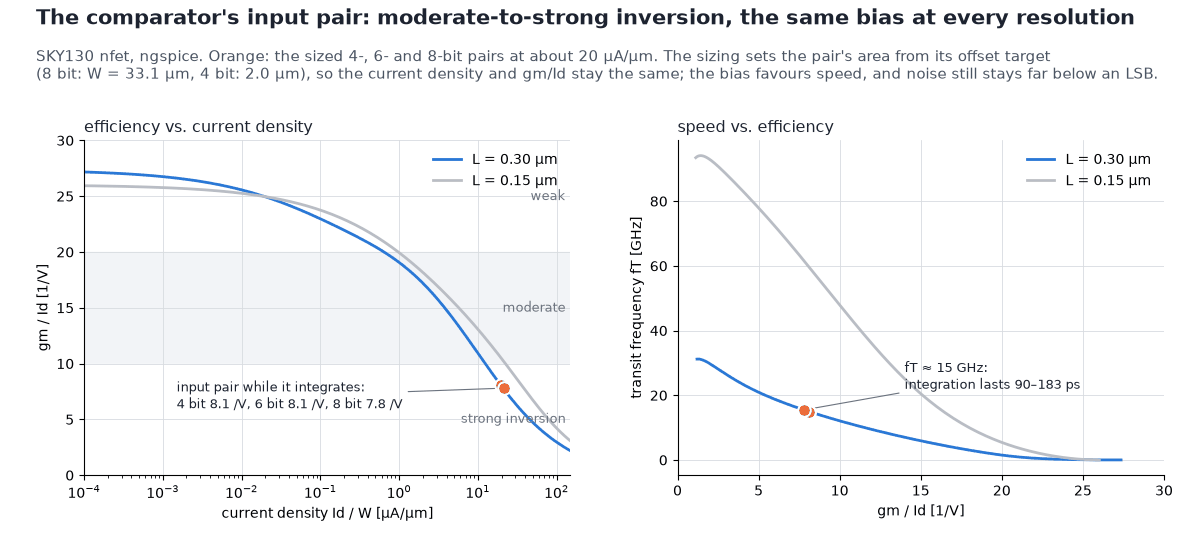

In [17]:
# @title gm/Id check of the StrongARM input pair: (1) SKY130 nfet curves from an ngspice DC sweep (W = 1 um, VDS = VDD/2,
# the comparator's two channel lengths); (2) where each sized comparator's input pair actually operates while it
# integrates: mean gm and Id over the integration window of a transient (sargen/noise.py).
from sargen import spice, noise
from sargen.pdk import NFET, lib_line, mos
dev = lambda k: f"@m.xm{k}.msky130_fd_pr__nfet_01v8"
vecs = " ".join(f"{dev(k)}[{q}]" for k in (1, 2) for q in ("gm", "id", "cgg"))
net = "\n".join(["* gm/Id sweep", lib_line("tt"), f"Vd d 0 {spec.vdd / 2}", "Vg g 0 0",
                 mos("M1", "d", "g", "0", "0", NFET, 1.0, 0.30), mos("M2", "d", "g", "0", "0", NFET, 1.0, 0.15),
                 ".control", f"save {vecs}", f"dc Vg 0 {spec.vdd} 0.005", "set wr_singlescale", "set wr_vecnames",
                 f"wrdata gmid.txt {vecs}", "quit", ".endc", ".end"])
w = spice.read_wrdata(spice.run(net, OUT / "gmid") / "gmid.txt")
curves = {}
for k, L in ((1, 0.30), (2, 0.15)):
    gm, i_d, cgg = (w[f"{dev(k)}[{q}]"] for q in ("gm", "id", "cgg"))
    ok = i_d > 1e-12
    curves[L] = dict(idw=i_d[ok] * 1e6, gmid=gm[ok] / i_d[ok], ft=gm[ok] / (2 * np.pi * cgg[ok]) / 1e9)
ops = {}
for b in (4, 6, 8):
    d = json.loads(Path(f"results/{b}bit/summary.json").read_text())["design"]
    r = noise.integration(SarSpec(bits=b), d, OUT / f"gmid_op{b}")
    c = curves[d["cmp"]["l_in"]]
    gmid = r["gm"] / r["id"]
    ops[b] = dict(gmid=gmid, idw=r["id"] / d["cmp"]["w_in"] * 1e6, w=d["cmp"]["w_in"], t_int=r["t_int"],
                  ft=np.interp(gmid, c["gmid"][::-1], c["ft"][::-1]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.4))
fig.subplots_adjust(left=0.07, right=0.97, top=0.74, bottom=0.12, wspace=0.22)
for ax in (a1, a2):
    for lo, hi, name in ((20, 30, "weak"), (10, 20, "moderate"), (0, 10, "strong inversion")):
        if ax is a1:
            ax.axhspan(lo, hi, color="#f2f4f7" if name == "moderate" else "white", zorder=0)
            ax.text(1.3e2, (lo + hi) / 2, name, va="center", ha="right", fontsize=9.5, color=MUTED)
for L, col in ((0.30, BLUE), (0.15, GREY)):
    c = curves[L]
    a1.plot(c["idw"], c["gmid"], color=col, lw=2, label=f"L = {L:.2f} µm")
    a2.plot(c["gmid"], c["ft"], color=col, lw=2, label=f"L = {L:.2f} µm")
for k, (b, o) in enumerate(ops.items()):
    a1.plot(o["idw"], o["gmid"], "o", ms=9, color=ORANGE, mec="white", mew=1.5, zorder=5)
    a2.plot(o["gmid"], o["ft"], "o", ms=9, color=ORANGE, mec="white", mew=1.5, zorder=5)
a1.annotate("input pair while it integrates:\n" + ", ".join(f"{b} bit {o['gmid']:.1f} /V" for b, o in ops.items()),
            (ops[8]["idw"], ops[8]["gmid"]), xytext=(1.5e-3, 6), fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
a2.annotate(f"fT ≈ {ops[8]['ft']:.0f} GHz:\nintegration lasts {min(o['t_int'] for o in ops.values()) * 1e12:.0f}–"
            f"{max(o['t_int'] for o in ops.values()) * 1e12:.0f} ps", (ops[8]["gmid"], ops[8]["ft"]), xytext=(14, 22),
            fontsize=9.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
a1.set_xscale("log"); a1.set_xlim(1e-4, 1.5e2); a1.set_ylim(0, 30)
a1.set_xlabel("current density Id / W [µA/µm]"); a1.set_ylabel("gm / Id [1/V]")
a2.set_xlim(0, 30); a2.set_xlabel("gm / Id [1/V]"); a2.set_ylabel("transit frequency fT [GHz]")
for ax, t in ((a1, "efficiency vs. current density"), (a2, "speed vs. efficiency")):
    ax.set_title(t, loc="left", fontsize=11.5, color=INK); ax.grid(color=GRID, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=10, loc="upper right")
heading(fig, "The comparator's input pair: moderate-to-strong inversion, the same bias at every resolution",
        f"SKY130 nfet, ngspice. Orange: the sized 4-, 6- and 8-bit pairs at about {np.mean([o['idw'] for o in ops.values()]):.0f} "
        "µA/µm. The sizing sets the pair's area from its offset target\n(8 bit: W = "
        f"{ops[8]['w']:.1f} µm, 4 bit: {ops[4]['w']:.1f} µm), so the current density and gm/Id stay the same; the bias favours "
        "speed, and noise still stays far below an LSB.", y=0.955)
render(fig)

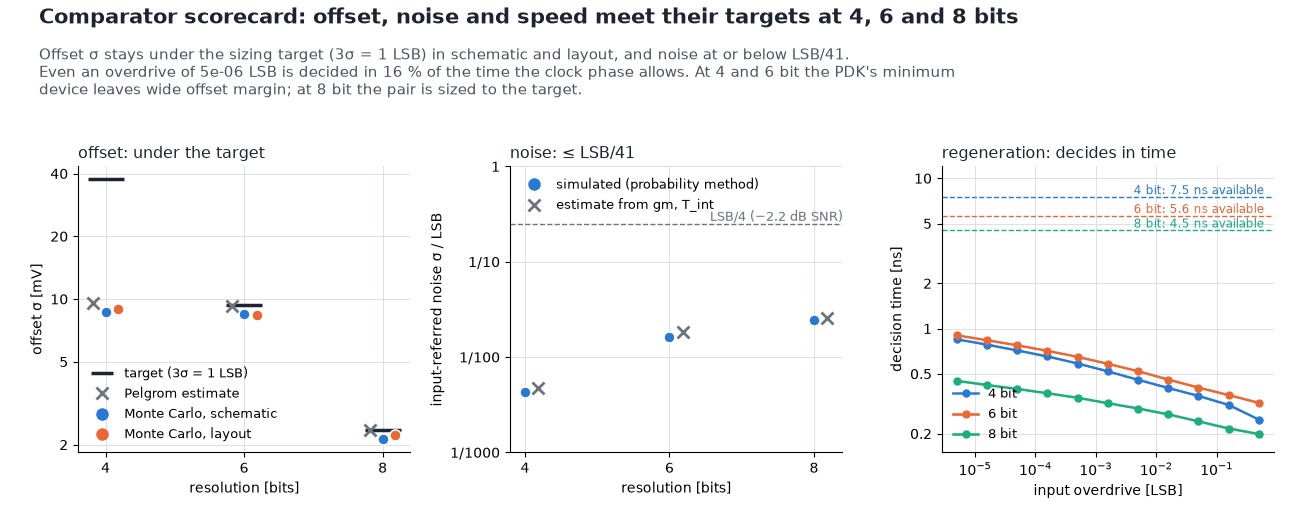

In [18]:
# @title Comparator scorecard at 4, 6 and 8 bit: offset (sizing target, Pelgrom estimate, Monte Carlo on the schematic and on
# the layout extraction), noise (the probability-method study), and regeneration time: a transient in which the
# input overdrive shrinks from LSB/2 to 1e-5 of that, one decision per clock cycle.
def md_rows(path):
    lines = [l for l in Path(path).read_text().splitlines() if l.startswith("|")]
    head = [h.strip() for h in lines[0].strip("|").split("|")]
    return [dict(zip(head, [c.strip() for c in l.strip("|").split("|")])) for l in lines[2:]]

def regeneration(b, steps=11):
    sp = SarSpec(bits=b); t = sp.tclk
    d = json.loads(Path(f"results/{b}bit/summary.json").read_text())["design"]
    vd = sp.lsb / 2 * np.logspace(0, -5, steps)
    pwl = " ".join(f"{k * t:.6g} {sp.vcm + v:.12g} {(k + 1) * t - 1e-12:.6g} {sp.vcm + v:.12g}" for k, v in enumerate(vd))
    net = "\n".join(["* regeneration", lib_line("tt"), strongarm_subckt(d["cmp"]), f"Vdd vdd 0 {sp.vdd}",
                     f"Vcm vcm 0 {sp.vcm}", f"Vp inp 0 PWL({pwl})",
                     f"Vclk clk 0 PULSE(0 {sp.vdd} {0.5 * t:.6g} 50p 50p {0.45 * t - 50e-12:.6g} {t:.6g})",
                     "Xc inp vcm clk qp qn vdd 0 strongarm", ".save v(qp) v(qn)", f".tran {t / 4000:.4g} {steps * t:.6g}",
                     ".control", "set wr_singlescale", "set wr_vecnames", "run", "wrdata wave.txt v(qp) v(qn)", "quit",
                     ".endc", ".end"])
    w = spice.read_wrdata(spice.run(net, OUT / f"regen{b}") / "wave.txt")
    delay = []
    for k in range(steps):                                  # clock edge -> outputs apart by VDD/2
        t0 = (k + 0.5) * t; m = (w["time"] > t0) & (w["time"] < t0 + 0.45 * t)
        hit = np.abs(w["qp"][m] - w["qn"][m]) > sp.vdd / 2
        delay.append((w["time"][m][np.argmax(hit)] - t0) if hit.any() else np.nan)
    return vd / sp.lsb, np.array(delay), 0.45 * t

from sargen import spice
from sargen.netlist import strongarm_subckt
from sargen.pdk import lib_line
mcl, nz = md_rows("results/comparator_mc_layout.md"), md_rows("results/comparator_noise.md")
bits = [4, 6, 8]
fig, axs = plt.subplots(1, 3, figsize=(13, 5.2))
fig.subplots_adjust(left=0.06, right=0.98, top=0.68, bottom=0.13, wspace=0.30)
ax = axs[0]                                                  # offset
for b in bits:
    cmp_ = json.loads(Path(f"results/{b}bit/summary.json").read_text())["design"]["cmp"]
    sch = next(r for r in mcl if r["bits"] == str(b) and r["case"] == "schematic")
    lay = next(r for r in mcl if r["bits"] == str(b) and r["case"].startswith("layout"))
    ax.plot(b, cmp_["sigma_os_target"] * 1e3, "_", ms=26, mew=2.5, color=INK)
    ax.plot(b - 0.18, cmp_["sigma_os_est"] * 1e3, "x", ms=8, mew=2, color=MUTED)
    ax.plot(b, float(sch["sigma [mV]"]), "o", ms=8, color=BLUE, mec="white", mew=1.2)
    ax.plot(b + 0.18, float(lay["sigma [mV]"]), "o", ms=8, color=ORANGE, mec="white", mew=1.2)
ax.set_yscale("log"); ax.set_yticks([2, 5, 10, 20, 40], ["2", "5", "10", "20", "40"]); ax.minorticks_off()
ax.set_ylabel("offset σ [mV]"); ax.set_title("offset: under the target", loc="left", fontsize=11.5, color=INK)
ax.legend(handles=[plt.Line2D([], [], ls="", marker="_", ms=16, mew=2.5, color=INK, label="target (3σ = 1 LSB)"),
                   plt.Line2D([], [], ls="", marker="x", ms=8, mew=2, color=MUTED, label="Pelgrom estimate"),
                   plt.Line2D([], [], ls="", marker="o", ms=8, color=BLUE, label="Monte Carlo, schematic"),
                   plt.Line2D([], [], ls="", marker="o", ms=8, color=ORANGE, label="Monte Carlo, layout")],
          frameon=False, fontsize=9, loc="lower left")
ax = axs[1]                                                  # noise relative to the LSB
for b in bits:
    r = next(r for r in nz if r["bits"] == str(b))
    lsb_uv = float(r["LSB [mV]"]) * 1e3
    ax.plot(b, float(r["sigma, simulated [uV]"]) / lsb_uv, "o", ms=8, color=BLUE, mec="white", mew=1.2)
    ax.plot(b + 0.18, float(r["sigma, estimate [uV]"]) / lsb_uv, "x", ms=8, mew=2, color=MUTED)
ax.axhline(0.25, color=MUTED, lw=1, ls="--"); ax.text(8.4, 0.25, "LSB/4 (−2.2 dB SNR)", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.set_yscale("log"); ax.set_ylim(1e-3, 1); ax.set_ylabel("input-referred noise σ / LSB")
ax.set_yticks([1e-3, 1e-2, 1e-1, 1], ["1/1000", "1/100", "1/10", "1"]); ax.minorticks_off()
ax.set_title("noise: ≤ LSB/41", loc="left", fontsize=11.5, color=INK)
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=8, color=BLUE, label="simulated (probability method)"),
                   plt.Line2D([], [], ls="", marker="x", ms=8, mew=2, color=MUTED, label="estimate from gm, T_int")],
          frameon=False, fontsize=9, loc="upper left")
ax = axs[2]                                                  # regeneration
worst = []
for k, b in enumerate(bits):
    x, dl, avail = regeneration(b)
    ax.plot(x, dl * 1e9, "o-", ms=5, lw=1.8, color=CAT[k], label=f"{b} bit")
    ax.axhline(avail * 1e9, color=CAT[k], lw=1, ls="--")
    ax.text(0.6, avail * 1e9, f"{b} bit: {avail * 1e9:.1f} ns available", ha="right", va="bottom", fontsize=8.5, color=CAT[k])
    worst.append(np.nanmax(dl) / avail); smallest = x.min()
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("input overdrive [LSB]"); ax.set_ylabel("decision time [ns]")
ax.set_yticks([0.2, 0.5, 1, 2, 5, 10], ["0.2", "0.5", "1", "2", "5", "10"]); ax.set_ylim(0.15, 12); ax.minorticks_off()
ax.set_title("regeneration: decides in time", loc="left", fontsize=11.5, color=INK)
ax.legend(frameon=False, fontsize=9, loc="lower left")
for ax in axs:
    ax.set_xticks(bits) if ax is not axs[2] else None
    ax.grid(color=GRID, lw=0.6, which="major"); ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=10)
axs[0].set_xlabel("resolution [bits]"); axs[1].set_xlabel("resolution [bits]")
heading(fig, "Comparator scorecard: offset, noise and speed meet their targets at 4, 6 and 8 bits",
        "Offset σ stays under the sizing target (3σ = 1 LSB) in schematic and layout, and noise at or below LSB/41."
        f"\nEven an overdrive of {smallest:.0e} LSB is decided in {max(worst) * 100:.0f} % of the time the clock phase allows. "
        "At 4 and 6 bit the PDK's minimum\ndevice leaves wide offset margin; at 8 bit the pair is sized to the target.", y=0.955)
render(fig)

## 8. Static linearity: ramp + code-density (histogram) test [4]
A slow ramp that slightly over-drives both ends is applied to the transistor-level ADC. The number of hits per
code gives DNL; its running sum gives INL (end-point fit).

max|DNL| = 0.095 LSB, max|INL| = 0.085 LSB, missing codes = 0, offset = -0.155 LSB, gain error = -0.021 LSB


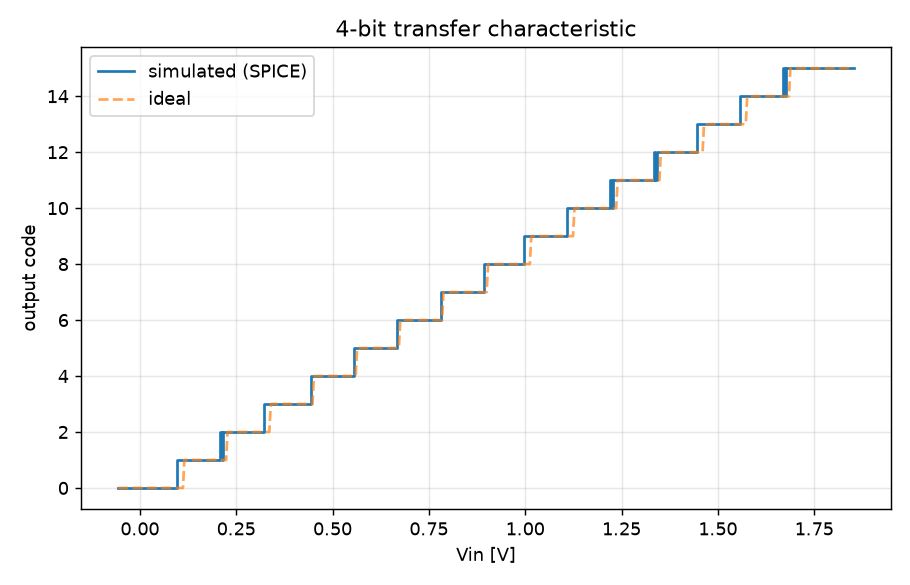

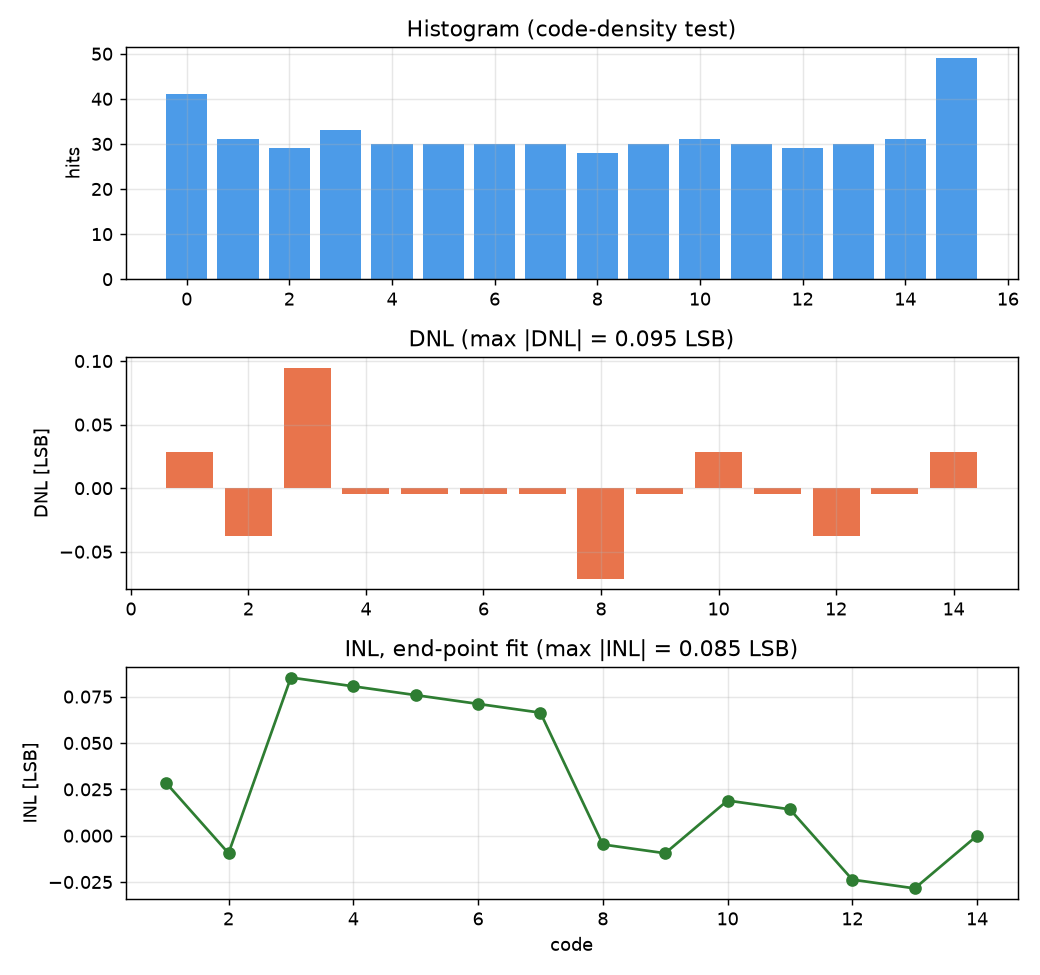

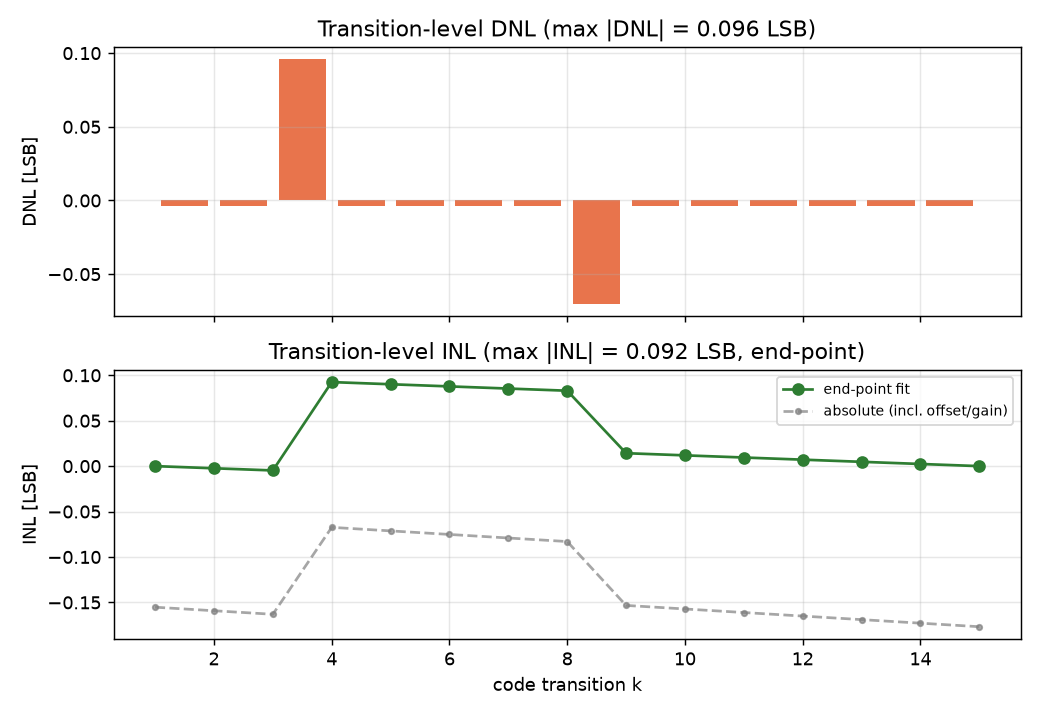

**Key insight:** 0 missing codes and max |DNL| = 0.09 LSB against the 0.5 LSB target: the transistor-level converter is linear to well within one LSB.

In [19]:
s = res["static"]
print(f"max|DNL| = {s['dnl_max']:.3f} LSB, max|INL| = {s['inl_max']:.3f} LSB, missing codes = {s['missing_codes']}, "
      f"offset = {s['offset_lsb']:.3f} LSB, gain error = {s['gain_error_lsb']:.3f} LSB")
display(Image(filename=str(OUT / "transfer.png")))
display(Image(filename=str(OUT / "inl_dnl_histogram.png")))
display(Image(filename=str(OUT / "inl_dnl_transitions.png")))
display(Markdown(f"**Key insight:** {s['missing_codes']} missing codes and max |DNL| = {s['dnl_max']:.2f} LSB against the "
                 f"{spec.dnl_3sigma_lsb:g} LSB target: the transistor-level converter is linear to well within one LSB."))

## 9. Dynamic performance: coherent FFT, ENOB
A full-scale sine with a prime number of cycles in the record (coherent sampling, no window) is converted at
transistor level. ENOB = (SNDR - 1.76 dB) / 6.02 [4].

SNDR 25.68 dB, SFDR 35.7 dB, ENOB 3.97 bit (ideal 4-bit quantizer on the same samples: 3.97 bit)
Power 13.88 uW, 1.388 pJ/conv, Walden FoM 88.4 fJ/conv-step


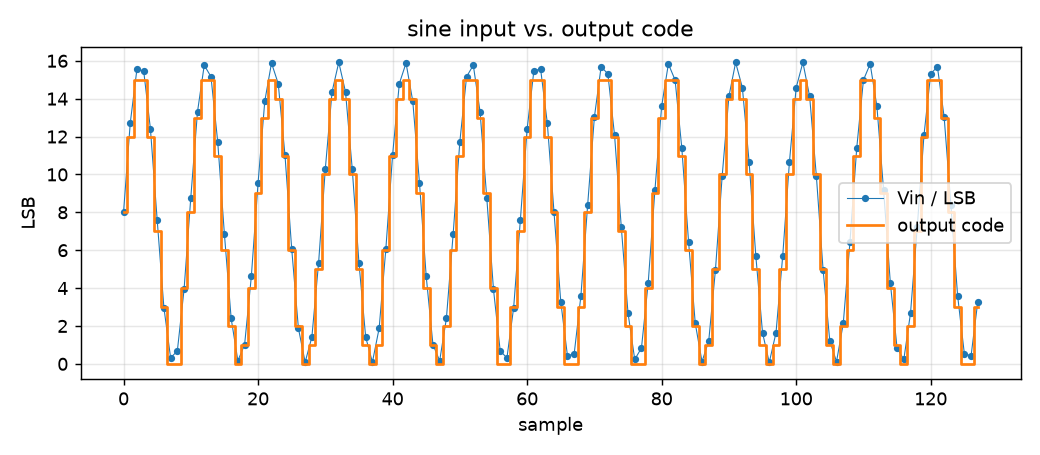

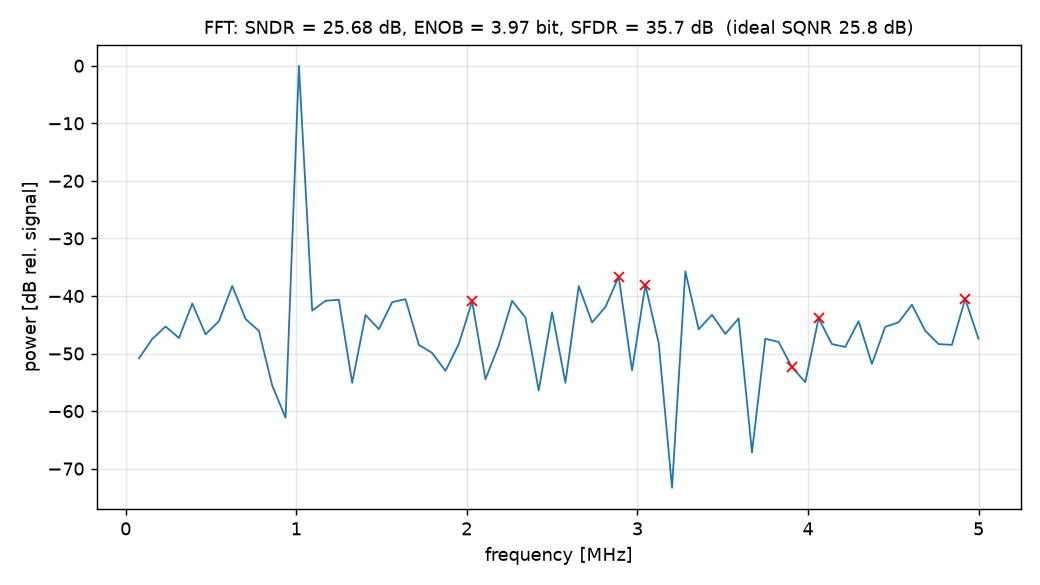

**Key insight:** ENOB 3.97 bit against 3.97 bit for an ideal 4-bit quantizer on the same samples: the circuit costs 0.00 bit.

In [20]:
d, p = res["dynamic"], res["power"]
print(f"SNDR {d['sndr_db']:.2f} dB, SFDR {d['sfdr_db']:.1f} dB, ENOB {d['enob']:.2f} bit "
      f"(ideal {BITS}-bit quantizer on the same samples: {d['ideal_model_enob']:.2f} bit)")
print(f"Power {p['p_total']*1e6:.2f} uW, {p['energy_per_conv']*1e12:.3f} pJ/conv, Walden FoM {p['walden_fom_J']*1e15:.1f} fJ/conv-step")
display(Image(filename=str(OUT / "sine_samples.png")))
display(Image(filename=str(OUT / "fft.png")))
display(Markdown(f"**Key insight:** ENOB {d['enob']:.2f} bit against {d['ideal_model_enob']:.2f} bit for an ideal "
                 f"{BITS}-bit quantizer on the same samples: the circuit costs {max(0, d['ideal_model_enob'] - d['enob']):.2f} bit."))

**The 8-bit design up to Nyquist** (fixed design, schematic, `studies/coverage8.py`): the spectrum at six input frequencies from 0.02 f<sub>s</sub> to 0.49 f<sub>s</sub>. With a 128-point FFT, ENOB is resolved to about ±0.1 bit, so 8.03 at the lowest frequency is within that resolution of 8.

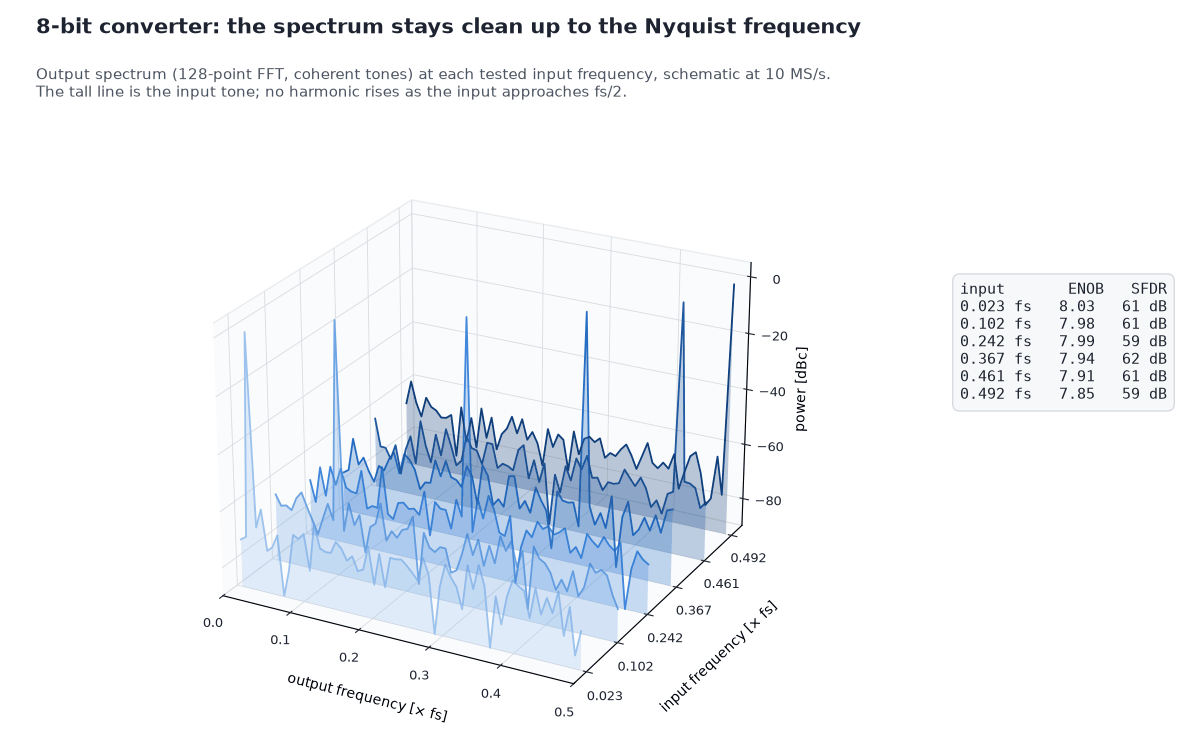

In [21]:
# @title The 8-bit design up to Nyquist: output codes of the input-frequency sweep (studies/coverage8.py,
# results/8bit/sweeps/fin_codes.json) -> spectrum and ENOB / SFDR with the flow's own FFT metrics.
from sargen import metrics
sweep = json.loads(Path("results/8bit/sweeps/fin_codes.json").read_text())
n = sweep["fft_n"]
fig = plt.figure(figsize=(12, 7.4))
ax = fig.add_axes([0.0, 0.0, 0.80, 0.82], projection="3d")
table = ["input       ENOB   SFDR"]
cycles = sorted(int(c) for c in sweep["codes"])
for i, cyc in enumerate(cycles):
    codes = np.array(sweep["codes"][str(cyc)], float)
    p = np.abs(np.fft.rfft(codes - codes.mean())) ** 2
    keep = np.arange(len(p)) > 0
    keep &= p > 1e-12 * p[cyc]          # the fs/2 bin of a half-wave-symmetric record holds no power: not drawn
    f, db, y = np.arange(len(p))[keep] / n, np.maximum(10 * np.log10(p[keep] / p[cyc]), -90), i   # dBc, one row per input
    col = RAMP(i / (len(cycles) - 1))
    ax.add_collection3d(Poly3DCollection([list(zip(f, np.full(len(f), y), db)) + [(f[-1], y, -90), (f[0], y, -90)]],
                                         facecolor=col, edgecolor="none", alpha=0.28))   # fill only: no closing edges
    ax.plot(f, np.full(len(f), y), db, color=col, lw=1.3)
    m = metrics.fft_metrics(codes.astype(int), 8, cyc)
    table.append(f"{cyc / n:.3f} fs   {m['enob']:.2f}   {m['sfdr_db']:.0f} dB")
# rows are evenly spaced (the tested frequencies are not), and each row's tick carries its input frequency
ax.set_xlim(0, 0.5); ax.set_ylim(-0.4, len(cycles) - 0.6); ax.set_zlim(-90, 5)
ax.set_yticks(range(len(cycles)), [f"{c / n:.3f}" for c in cycles])
ax.set_xlabel("output frequency [× fs]", labelpad=10); ax.set_ylabel("input frequency [× fs]", labelpad=16)
ax.set_zlabel("power [dBc]", labelpad=4); ax.view_init(elev=24, azim=-62); style3d(ax)
fig.text(0.80, 0.62, "\n".join(table), fontsize=10.5, family="monospace", color=INK, va="top",
         bbox=dict(boxstyle="round,pad=0.5", fc="#f7f8fa", ec=GRID))
heading(fig, "8-bit converter: the spectrum stays clean up to the Nyquist frequency",
        f"Output spectrum ({n}-point FFT, coherent tones) at each tested input frequency, schematic at "
        f"{sweep['fs'] / 1e6:g} MS/s.\nThe tall line is the input tone; no harmonic rises as the input approaches fs/2.")
render(fig)

## 10. Yield: PDK-calibrated behavioral Monte Carlo
The behavioral model uses the *measured* unit-capacitor sigma (from the PDK MIM model) and comparator offset
sigma (section 7), so thousands of mismatch samples run in seconds.

1000 runs: 99th percentile DNL 0.130 LSB, INL 0.083 LSB, yield(DNL<0.5 LSB) = 100.0 %


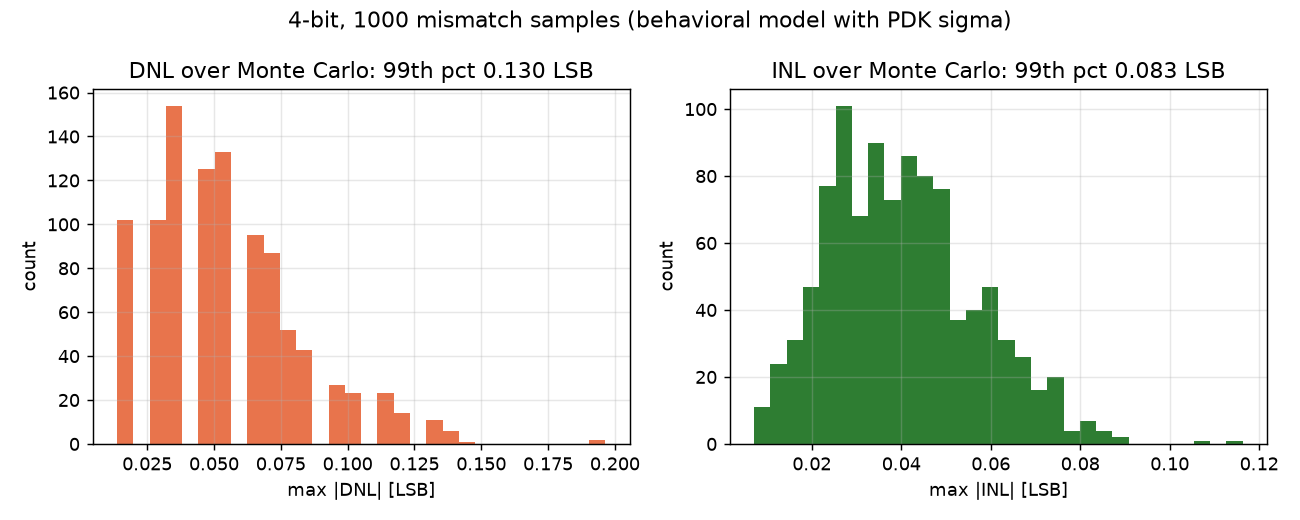

**Key insight:** 100.0 % of 1000 simulated chips meet DNL < 0.5 LSB; 99 % of them stay below 0.13 LSB.

In [22]:
m = res["mc"]
print(f"{m['runs']} runs: 99th percentile DNL {m['dnl_p99']:.3f} LSB, INL {m['inl_p99']:.3f} LSB, "
      f"yield(DNL<0.5 LSB) = {m['yield_dnl_lt_0p5']*100:.1f} %")
display(Image(filename=str(OUT / "mc_linearity.png")))
display(Markdown(f"**Key insight:** {m['yield_dnl_lt_0p5'] * 100:.1f} % of {m['runs']} simulated chips meet DNL < 0.5 LSB; "
                 f"99 % of them stay below {m['dnl_p99']:.2f} LSB."))

The same behavioral model, swept over the unit-capacitor size at each resolution: this is why the 8-bit design is the only one that needs a capacitor above the PDK minimum.

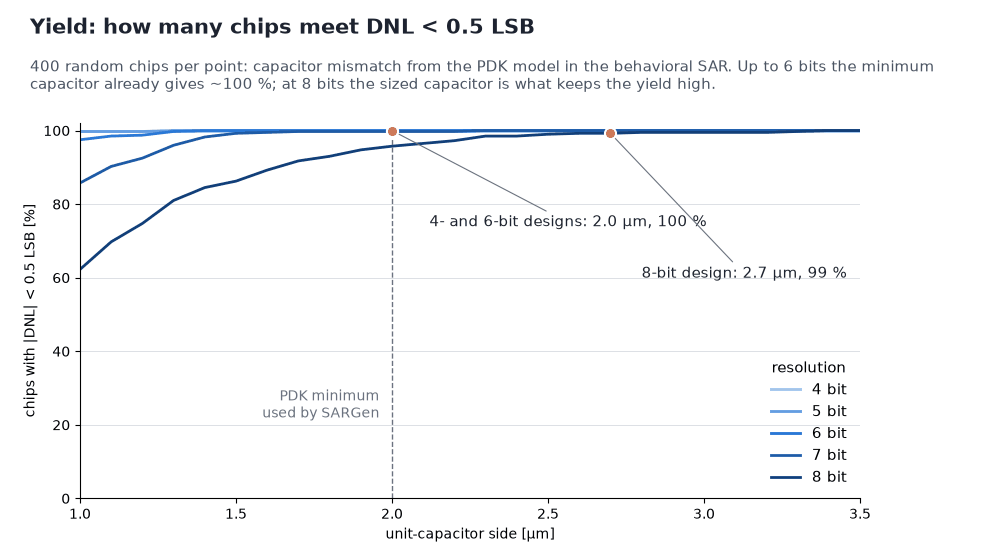

In [23]:
# @title Yield vs. unit-capacitor size, per resolution: SARGen's behavioral SAR with PDK capacitor mismatch.
def max_dnl(m):
    # exact transition levels of a truncating SAR from its drawn capacitor weights -> max |DNL| in LSB
    k = np.arange(1, 2**m.bits)
    t = ((k[:, None] >> np.arange(m.bits)) & 1) @ m.caps / m.c_sum
    return np.abs(np.diff(t) * 2**m.bits - 1).max()

def yield_pct(bits, side, runs=400):
    return 100 * np.mean([max_dnl(SarModel(bits, cu_sigma=a_c / side, seed=r)) < 0.5 for r in range(runs)])

sides = np.linspace(1.0, 3.5, 26)
fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(left=0.08, right=0.86, top=0.78, bottom=0.11)
for k, b in enumerate(range(4, 9)):
    ax.plot(sides, [yield_pct(b, s) for s in sides], color=RAMP(k / 4), lw=2, label=f"{b} bit")
design = {b: json.loads(Path(f"results/{b}bit/summary.json").read_text())["design"]["cu"]["side"] for b in (4, 6, 8)}
y = {b: yield_pct(b, s) for b, s in design.items()}
for b, s in design.items():
    ax.plot([s], [y[b]], "o", ms=8, color=ORANGE, mec="white", mew=1.5, zorder=5)
ax.annotate(f"4- and 6-bit designs: {design[4]:.1f} µm, {min(y[4], y[6]):.0f} %", (design[4], min(y[4], y[6])),
            xytext=(design[4] + 0.12, 74), fontsize=10.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.annotate(f"8-bit design: {design[8]:.1f} µm, {y[8]:.0f} %", (design[8], y[8]), xytext=(design[8] + 0.1, 60),
            fontsize=10.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.axvline(MIM_MIN_SIDE, color=MUTED, lw=1, ls="--")
ax.text(MIM_MIN_SIDE - 0.04, 22, "PDK minimum\nused by SARGen", ha="right", fontsize=10, color=MUTED)
ax.set_xlabel("unit-capacitor side [µm]"); ax.set_ylabel("chips with |DNL| < 0.5 LSB [%]")
ax.set_xlim(1.0, 3.5); ax.set_ylim(0, 102); ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="resolution", loc="lower right", frameon=False, fontsize=10.5, title_fontsize=10.5)
heading(fig, "Yield: how many chips meet DNL < 0.5 LSB",
        "400 random chips per point: capacitor mismatch from the PDK model in the behavioral SAR. Up to 6 bits the "
        "minimum\ncapacitor already gives ~100 %; at 8 bits the sized capacitor is what keeps the yield high.", y=0.94)
render(fig)

## 11. One generator, 4 to 8 bits
The same code sized and simulated 4-, 6- and 8-bit converters at transistor level (8-bit: 2048-point ramp,
256-point FFT, about an hour on 11 cores). These long runs are not repeated inside the notebook; their small
result files live in `results/` and are regenerated with `python3 run_flow.py --bits N` and
`python3 collect_results.py`.

What changes with N is driven by the sizing rules: the unit capacitor grows once **MIM matching** (not kT/C) limits
mid-code DNL, the comparator input pair grows with the tighter offset target, and the top-plate switch grows with the
total array capacitance.

| bits | f_s [MS/s] | ENOB [bit] | ENOB, ideal quantizer | SNDR [dB] | max DNL [LSB] | max INL [LSB] | missing codes | offset [LSB] | power [µW] | energy / conv. [pJ] | Walden FoM [fJ/step] | C_total [fF] | C_unit [fF] | W input pair [µm] | MC DNL, 99th pct. [LSB] | run time [min] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4 | 10 | 3.96 | 3.97 | 25.6 | 0.0625 | 0.0806 | 0 | -0.122 | 13.9 | 1.39 | 89.7 | 149 | 9.32 | 2 | 0.13 | 6.16 |
| 6 | 10 | 6.01 | 6.14 | 37.9 | 0.206 | 0.202 | 0 | -0.262 | 33.8 | 3.38 | 52.5 | 596 | 9.32 | 2.1 | 0.302 | 17.7 |
| 8 | 10 | 7.94 | 8.05 | 49.6 | 0.129 | 0.224 | 0 | -0.81 | 187 | 18.7 | 76 | 4.19e+03 | 16.4 | 33.1 | 0.443 | 61.3 |

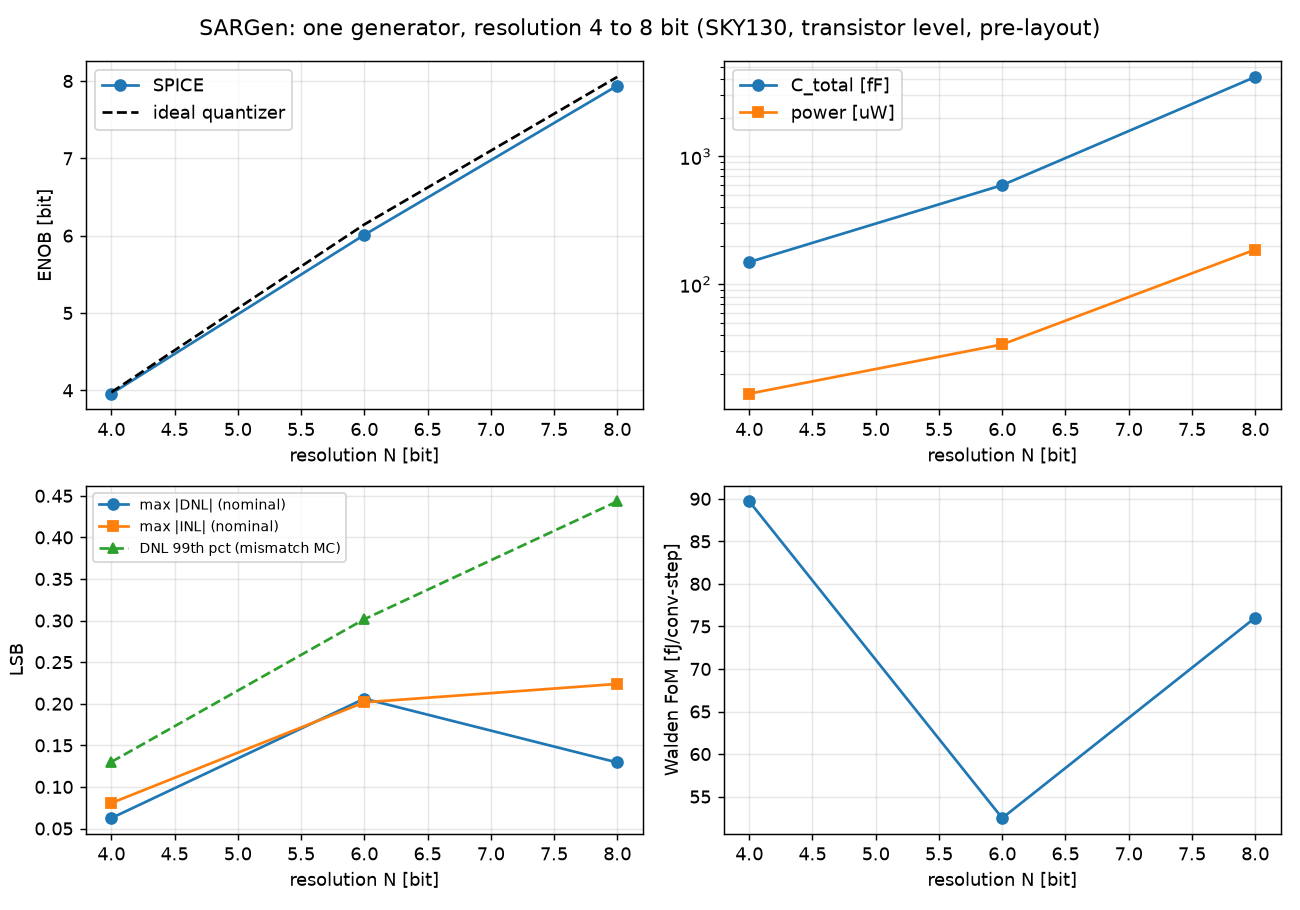

In [24]:
R = Path("results")
# Readable headers for the result tables (the files keep the program's short keys); repeated columns are dropped
HEAD = {"enob": "ENOB [bit]", "ideal_enob": "ENOB, ideal quantizer", "sndr": "SNDR [dB]", "sndr_db": "SNDR [dB]",
        "sfdr_db": "SFDR [dB]", "dnl": "max DNL [LSB]", "inl": "max INL [LSB]", "dnl_t": "max DNL [LSB]",
        "inl_t": "max INL [LSB]", "missing": "missing codes", "offset": "offset [LSB]", "offset_lsb": "offset [LSB]",
        "gain_lsb": "gain error [LSB]", "p_uw": "power [µW]", "e_pj": "energy / conv. [pJ]",
        "fom_fj": "Walden FoM [fJ/step]", "ctot_ff": "C_total [fF]", "cu_ff": "C_unit [fF]", "w_in": "W input pair [µm]",
        "mc_dnl_p99": "MC DNL, 99th pct. [LSB]", "runtime_min": "run time [min]", "fs": "f_s [MS/s]", "bits": "bits",
        "point": "condition"}
DROP = {"corner", "temp", "vdd", "f_in", "dnl_max", "inl_max"}     # repeated in the row label / the other DNL column

def tidy(text):
    out, keep, fs_col = [], None, None
    for ln in text.splitlines():
        cells = [c.strip() for c in ln.strip().strip("|").split("|")] if ln.startswith("|") else None
        if cells and keep is None:                   # header row
            keep = [i for i, c in enumerate(cells) if c not in DROP]
            fs_col = cells.index("fs") if "fs" in cells else None
            cells = [HEAD.get(c, c) for c in cells]
        elif not cells:
            keep = None
        if cells:
            if fs_col is not None and fs_col < len(cells):           # sample rate in MS/s
                try:
                    cells[fs_col] = f"{float(cells[fs_col]) / 1e6:g}"
                except ValueError:
                    pass
            cells = [cells[i] for i in keep if i < len(cells)]
            if cells and cells[0] and set(cells[0]) <= {"-"}:
                cells = ["---"] * len(cells)
            ln = "| " + " | ".join(cells) + " |"
        out.append(ln)
    return "\n".join(out)

def show(p):
    p = Path(p)
    if p.suffix == ".png" and p.exists():
        display(Image(filename=str(p)))
    elif p.exists():
        display(Markdown(tidy(p.read_text())))
    else:
        print(f"({p} not generated yet)")
show(R / "scaling.md")
show(R / "scaling.png")

## 12. Robustness: the 4-bit design across conditions, and the 8-bit design
One **fixed** design (sized at `tt`, 27 C, 1.8 V) is re-simulated - not re-sized - across conditions.

**12a. Process corners x temperature x supply**

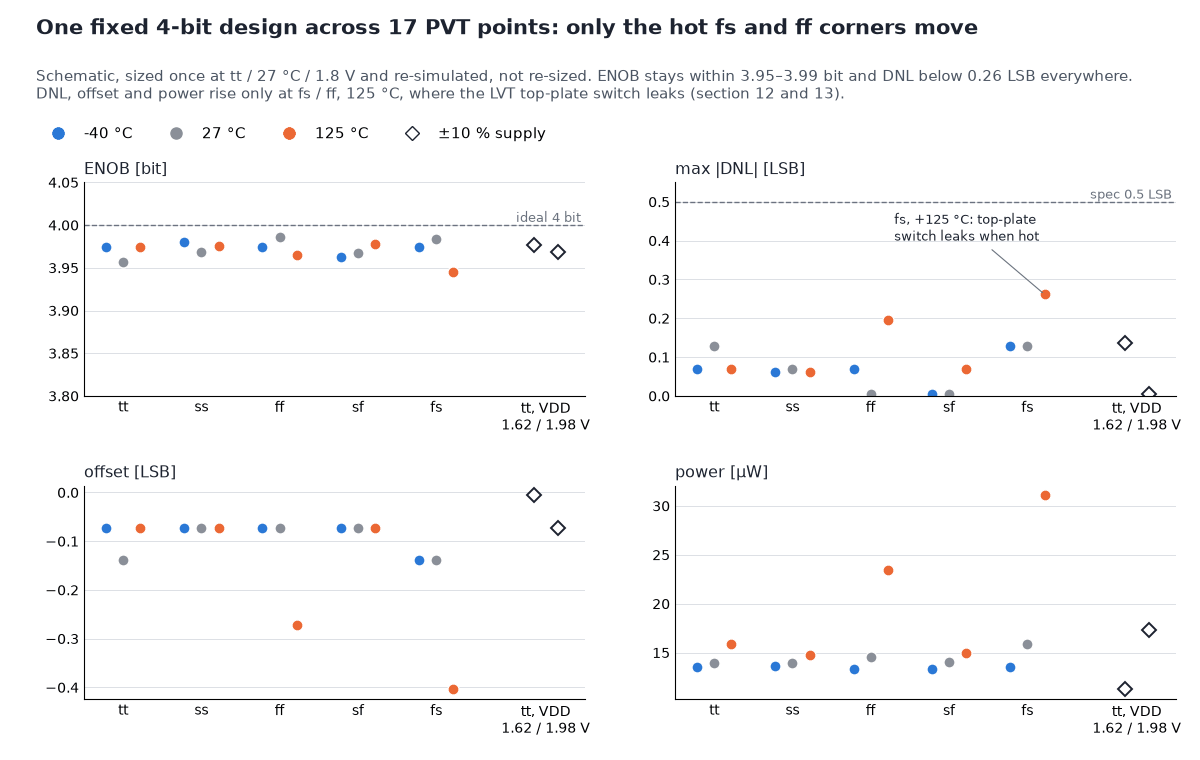

In [25]:
# @title One fixed 4-bit design across 17 PVT points (studies: sargen/sweep.py pvt): every metric, grouped by corner,
# one dot per temperature; the two supply points (tt, 27 °C, ±10 % VDD) on the right.
rows = json.loads(Path("results/4bit/sweeps/pvt_4b.json").read_text())
corners, temps = ["tt", "ss", "ff", "sf", "fs"], [-40, 27, 125]
tcol = {-40: BLUE, 27: "#8a8f98", 125: ORANGE}
panels = [("enob", "ENOB [bit]", 4.0, "ideal 4 bit"), ("dnl_t", "max |DNL| [LSB]", 0.5, "spec 0.5 LSB"),
          ("offset_lsb", "offset [LSB]", None, None), ("p_uw", "power [µW]", None, None)]
fig, axs = plt.subplots(2, 2, figsize=(12, 7.6))
fig.subplots_adjust(left=0.07, right=0.98, top=0.76, bottom=0.08, hspace=0.42, wspace=0.18)
for ax, (key, lab, ref, ref_lab) in zip(axs.ravel(), panels):
    for i, c in enumerate(corners):
        for k, t in enumerate(temps):
            r = next(r for r in rows if r["corner"] == c and r["temp"] == t and abs(r["vdd"] - 1.8) < 1e-6)
            ax.plot(i + (k - 1) * 0.22, r[key], "o", ms=8, color=tcol[t], mec="white", mew=1)
    for k, r in enumerate(sorted((r for r in rows if abs(r["vdd"] - 1.8) > 1e-6), key=lambda r: r["vdd"])):
        ax.plot(5.4 + (k - 0.5) * 0.3, r[key], "D", ms=7, mfc="white", mec=INK, mew=1.4)
    if ref is not None:
        ax.axhline(ref, color=MUTED, lw=1, ls="--"); ax.text(5.85, ref, ref_lab, ha="right", va="bottom", fontsize=9.5, color=MUTED)
    ax.set_xticks(list(range(5)) + [5.4], corners + ["tt, VDD\n1.62 / 1.98 V"])
    ax.set_xlim(-0.5, 5.9); ax.set_title(lab, loc="left", fontsize=11.5, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.6); ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=10, length=0)
axs[0, 0].set_ylim(3.8, 4.05); axs[0, 1].set_ylim(0, 0.55)
worst = max(rows, key=lambda r: r["dnl_t"])
axs[0, 1].annotate(f"{worst['corner']}, {worst['temp']:+d} °C: top-plate\nswitch leaks when hot", (4 + 0.22, worst["dnl_t"]),
                   xytext=(2.3, 0.40), fontsize=9.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
fig.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=8, color=tcol[t], label=f"{t} °C") for t in temps] +
           [plt.Line2D([], [], ls="", marker="D", ms=7, mfc="white", mec=INK, label="±10 % supply")],
           loc="upper left", bbox_to_anchor=(0.025, 0.85), ncol=4, frameon=False, fontsize=10.5)
heading(fig, "One fixed 4-bit design across 17 PVT points: only the hot fs and ff corners move",
        f"Schematic, sized once at tt / 27 °C / 1.8 V and re-simulated, not re-sized. ENOB stays within "
        f"{min(r['enob'] for r in rows):.2f}–{max(r['enob'] for r in rows):.2f} bit and DNL below "
        f"{max(r['dnl_t'] for r in rows):.2f} LSB everywhere.\nDNL, offset and power rise only at fs / ff, 125 °C, "
        "where the LVT top-plate switch leaks (section 12 and 13).", y=0.955)
render(fig)

In [26]:
show(R / "4bit/sweeps/pvt_4b.md")

| condition | ENOB [bit] | SNDR [dB] | SFDR [dB] | missing codes | max DNL [LSB] | max INL [LSB] | offset [LSB] | gain error [LSB] | power [µW] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| tt -40C 1.80V | 3.97 | 25.7 | 35.9 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 13.5 |
| tt +27C 1.80V | 3.96 | 25.6 | 34.7 | 0 | 0.129 | 0.0996 | -0.139 | 0.0117 | 13.9 |
| tt +125C 1.80V | 3.97 | 25.7 | 35.9 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 15.9 |
| ss -40C 1.80V | 3.98 | 25.7 | 37 | 0 | 0.0625 | 0.0569 | -0.0723 | 0.0117 | 13.6 |
| ss +27C 1.80V | 3.97 | 25.7 | 36.9 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 14 |
| ss +125C 1.80V | 3.98 | 25.7 | 36.4 | 0 | 0.0625 | 0.0617 | -0.0723 | 0.0117 | 14.8 |
| ff -40C 1.80V | 3.97 | 25.7 | 35.9 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 13.3 |
| ff +27C 1.80V | 3.99 | 25.8 | 36.7 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 14.5 |
| ff +125C 1.80V | 3.96 | 25.6 | 35 | 0 | 0.195 | 0.185 | -0.271 | 0.145 | 23.5 |
| sf -40C 1.80V | 3.96 | 25.6 | 33.9 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 13.4 |
| sf +27C 1.80V | 3.97 | 25.6 | 34.8 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 14.1 |
| sf +125C 1.80V | 3.98 | 25.7 | 34.7 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 15 |
| fs -40C 1.80V | 3.97 | 25.7 | 35.7 | 0 | 0.129 | 0.104 | -0.139 | 0.145 | 13.5 |
| fs +27C 1.80V | 3.98 | 25.7 | 37.7 | 0 | 0.129 | 0.128 | -0.139 | 0.0117 | 15.9 |
| fs +125C 1.80V | 3.95 | 25.5 | 35.6 | 0 | 0.262 | 0.285 | -0.404 | 0.277 | 31.1 |
| tt +27C 1.62V | 3.98 | 25.7 | 37.4 | 0 | 0.137 | 0.133 | -0.00586 | -0.0547 | 11.2 |
| tt +27C 1.98V | 3.97 | 25.7 | 35.5 | 0 | 0.00391 | 1.47e-15 | -0.0723 | -0.0547 | 17.3 |

Linearity from that table, as a map of corner x temperature (1.8 V), next to the same sweep of the extracted layout (section 13):

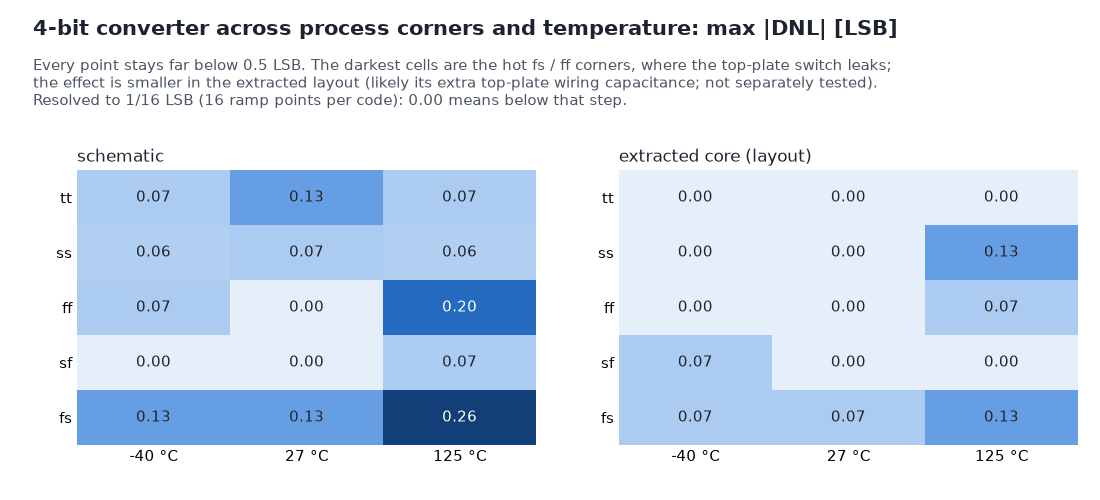

In [27]:
# @title Max |DNL| over corner x temperature (1.8 V), schematic sweep vs. the extracted core's sweep (section 13).
def pvt_grid(md):
    lines = [l for l in Path(md).read_text().splitlines() if l.startswith("|")]
    head = [h.strip() for h in lines[0].strip("|").split("|")]
    rows = [dict(zip(head, [c.strip() for c in l.strip("|").split("|")])) for l in lines[2:]]
    return {(r["corner"], int(float(r["temp"]))): float(r["dnl_t"]) for r in rows if abs(float(r["vdd"]) - 1.8) < 1e-6}

corners, temps = ["tt", "ss", "ff", "sf", "fs"], [-40, 27, 125]
maps = [("schematic", pvt_grid("results/4bit/sweeps/pvt_4b.md")),
        ("extracted core (layout)", pvt_grid("results/4bit/layout/pvt_core.md"))]
vmax = max(max(g.values()) for _, g in maps)
fig, axs = plt.subplots(1, 2, figsize=(11, 5.0))
fig.subplots_adjust(left=0.07, right=0.98, top=0.66, bottom=0.11, wspace=0.18)
for ax, (name, g) in zip(axs, maps):
    M = np.array([[g[(c, t)] for t in temps] for c in corners])
    ax.imshow(M, cmap=BLUES, vmin=0, vmax=vmax, aspect="auto")
    for i in range(len(corners)):
        for j in range(len(temps)):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=11,
                    color="white" if M[i, j] > 0.55 * vmax else INK)
    ax.set_xticks(range(3), [f"{t} °C" for t in temps]); ax.set_yticks(range(5), corners)
    ax.set_title(name, fontsize=12, loc="left", color=INK); ax.tick_params(length=0, labelsize=10.5)
    for sp in ax.spines.values():
        sp.set_visible(False)
heading(fig, "4-bit converter across process corners and temperature: max |DNL| [LSB]",
        "Every point stays far below 0.5 LSB. The darkest cells are the hot fs / ff corners, where the top-plate switch "
        "leaks;\nthe effect is smaller in the extracted layout (likely its extra top-plate wiring capacitance; not "
        "separately tested).\nResolved to 1/16 LSB (16 ramp points per code): 0.00 means below that step.", y=0.93)
render(fig)

**12b. Input frequency up to Nyquist** - sampling-switch non-linearity would show up as falling ENOB.

In [28]:
show(R / "4bit/sweeps/fin_4b.md")

| condition | ENOB [bit] | SNDR [dB] | SFDR [dB] |
| --- | --- | --- | --- |
| fin=0.023 fs | 3.95 | 25.5 | 35.9 |
| fin=0.102 fs | 3.96 | 25.6 | 34.7 |
| fin=0.242 fs | 3.99 | 25.8 | 37 |
| fin=0.367 fs | 3.95 | 25.5 | 35.4 |
| fin=0.461 fs | 3.94 | 25.5 | 36.4 |
| fin=0.492 fs | 3.97 | 25.6 | 36.6 |

**Key insight:** ENOB stays within 3.94 - 3.99 bit from 0.02 f<sub>s</sub> to Nyquist: the sampling switches add no
input-dependent distortion.

**12c. Sample rate** - the same design clocked faster until settling or comparator time runs out.

In [29]:
show(R / "4bit/sweeps/fs_4b.md")

| condition | f_s [MS/s] | ENOB [bit] | SNDR [dB] | SFDR [dB] | missing codes | max DNL [LSB] | max INL [LSB] | offset [LSB] | gain error [LSB] | power [µW] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 10 MS/s | 10 | 3.96 | 25.6 | 34.7 | 0 | 0.129 | 0.0996 | -0.139 | 0.0117 | 13.9 |
| 20 MS/s | 20 | 3.97 | 25.6 | 36.5 | 0 | 0.0703 | 0.0996 | -0.139 | 0.0117 | 27.9 |
| 40 MS/s | 40 | 3.99 | 25.8 | 37.3 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 56.2 |
| 80 MS/s | 80 | 3.86 | 25 | 31.6 | 0 | 0.0703 | 0.0427 | -0.0723 | 0.0117 | 114 |
| 160 MS/s | 160 | nan | nan | nan | 14 | nan | nan | nan | nan | 206 |

**Key insight:** the design sized for 10 MS/s keeps its ENOB up to 40 MS/s, loses 0.1 bit at 80 MS/s and fails at
160 MS/s, where one bit cycle no longer lets the DAC settle: an 8x margin on the sample rate.

**12d. Comparator regeneration** - clock-to-output delay grows as tau * ln(1/dV) for small inputs; this sets the
metastability margin of the bit cycle.

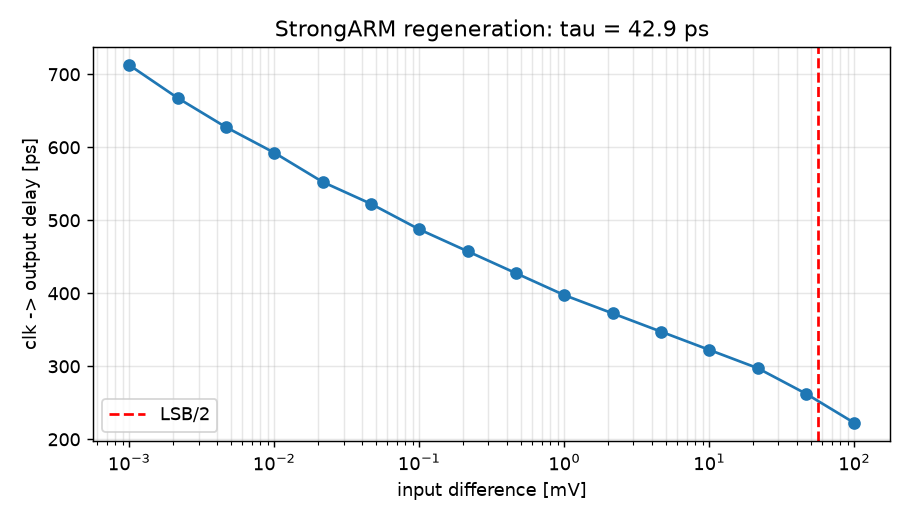

In [30]:
show(R / "4bit/sweeps/cmp_delay_4b.png")

**12e. Transistor-level mismatch vs. the behavioral model** - full SPICE ramps with SKY130 mismatch (`tt_mm`)
compared with the PDK-calibrated behavioral Monte Carlo of section 10, re-run below with the same settings.

*Pitfall worth knowing:* each ramp is split into parallel ngspice runs. `set rndseed` in `.spiceinit` does **not**
give the same mismatch draws in every process, so the chunks silently became different dies and the stitched
transfer curve showed fake DNL steps exactly at the chunk boundaries. `.option seed=N` in the netlist is
reproducible; `sargen.spice` injects it.

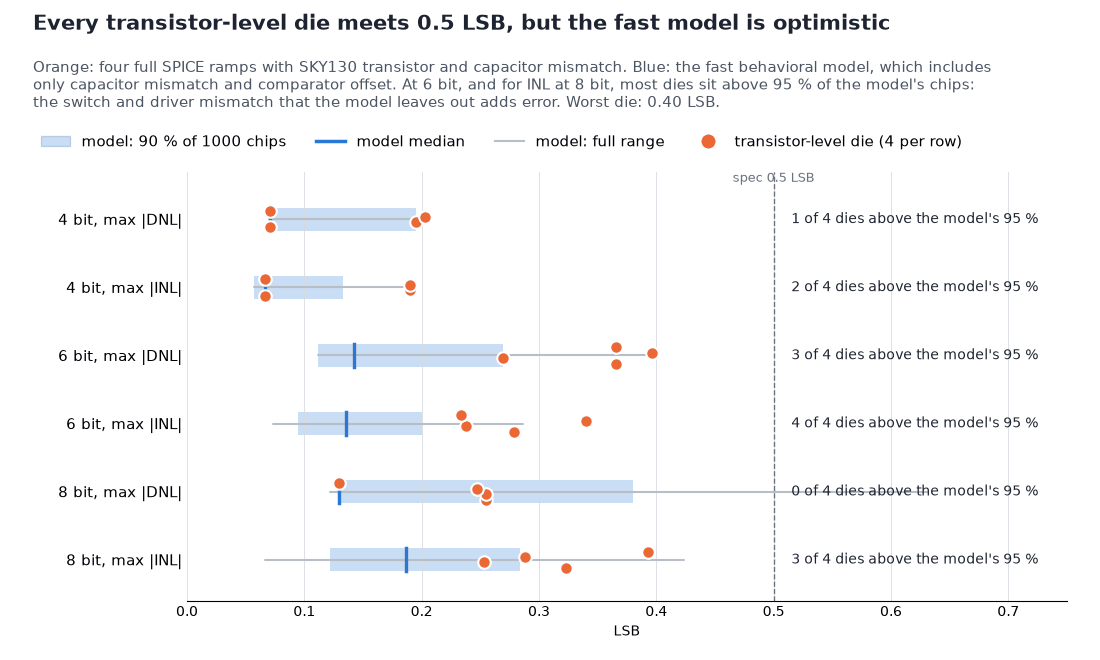

In [31]:
# @title Do full transistor-level mismatch runs land where the behavioral model says they should?
# The model (section 10) is re-run here with the settings of sargen/sweep.py spice_mc: 1000 chips, capacitor mismatch
# from the PDK, comparator offset sigma from section 7, the same ramp resolution as the 4 transistor-level dies.
from sargen import metrics
rows = []                                            # (label, model values, die values)
for b in (4, 6, 8):
    mc = json.loads(Path(f"results/{b}bit/sweeps/spice_mc_{b}b.json").read_text())
    s = json.loads(Path(f"results/{b}bit/summary.json").read_text())
    sp = SarSpec(bits=b); n = mc["hits"] * 2**b
    vin = -0.5 * sp.lsb + (sp.vref + sp.lsb) * np.arange(n) / n
    rng, beh = np.random.default_rng(7), []
    for k in range(1000):
        m = SarModel(b, sp.vref, cu_sigma=s["design"]["cu"]["sigma_u"], offset=rng.normal(0, s["comparator_offset"]["sigma"]), seed=k)
        tr = metrics.transition_inl_dnl(metrics.transition_levels(vin, m.convert(vin), b), sp.vref, b)
        beh.append((tr["dnl_max"], tr["inl_max"]))
    beh = np.array(beh)
    rows += [(f"{b} bit, max |DNL|", beh[:, 0], [d["dnl"] for d in mc["spice"]]),
             (f"{b} bit, max |INL|", beh[:, 1], [d["inl"] for d in mc["spice"]])]

fig, ax = plt.subplots(figsize=(11, 6.6))
fig.subplots_adjust(left=0.17, right=0.97, top=0.74, bottom=0.09)
for i, (lab, model, dies) in enumerate(rows):
    y = len(rows) - 1 - i
    lo, med, hi = np.percentile(model, [5, 50, 95])
    ax.plot([model.min(), model.max()], [y, y], color=GREY, lw=1.5, solid_capstyle="round")       # full model range
    ax.add_patch(plt.Rectangle((lo, y - 0.17), max(hi - lo, 0.004), 0.34, color=BLUE, alpha=0.25, lw=0))   # 90 %
    ax.plot([med, med], [y - 0.17, y + 0.17], color=BLUE, lw=2.5)                                  # median
    jitter = np.linspace(-0.12, 0.12, len(dies))
    ax.plot(dies, y + jitter, "o", ms=9, color=ORANGE, mec="white", mew=1.5, zorder=5)
    above = sum(d > hi for d in dies)
    ax.text(0.515, y, f"{above} of {len(dies)} dies above the model's 95 %", va="center", fontsize=10, color=INK)
ax.axvline(0.5, color=MUTED, lw=1, ls="--"); ax.text(0.5, len(rows) - 0.45, "spec 0.5 LSB", ha="center", fontsize=9.5, color=MUTED)
ax.set_yticks(range(len(rows)), [r[0] for r in rows][::-1], fontsize=10.5)
ax.set_xlim(0, 0.75); ax.set_ylim(-0.6, len(rows) - 0.3); ax.set_xlabel("LSB")
ax.grid(axis="x", color=GRID, lw=0.6); ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(length=0)
fig.legend(handles=[Patch(color=BLUE, alpha=0.25, label="model: 90 % of 1000 chips"),
                    plt.Line2D([], [], color=BLUE, lw=2.5, label="model median"),
                    plt.Line2D([], [], color=GREY, lw=1.5, label="model: full range"),
                    plt.Line2D([], [], ls="", marker="o", ms=9, color=ORANGE, label="transistor-level die (4 per row)")],
           loc="upper left", bbox_to_anchor=(0.025, 0.815), ncol=4, frameon=False, fontsize=10.5)
heading(fig, "Every transistor-level die meets 0.5 LSB, but the fast model is optimistic",
        "Orange: four full SPICE ramps with SKY130 transistor and capacitor mismatch. Blue: the fast behavioral model, which "
        "includes\nonly capacitor mismatch and comparator offset. At 6 bit, and for INL at 8 bit, most dies sit above 95 % "
        "of the model's chips:\nthe switch and driver mismatch that the model leaves out adds error. Worst die: "
        f"{max(max(r[2]) for r in rows):.2f} LSB.", y=0.955)
render(fig)

**12f. The 8-bit design beyond nominal** - the headline resolution, re-simulated (schematic, fixed design): input
frequency up to Nyquist, the worst PVT corners of the 4-bit sweep, real sources through TinyTapeout pins and
transistor-level mismatch. The PVT rows below are with the original LVT top-plate switch; the fix follows.

In [32]:
show(R / "8bit/sweeps/coverage8.md")

| input frequency | ENOB | SNDR [dB] | SFDR [dB] |
| --- | --- | --- | --- |
| 0.023 fs (0.23 MHz) | 8.03 | 50.1 | 60.6 |
| 0.102 fs (1.02 MHz) | 7.98 | 49.8 | 60.6 |
| 0.242 fs (2.42 MHz) | 7.99 | 49.8 | 59.1 |
| 0.367 fs (3.67 MHz) | 7.94 | 49.5 | 61.8 |
| 0.461 fs (4.61 MHz) | 7.91 | 49.4 | 61.2 |
| 0.492 fs (4.92 MHz) | 7.85 | 49.0 | 58.5 |

| PVT point | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| ss -40C 1.80V | 7.86 | 0.247 | 0.209 | -1.12 | -0.51 | 186 |
| ff +125C 1.80V | 6.52 | 1.000 | 2.885 | -1.50 | +0.87 | 312 |
| fs +125C 1.80V | 5.78 | 1.008 | 6.020 | -1.50 | +0.87 | 431 |
| sf -40C 1.80V | 7.68 | 0.247 | 0.401 | -1.37 | -1.02 | 177 |
| tt +27C 1.62V | 8.00 | 0.255 | 0.213 | -0.87 | -0.26 | 150 |

Schematic, fixed 8-bit design at 10 MS/s; PVT points use 4 hits per code (DNL/INL/offset/gain resolved to 1/4 LSB), FFT 128 points.

**What the 8-bit corners exposed, and the generator fix.** With the original LVT top-plate switch the hot fast
corners lost codes (ff / fs, 125 C). The cause is the switch's off-state leakage while the floating top plate sits
near a rail on the first trials of a near-full-scale input: short LVT and standard-Vt PMOS devices leak strongly
there when hot (drain-induced barrier lowering), and the 8-bit switch is wide while its LSB is small. A DC screen
of switch flavours (`studies/top_switch_screen.py`) ranks them by on-resistance (cold) against plate leakage (hot).
The sizing step now characterizes both, sizes the top switch for its on-resistance at V<sub>cm</sub> (the only
voltage it passes) and takes the least leaky flavour within a width cap: an LVT NMOS with a standard-V<sub>t</sub>
PMOS, both at L = 0.3 um. (The 8-bit ENOBs below are taken with the full-scale sine and are clip-limited by the
wider switch's ~2-LSB offset; section 13 shows 7.85-7.88 at -0.5 dBFS.) Transient trials at the hot and the cold corner chose between five candidates
(`studies/top_switch_trials.py`; table in `docs/layout_findings.md`, 6f); the corners of the final design:

In [33]:
for b in (4, 6, 8):
    show(R / f"{b}bit/sweeps/top_switch_verify.md")

Top-plate switch mixl (0.65/1.3 um), 4-bit schematic, 16 hits per code.

| PVT point | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| fs +125C 1.80V | 3.97 | 0.070 | 0.066 | -0.07 | -0.05 | 31 |
| ss -40C 1.80V | 4.01 | 0.004 | 0.000 | -0.07 | -0.05 | 14 |
| ff +125C 1.80V | 3.99 | 0.070 | 0.066 | -0.14 | -0.05 | 23 |
| sf -40C 1.80V | 3.98 | 0.062 | 0.052 | -0.14 | +0.01 | 13 |
| tt +27C 1.80V | 3.97 | 0.070 | 0.066 | -0.14 | -0.05 | 14 |

Top-plate switch mixl (4.35/8.7 um), 6-bit schematic, 8 hits per code.

| PVT point | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| fs +125C 1.80V | 5.97 | 0.143 | 0.213 | -0.29 | +0.08 | 94 |
| ss -40C 1.80V | 5.97 | 0.143 | 0.188 | -0.29 | -0.05 | 33 |
| ff +125C 1.80V | 5.89 | 0.365 | 0.307 | -0.17 | -0.05 | 67 |
| sf -40C 1.80V | 6.01 | 0.111 | 0.119 | -0.17 | -0.05 | 33 |
| tt +27C 1.80V | 5.91 | 0.365 | 0.270 | -0.17 | -0.17 | 34 |

Top-plate switch mixl (47.3/94.6 um), 8-bit schematic, 4 hits per code.

| PVT point | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| fs +125C 1.80V | 7.51 | 0.373 | 0.784 | -1.50 | -0.39 | 431 |
| ss -40C 1.80V | 7.73 | 0.255 | 0.207 | -1.50 | -0.64 | 185 |
| ff +125C 1.80V | 7.58 | 0.255 | 0.395 | -1.50 | -0.89 | 312 |
| sf -40C 1.80V | 7.58 | 0.247 | 0.337 | -1.37 | -1.27 | 177 |
| tt +27C 1.80V | 7.68 | 0.373 | 0.369 | -1.50 | -0.89 | 187 |

**Real sources through TinyTapeout pins** (500 Ohm per analog pin, 5 pF on the input; `studies/source_impedance.py`).
Harmless at 4 bit (section 13 table), but the 8-bit array (4.2 pF) cannot be charged through 500 Ohm in the tracking
time, and an on-chip decap behind 500 Ohm cannot be refilled within one conversion. An 8-bit TinyTapeout version
needs on-chip input and reference buffers (or a lower sample rate) - a roadmap item, not a flow limitation.

In [34]:
show(R / "8bit/sweeps/source_impedance.md")
show(R / "4bit/sweeps/source_impedance.md")

| sources | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| ideal sources | 7.98 | 0.255 | 0.277 | -0.87 | -0.51 | 186.6 |
| input through the pin | 6.99 | 0.506 | 0.753 | -0.87 | +0.99 | 187.4 |
| vref, vcm decap 10 x C_DAC (42 pF) | 6.44 | 3.267 | 4.014 | -0.62 | -1.02 | 186.1 |
| vref, vcm decap 100 x C_DAC (419 pF) | 6.76 | 0.506 | 1.152 | -0.87 | -2.52 | 182.9 |
| all three (decap 100 x C_DAC) | 6.60 | 1.008 | 1.690 | -0.87 | -1.02 | 183.8 |

Each source through 500 Ohm (TinyTapeout analog pin); input pin 5 pF; 4 hits per code.

| sources | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| ideal sources | 3.96 | 0.129 | 0.100 | -0.14 | +0.01 | 13.9 |
| input through the pin | 3.98 | 0.129 | 0.104 | -0.14 | +0.01 | 14.0 |
| vref, vcm decap 10 x C_DAC (1 pF) | 3.97 | 0.129 | 0.095 | -0.14 | +0.08 | 13.9 |
| vref, vcm decap 100 x C_DAC (15 pF) | 3.98 | 0.129 | 0.066 | -0.14 | +0.08 | 14.0 |
| all three (decap 100 x C_DAC) | 3.96 | 0.137 | 0.076 | -0.14 | +0.08 | 14.0 |

Each source through 500 Ohm (TinyTapeout analog pin); input pin 5 pF; 16 hits per code.

## 13. Automated layout and post-layout verification
Every block is generated by code, from the **SKY130 PDK's own PCells** (Magic's device generator: MIM capacitor and
FETs are correct by construction); SARGen only places and routes them, packing to the real layer extents and the
design rules. Each block is closed at **DRC 0 / LVS match** before the next one is built (KLayout `sky130A_mr.drc`
plus a deck for rule capm.10, Magic DRC, Netgen LVS), and the analog blocks are re-simulated from their extracted
layout. What shaped the layout (details and numbers: `docs/layout_findings.md`):

* **CDAC unit cell** - one 2 x 2 um MIM cap with its *own* switches. SKY130 rule **capm.10** keeps diffusion, poly, li
  and met1 out from under a MIM cap, so the switches sit in the 1.34 um gap that rule capm.11 forces between caps;
  only met2 control rails pass under the cap, whose bottom plate shields the top plate. The cell (4.88 x 3.58 um
  pitch) is set by the capacitor spacing rules, not by the switch. No met5 (TinyTapeout power grid).
* **CDAC array** - every bit is built from point-symmetric unit pairs (common centroid), packed with at most 3 bits per
  row so one unit cell serves every resolution; a ring of dummy unit caps gives every real unit real neighbours.
  Extracted top-plate coupling of all control rails: 0.6 % of the array, systematic bit-weight error < 0.04 %.
* **StrongARM [3] - one generator for 4 to 8 bits** - mirror symmetry with the tail and clock on the axis, a clustered
  input pair with identical inner drains (equal capacitance on the integration nodes), dummy fingers, guard rings,
  output tracks swapped on the axis and balanced on extraction, standard-Vt devices (better matching): 1671 -> ~90 um^2
  at 4 bit. The sizing sets the device widths and the generator derives the fingers (input pair, tail, latch, trim),
  so the 8-bit comparator - a 14-finger input pair - comes from the same code. A common-centroid (ABBA) pair was tried
  at 8 bit and dropped (as reported for small latches [9]): on extraction it unbalances the integration nodes (xp / xn 1.1 %), while the clustered mirrored
  pair keeps them within 0.5 % and the outputs within 0.3 % at every resolution. Every latch device sits between dummy
  fingers, and the latch halves sit next to the axis: matched devices close together (at 8 bit the latch halves'
  centres are 7.5 / 11.3 um apart instead of 19 / 23 um, and the cell is 25 % smaller).
* **Top-plate switch** in closed p+ / n-tap guard rings: its diffusion is the floating top plate's only junction.
  Three source/drain tracks (NMOS vcm, shared top, PMOS vcm) let it scale to any finger count; both rows have the same
  count (24 + 24 at 8 bit, the PMOS fingers twice as wide) between end dummies, so the ring closes tightly.
* **SAR logic** - the same standard cells as the netlist, hardened with **LibreLane** [10] (tap cells, decaps, met4-only power),
  re-checked by the same signoff.
* **Core** - analog on the west, logic on the east; the top-plate net is met4 only and runs along no dynamic line.

To regenerate (inside IIC-OSIC-TOOLS, with the pinned layout environment of `layout/setup_env.sh`):
```bash
for n in 4 6 8; do
  for b in unitcell cdacu comparator topsw sarlogic lod; do python run_layout.py $b --bits $n; done
  python run_layout.py cdacu --bits $n --pex; python run_layout.py comparator --bits $n --pex
  python run_layout.py core --bits $n --pex          # place + route the blocks above, DRC / LVS, extraction
  python collect_layout.py $n
done
python run_postlayout.py --bits 4                    # cases whose extractions exist
```
The same generators, unchanged, build the 6- and 8-bit cores: only the design (`build/<N>bit/design.json`) differs.

**The unit cell in 3D.** Rule capm.10 is easiest to see with the layers pulled apart: transistors, local interconnect and metal 1 stay beside the capacitor; only the metal-2 control rails cross under it.

layers under the MIM capacitor: {'diff': 0, 'poly': 0, 'li': 0, 'met1': 0, 'met2': 4}


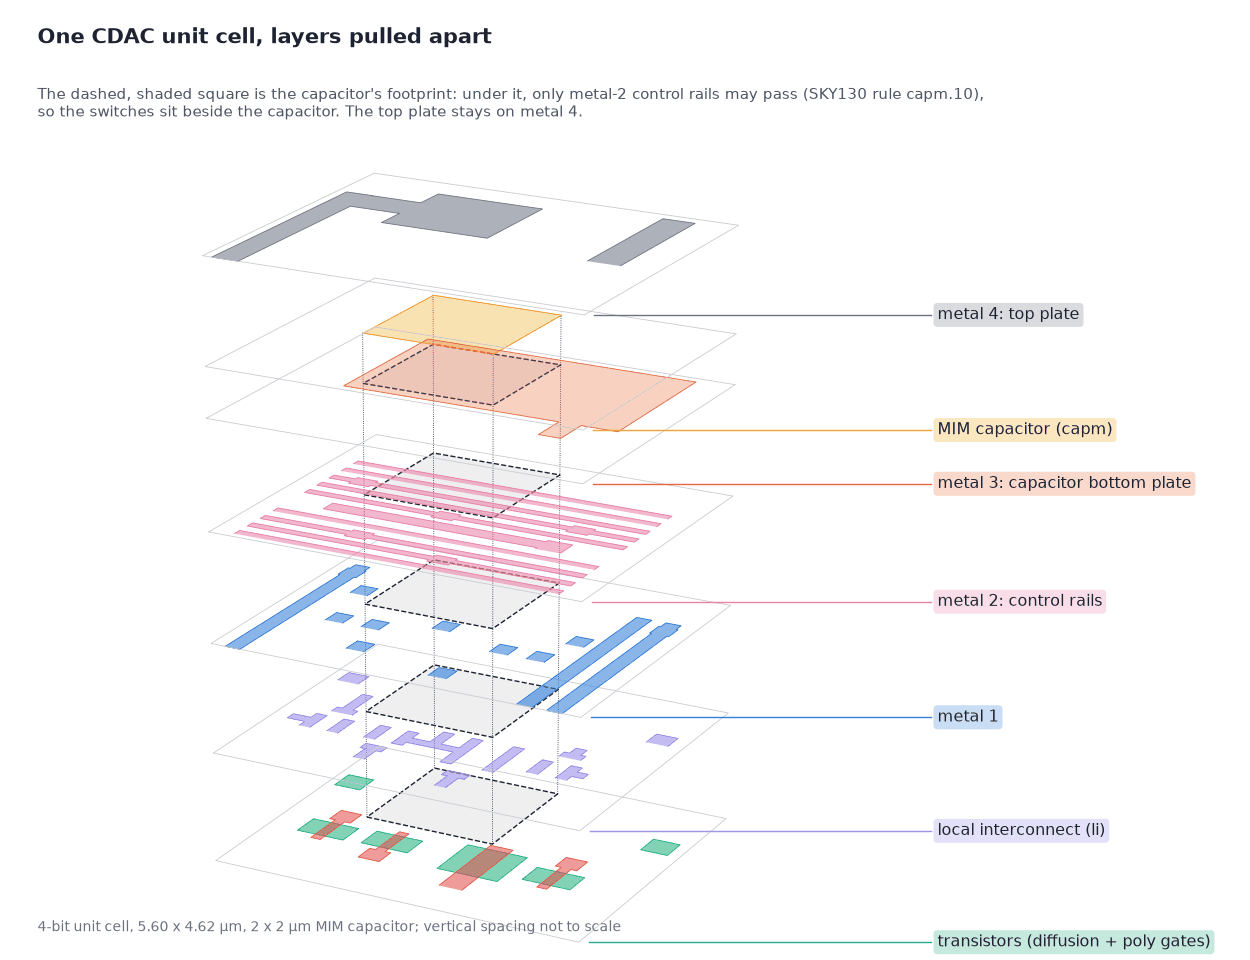

In [35]:
# @title The 4-bit CDAC unit cell with its layers pulled apart. Polygons come from the cell's GDS
# (results/4bit/layout/cdac_unit_layers.json, exported with KLayout: docs/figures/export_figure_data.py).
cell = json.loads(Path("results/4bit/layout/cdac_unit_layers.json").read_text())
x0, y0, x1, y1 = cell["bbox"]
capm = np.array(cell["capm"][0]); fx0, fy0 = capm.min(0); fx1, fy1 = capm.max(0)
# check rule capm.10 from the geometry: which layers overlap the capacitor's footprint?
inside = lambda p: min(p[:, 0].max(), fx1) > max(p[:, 0].min(), fx0) and min(p[:, 1].max(), fy1) > max(p[:, 1].min(), fy0)
print("layers under the MIM capacitor:", {k: int(sum(inside(np.array(p)) for p in cell[k]))
                                          for k in ("diff", "poly", "li", "met1", "met2")})
STACK = [("diff", 0.0, "#1baf7a", "transistors (diffusion + poly gates)"), ("poly", 0.0, "#e34948", None),
         ("li", 1.0, "#9085e9", "local interconnect (li)"), ("met1", 2.0, "#2a78d6", "metal 1"),
         ("met2", 3.0, "#e87ba4", "metal 2: control rails"), ("met3", 4.0, "#eb6834", "metal 3: capacitor bottom plate"),
         ("capm", 4.45, "#eda100", "MIM capacitor (capm)"), ("met4", 5.4, "#6b7280", "metal 4: top plate")]
fig = plt.figure(figsize=(12.5, 9.6))
ax = fig.add_axes([0.0, 0.0, 0.74, 0.86], projection="3d")
for name, z, col, _ in STACK:
    ax.add_collection3d(Poly3DCollection([[(x, y, z) for x, y in p] for p in cell[name]], facecolor=col, edgecolor=col,
                                         linewidths=0.6, alpha=0.30 if name in ("met3", "capm") else 0.55))
    if name == "poly":
        continue
    ax.add_collection3d(Line3DCollection([[(x0, y0, z), (x1, y0, z), (x1, y1, z), (x0, y1, z), (x0, y0, z)]],
                                         colors="#c7cbd1", linewidths=0.6))
    if name in ("capm", "met4"):
        continue
    ax.add_collection3d(Poly3DCollection([[(fx0, fy0, z), (fx1, fy0, z), (fx1, fy1, z), (fx0, fy1, z)]],
                                         facecolor=INK, edgecolor="none", alpha=0.07))
    ax.plot([fx0, fx1, fx1, fx0, fx0], [fy0, fy0, fy1, fy1, fy0], [z] * 5, color=INK, lw=1.0, ls="--")
for x, y in ((fx0, fy0), (fx1, fy0), (fx1, fy1), (fx0, fy1)):
    ax.plot([x, x], [y, y], [0, 4.45], color=INK, lw=0.6, ls=":")
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_zlim(0, 5.6)
ax.set_box_aspect((x1 - x0, y1 - y0, 9.0)); ax.view_init(elev=20, azim=-62); ax.set_axis_off()
for name, z, col, lab in STACK:                     # one label per layer, on a leader from its plane's right corner
    if lab:
        fx, fy = pin(fig, ax, x1, y0, z, marker=False)
        fig.add_artist(plt.Line2D([fx + 0.008, 0.745], [fy, fy], color=col, lw=1.0))
        fig.text(0.75, fy, lab, fontsize=11.5, color=INK, va="center",
                 bbox=dict(boxstyle="round,pad=0.25", fc=col, ec="none", alpha=0.25))
heading(fig, "One CDAC unit cell, layers pulled apart",
        "The dashed, shaded square is the capacitor's footprint: under it, only metal-2 control rails may pass "
        "(SKY130 rule capm.10),\nso the switches sit beside the capacitor. The top plate stays on metal 4.")
fig.text(0.03, 0.03, f"4-bit unit cell, {x1 - x0:.2f} x {y1 - y0:.2f} µm, 2 x 2 µm MIM capacitor; vertical spacing "
         "not to scale", fontsize=10, color=MUTED)
render(fig)

| block | size [um] | area [um^2] | KLayout DRC (incl. capm.10) | magic DRC | LVS |
| --- | --- | --- | --- | --- | --- |
| CDAC unit cell (MIM cap + its own switches) | 5.60 x 4.62 | 26 | 0 | 0 | match (5/5 devices) |
| unit-cell abutment test (2 x 3) | 15.92 x 11.41 | 182 | 0 | 0 | match (30/30 devices) |
| 4-bit CDAC (common-centroid, dummy-cap ring) | 36.40 x 24.26 | 883 | 0 | 0 | match (81/81 devices) |
| StrongARM comparator | 11.63 x 8.79 | 102 | 0 | 0 | match (22/22 devices) |
| top-plate sampling switch (guard rings) | 6.19 x 6.37 | 39 | 0 | 0 | match (4/4 devices) |
| SAR logic (LibreLane, sky130_fd_sc_hd) | 23.40 x 23.40 | 548 | 0 | 0 | match (22/22 devices) |
| 4-bit SAR ADC core (all blocks routed) | 65.80 x 41.98 | 2762 | 0 | 0 | match (4/4 block instances) |

cdac_unit


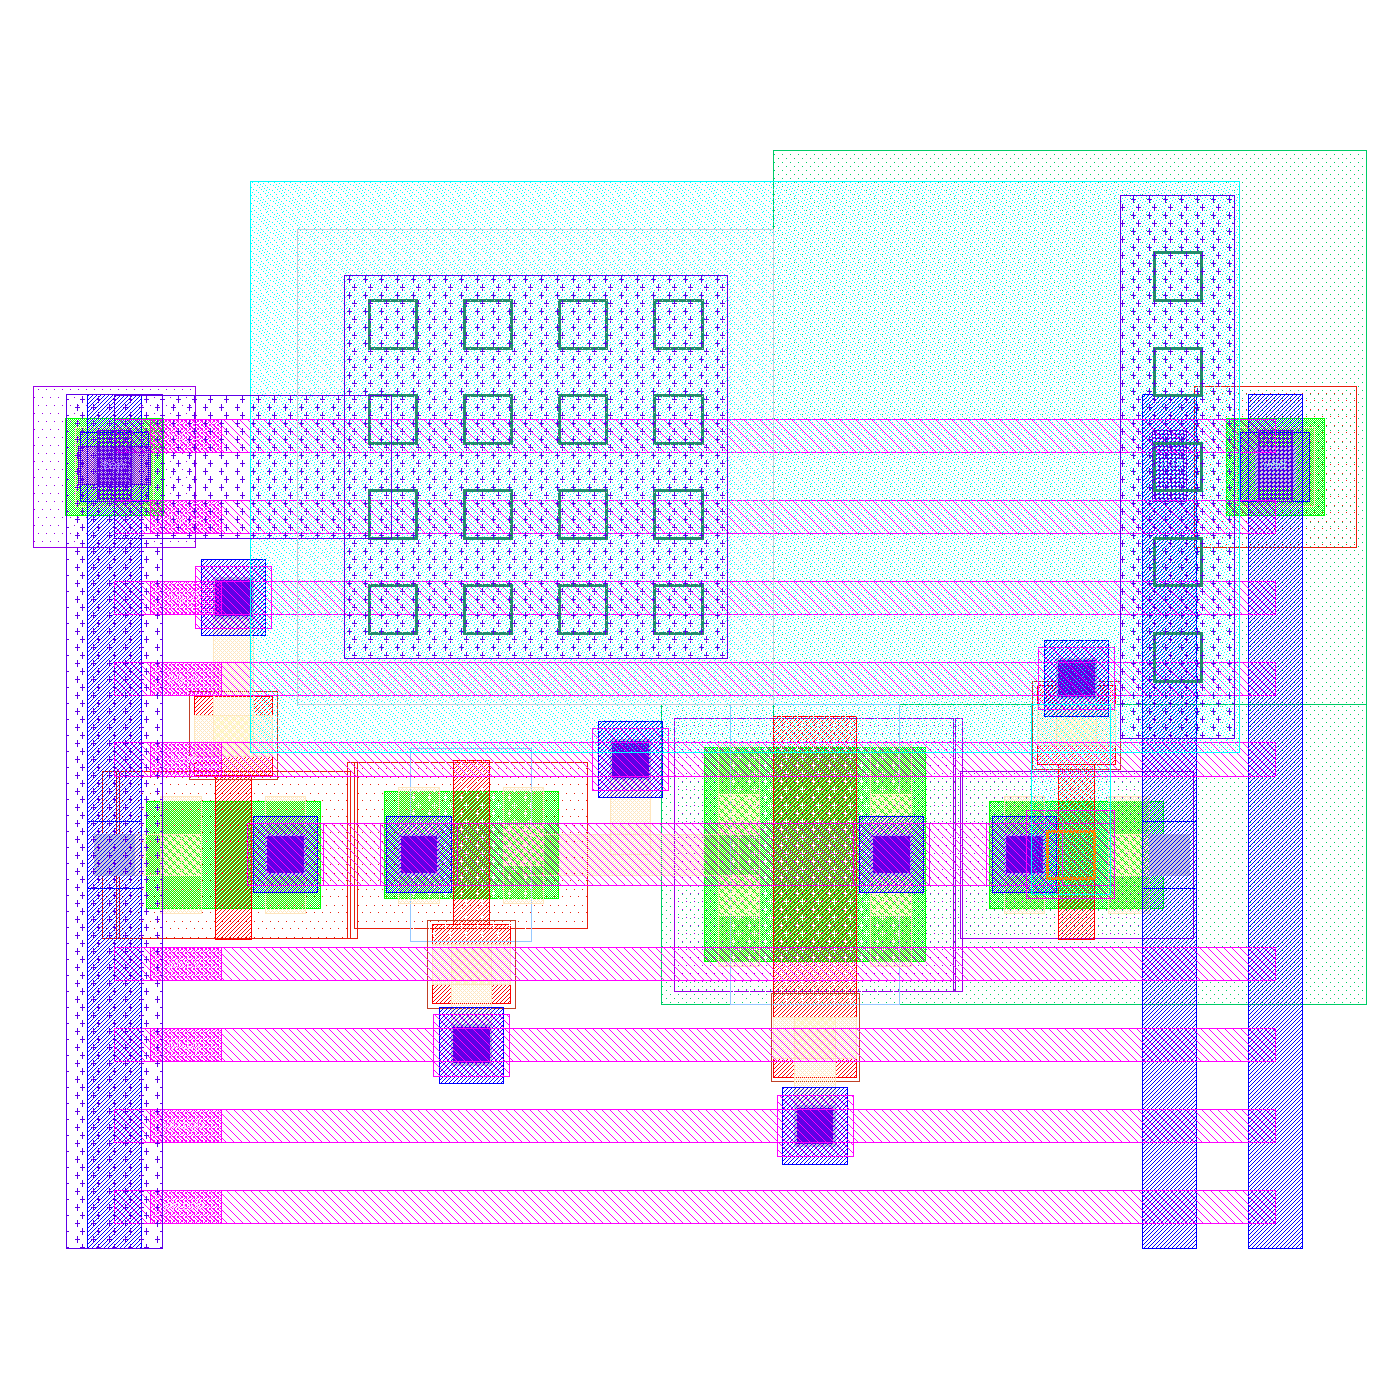

cdacu4b


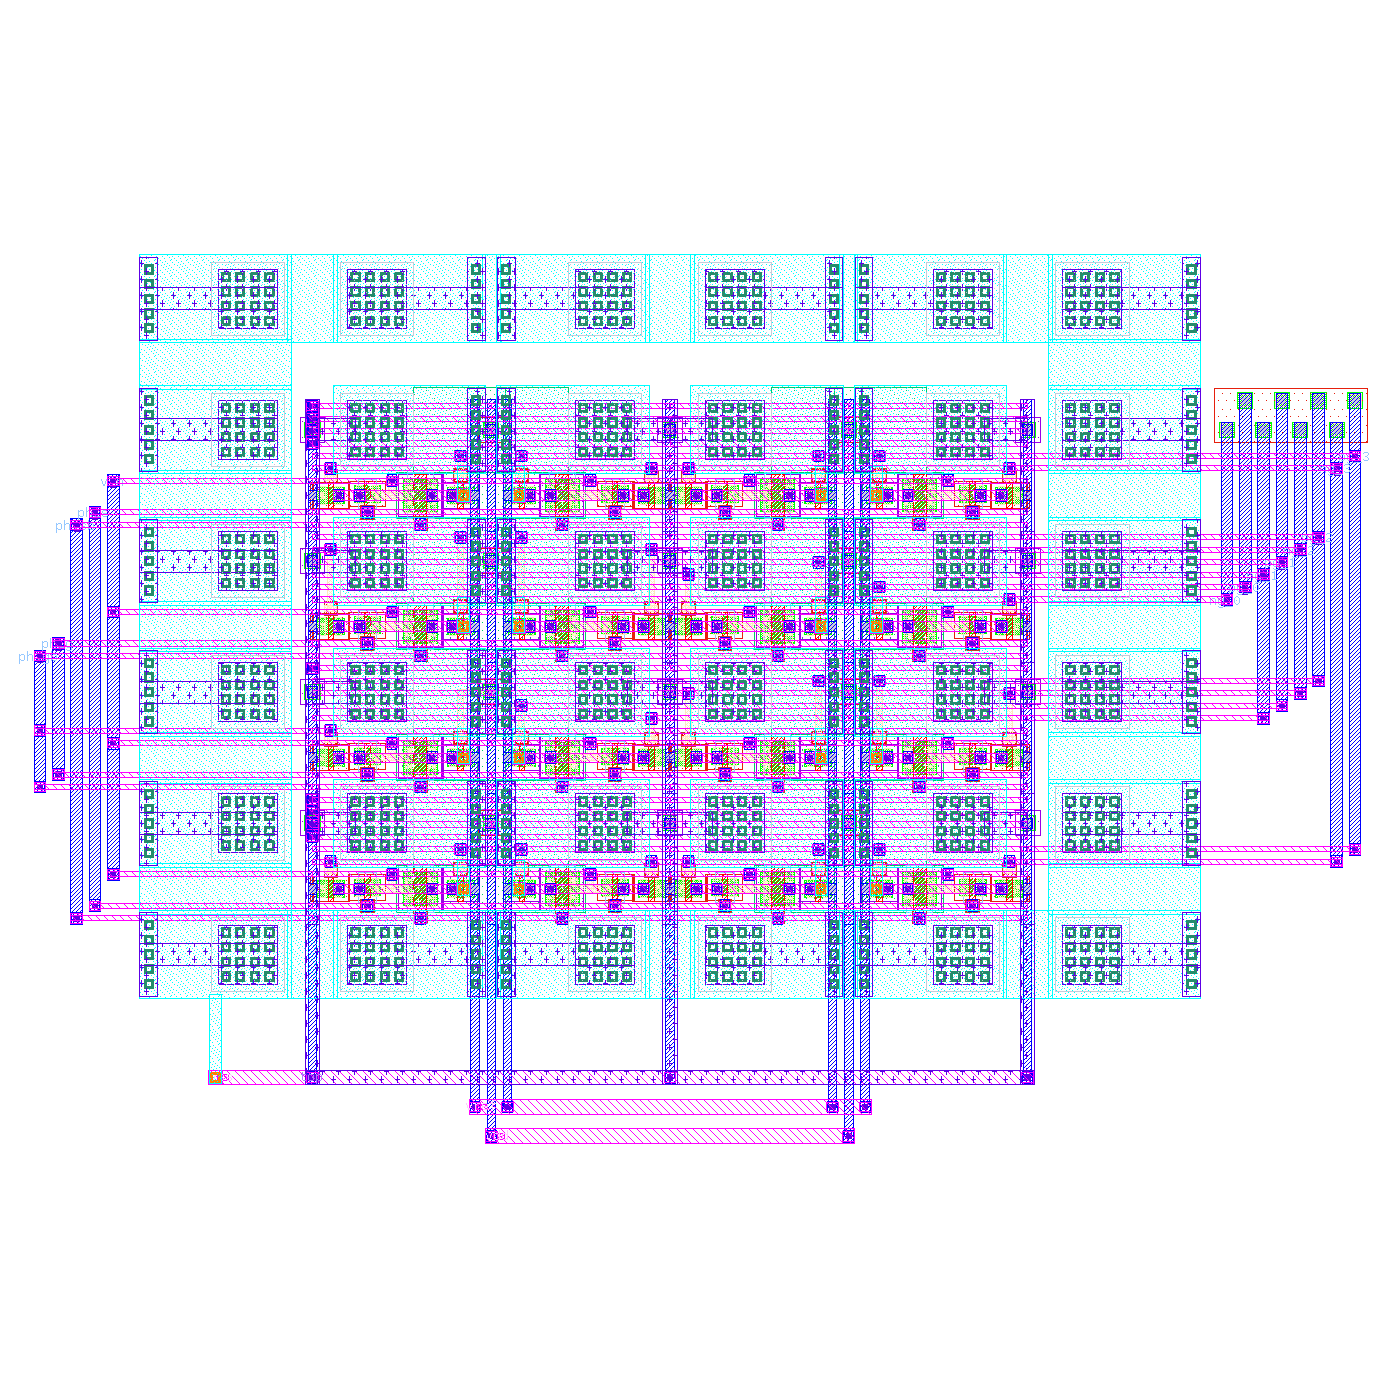

strongarm


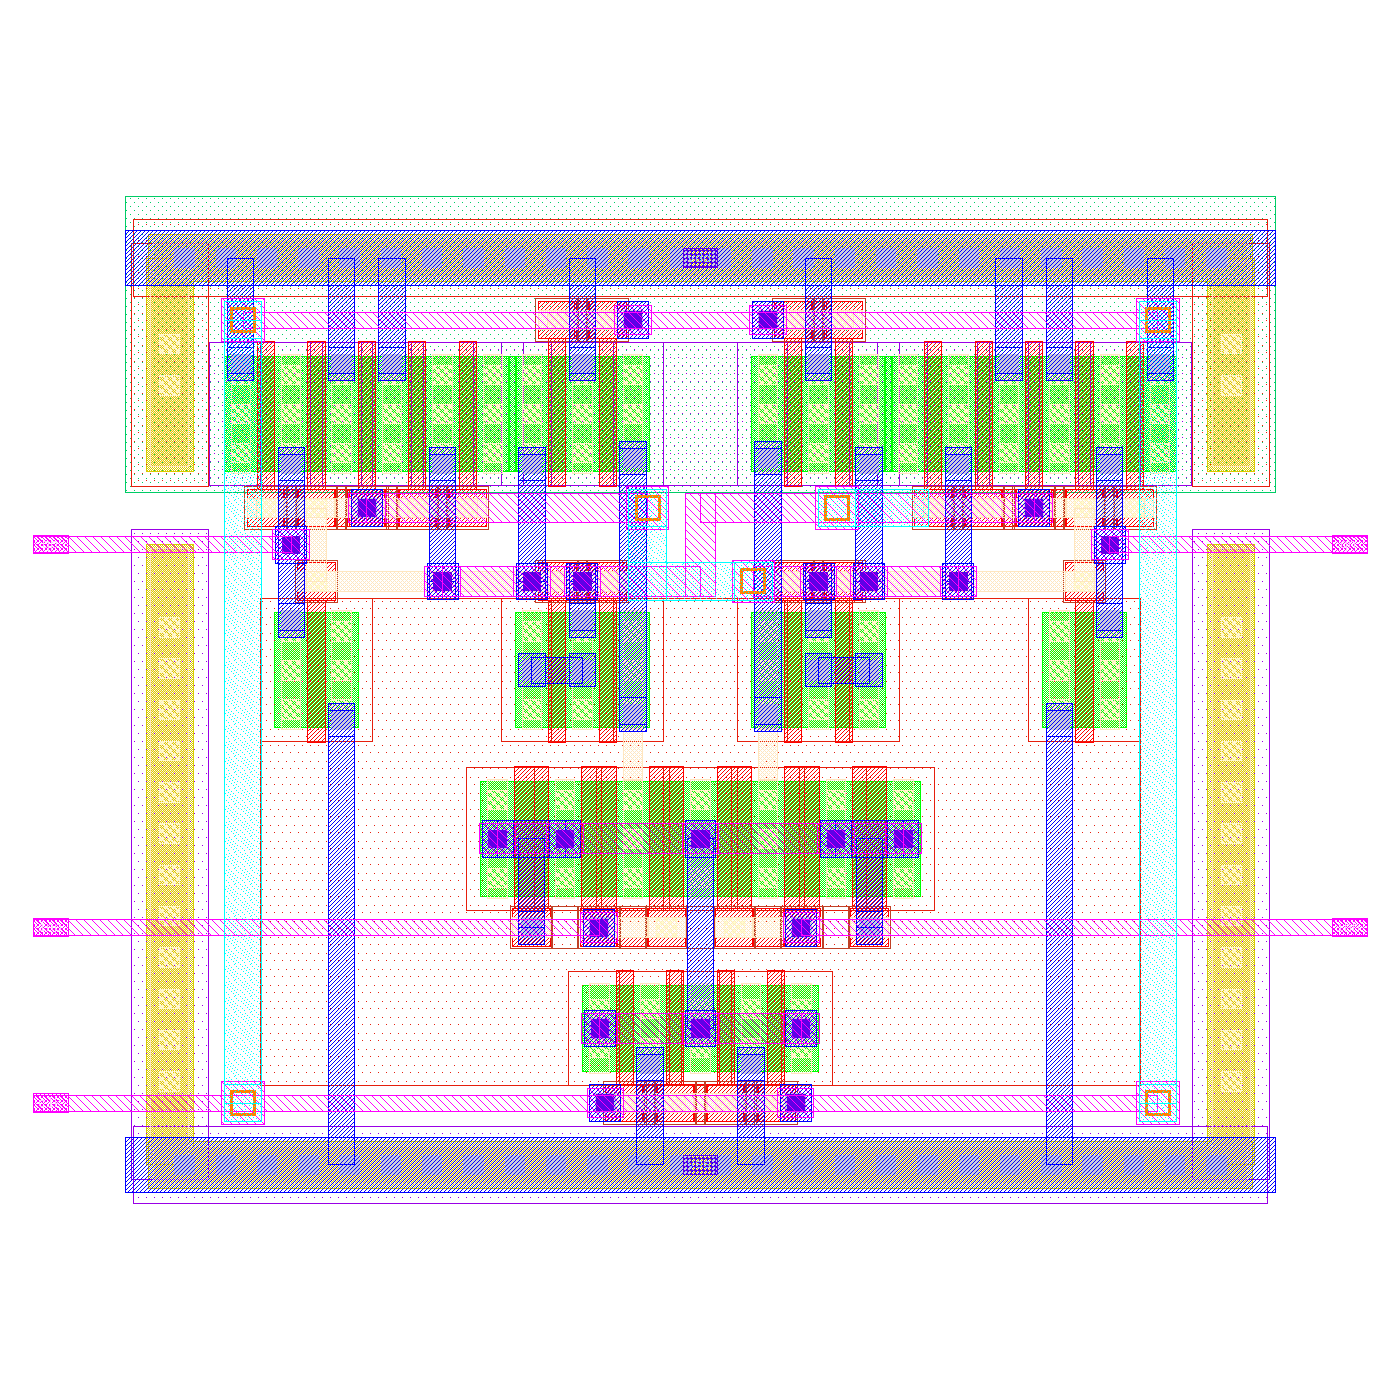

topsw


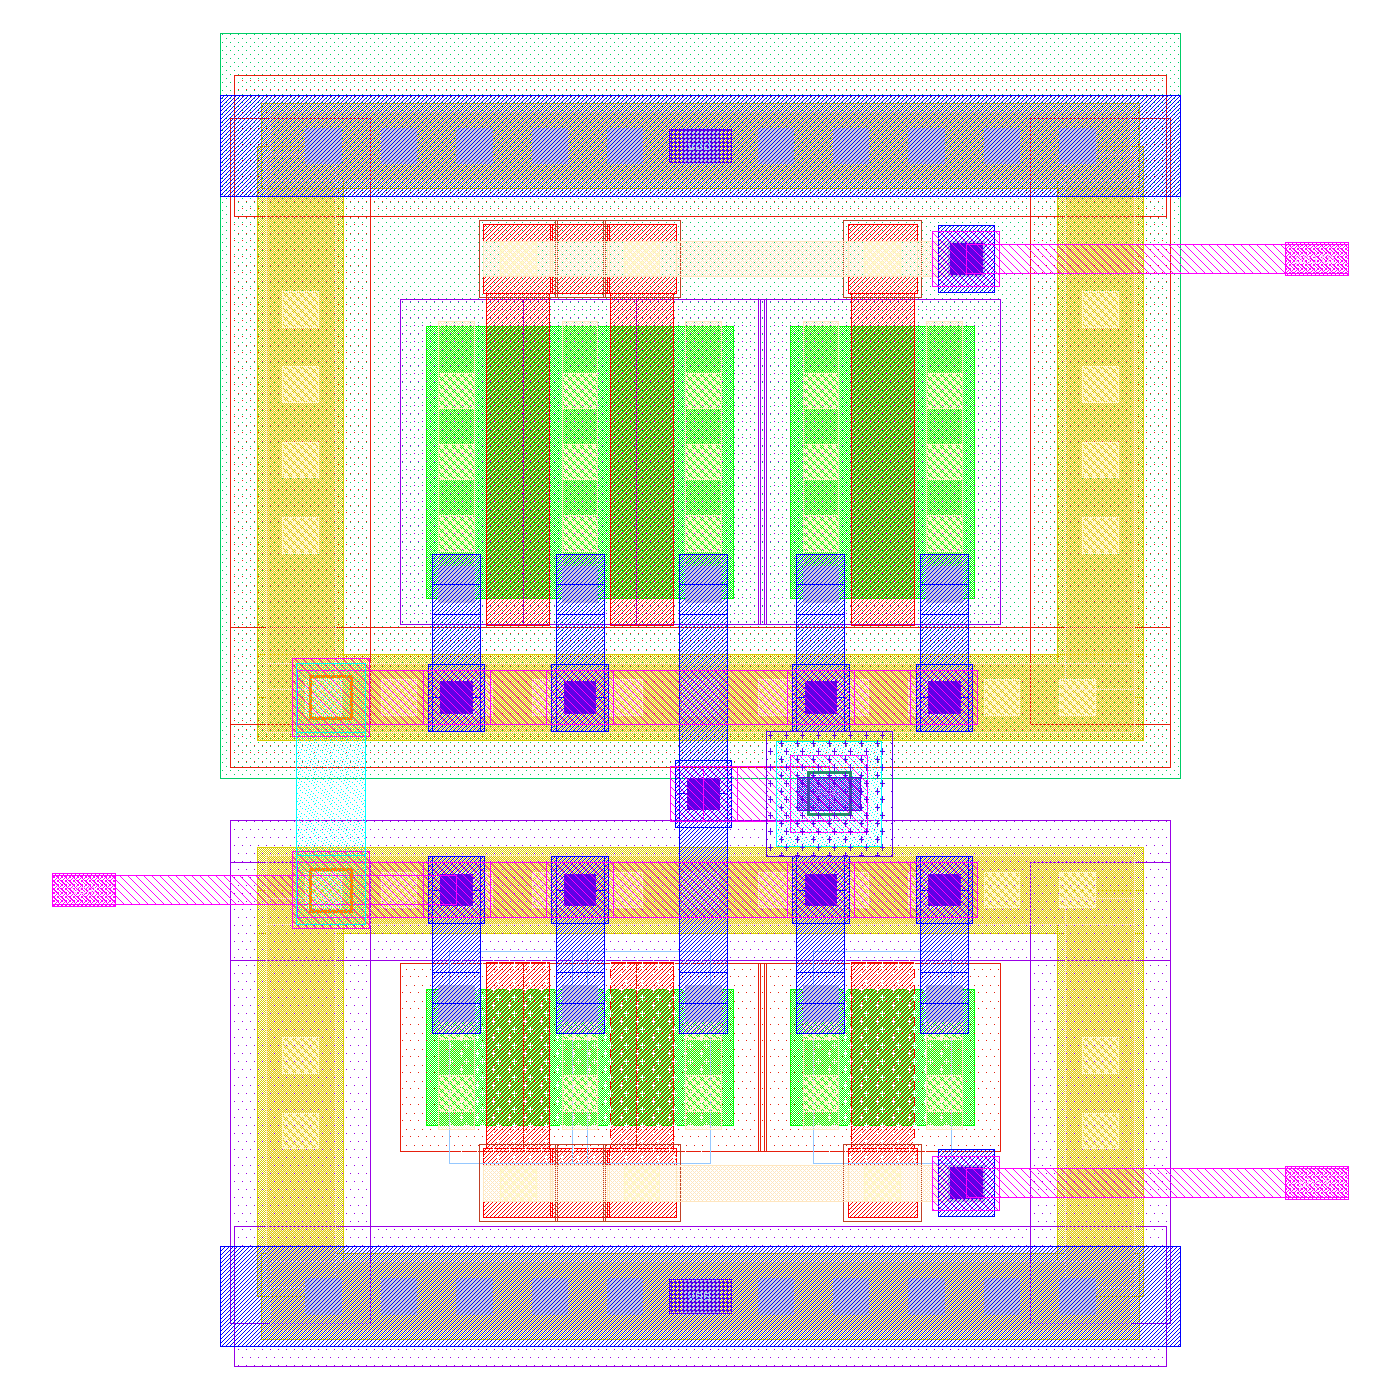

sar_logic


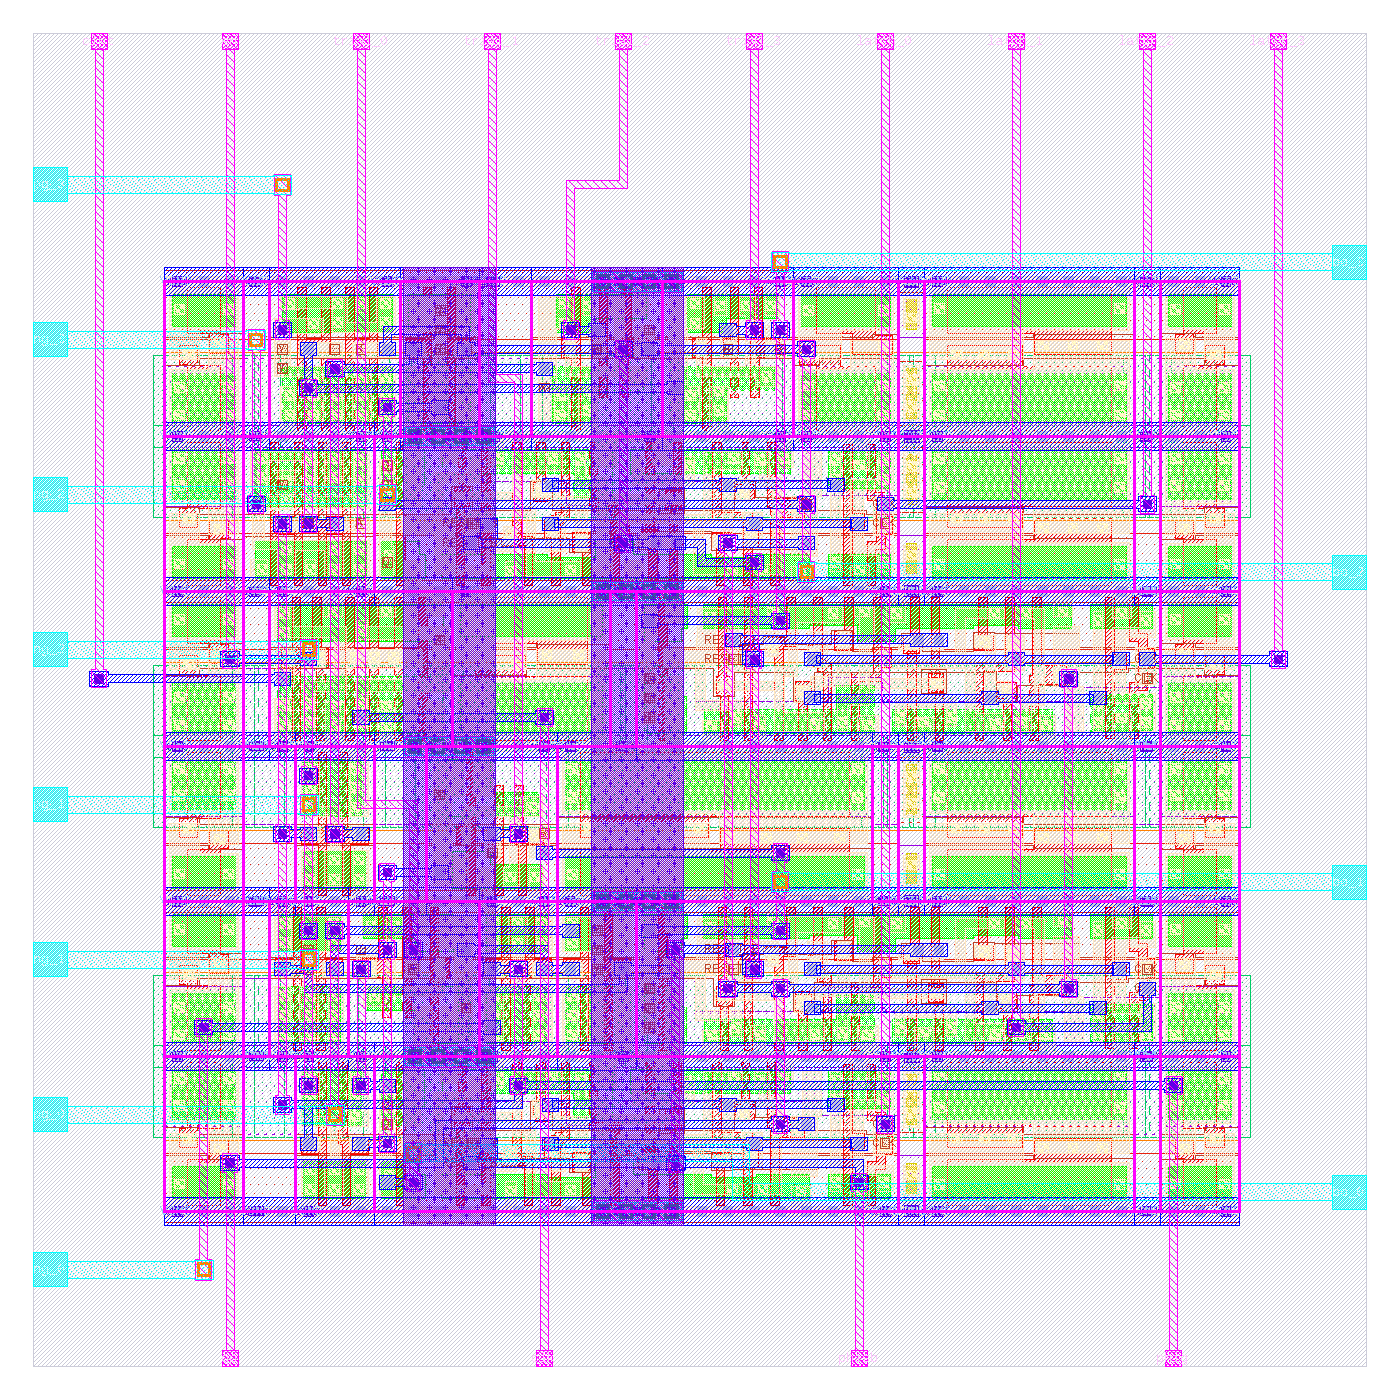

sar4b_core


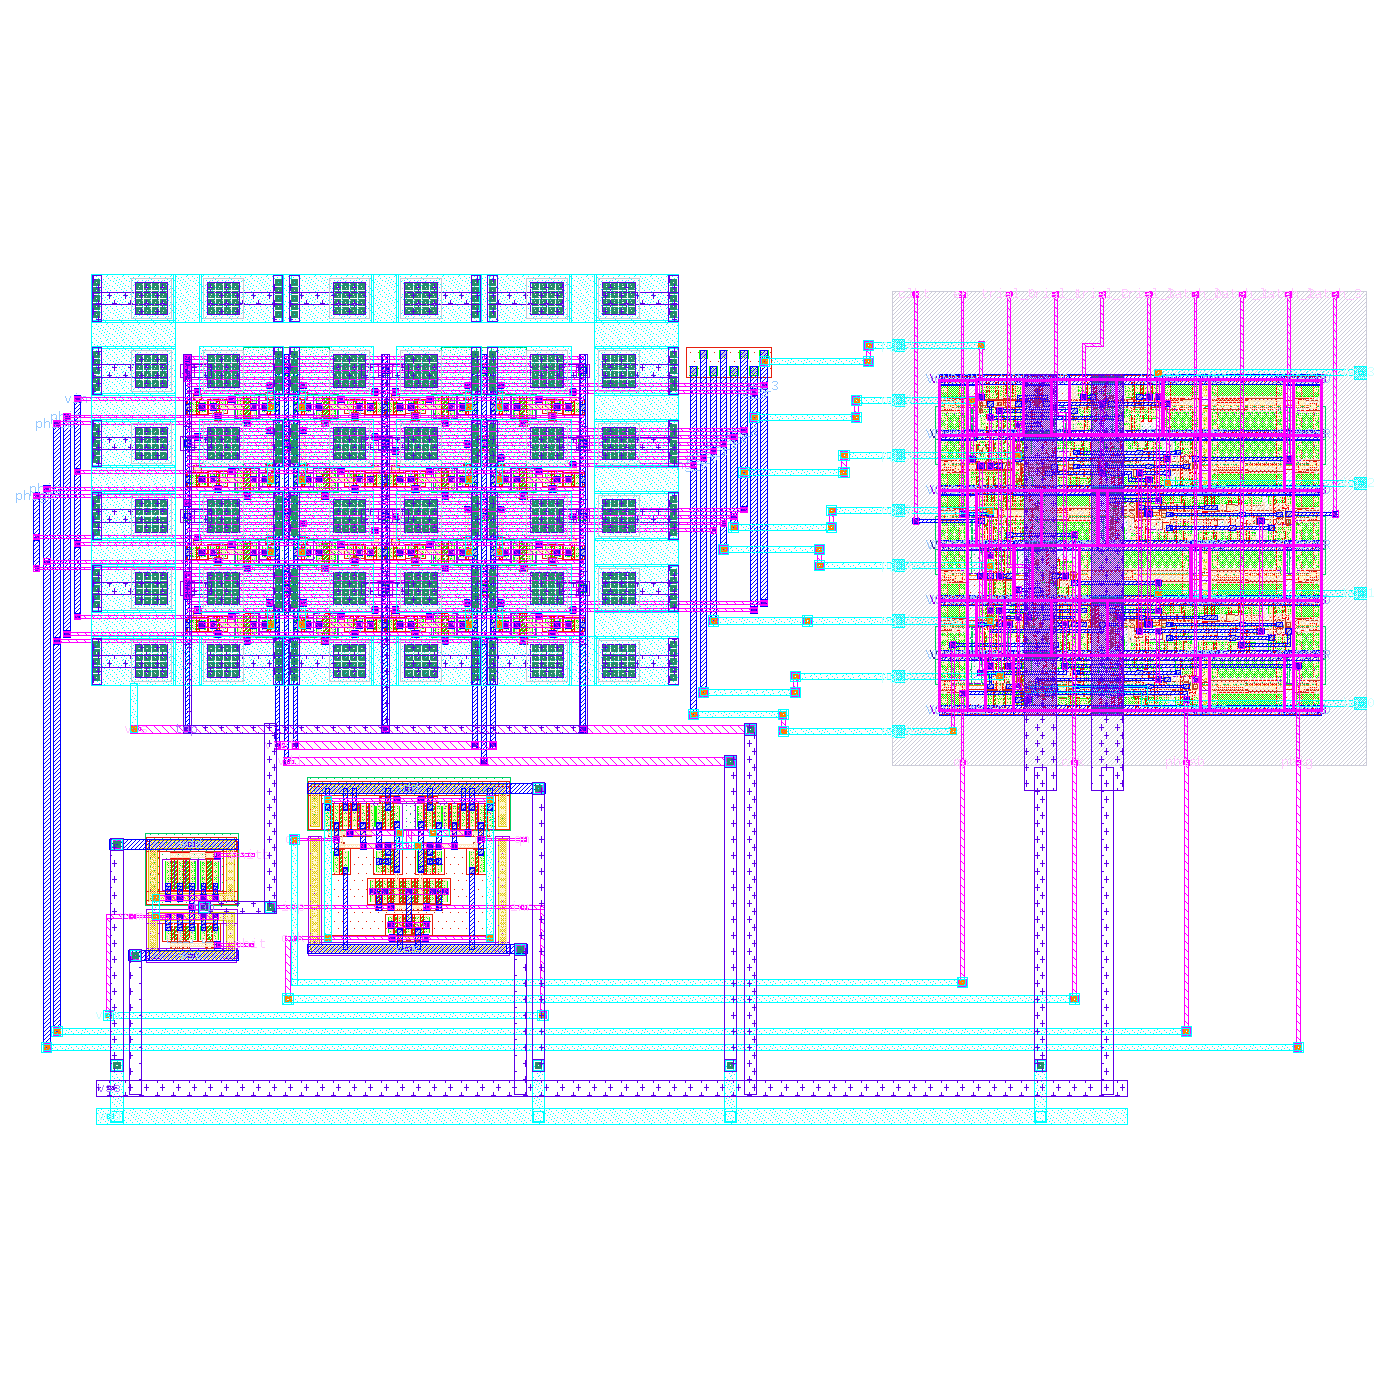

In [36]:
L = R / "4bit/layout"
show(L / "signoff.md")
for name in ("cdac_unit", "cdacu4b", "strongarm", "topsw", "sar_logic", "sar4b_core"):
    print(name); show(L / f"{name}.png")

**Pre- vs. post-layout** - the same testbench with extracted blocks (Magic, parasitic capacitance) in place of the
schematic ones; "full core from layout" replaces CDAC, comparator, top-plate switch and SAR logic by the extraction
of the routed core. The schematic and full-core columns are re-run with the current (leakage-aware) top-plate switch;
the block-level columns in between date from the original switch, which differed only in that one device.

In [37]:
show(L / "prepost.md")

| metric | schematic | extracted CDAC | extracted comparator | extracted CDAC + comparator | extracted switches | all blocks extracted | compact CDAC+switches | compact CDAC+switches + comparator | unit-cell CDAC | unit-cell CDAC + comparator | full core from layout |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ENOB [bit] | 3.973 | 3.981 | 3.987 | 3.978 | 3.972 | 3.997 | 3.906 | 3.933 | 3.952 | 3.976 | 3.959 |
| max DNL [LSB] | 0.096 | 0.104 | 0.037 | 0.029 | 0.070 | 0.037 | 0.137 | 0.070 | 0.004 | 0.037 | 0.070 |
| max INL [LSB] | 0.092 | 0.100 | 0.047 | 0.017 | 0.066 | 0.045 | 0.133 | 0.057 | 0.000 | 0.026 | 0.083 |
| offset [LSB] | -0.155 | -0.122 | -0.089 | -0.022 | -0.089 | 0.011 | -0.056 | 0.044 | -0.122 | -0.056 | -0.122 |
| gain error [LSB] | -0.021 | -0.055 | -0.021 | -0.021 | -0.055 | -0.021 | -0.287 | -0.254 | -0.055 | -0.088 | -0.021 |
| power [uW] | 13.876 | 14.677 | 15.209 | 22.477 | 17.022 | 25.572 | 19.901 | 27.691 | 17.393 | 19.165 | 26.382 |

**The extracted core across PVT** - the same corners as the schematic sweep of section 12, with the routed
core's extraction in place of every block (`studies/postlayout_pvt.py`). Linearity holds in the extracted
cores (this table: original top-plate switch; re-running it with the current switch is listed under open items);
power rises by ~80 %, mostly from the switch-control and clock wiring the logic drives and the CDAC's
bottom-plate parasitics (breakdown in `docs/layout_findings.md`, 6c).

| condition | ENOB [bit] | SNDR [dB] | SFDR [dB] | missing codes | max DNL [LSB] | max INL [LSB] | offset [LSB] | gain error [LSB] | power [µW] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| tt -40C 1.80V | 3.97 | 25.7 | 36.7 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 24.7 |
| tt +27C 1.80V | 3.98 | 25.7 | 37.4 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 25.4 |
| tt +125C 1.80V | 3.98 | 25.7 | 35.9 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 27.7 |
| ss -40C 1.80V | 4.01 | 25.9 | 34.3 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 24.9 |
| ss +27C 1.80V | 3.96 | 25.6 | 36.4 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 25.4 |
| ss +125C 1.80V | 3.95 | 25.5 | 36.6 | 0 | 0.129 | 0.0949 | -0.139 | 0.0781 | 26.5 |
| ff -40C 1.80V | 3.99 | 25.8 | 36.2 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 24.7 |
| ff +27C 1.80V | 3.97 | 25.7 | 34.6 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 25.9 |
| ff +125C 1.80V | 3.97 | 25.6 | 34.8 | 0 | 0.0703 | 0.0617 | -0.139 | 0.0117 | 35.6 |
| sf -40C 1.80V | 3.96 | 25.6 | 34 | 0 | 0.0703 | 0.0664 | -0.139 | -0.0547 | 24.8 |
| sf +27C 1.80V | 3.96 | 25.6 | 34 | 0 | 0.00391 | 1.3e-15 | -0.139 | -0.0547 | 25.4 |
| sf +125C 1.80V | 3.96 | 25.6 | 34 | 0 | 0.00391 | 1.3e-15 | -0.139 | -0.0547 | 26.6 |
| fs -40C 1.80V | 3.98 | 25.7 | 37.7 | 0 | 0.0703 | 0.0569 | -0.00586 | -0.121 | 25 |
| fs +27C 1.80V | 3.98 | 25.7 | 37.3 | 0 | 0.0703 | 0.0664 | -0.00586 | -0.0547 | 27.7 |
| fs +125C 1.80V | 3.98 | 25.7 | 36.5 | 0 | 0.129 | 0.123 | -0.205 | 0.0781 | 45 |
| tt +27C 1.62V | 3.97 | 25.6 | 36.2 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 20.4 |
| tt +27C 1.98V | 3.98 | 25.7 | 35.6 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 31.1 |

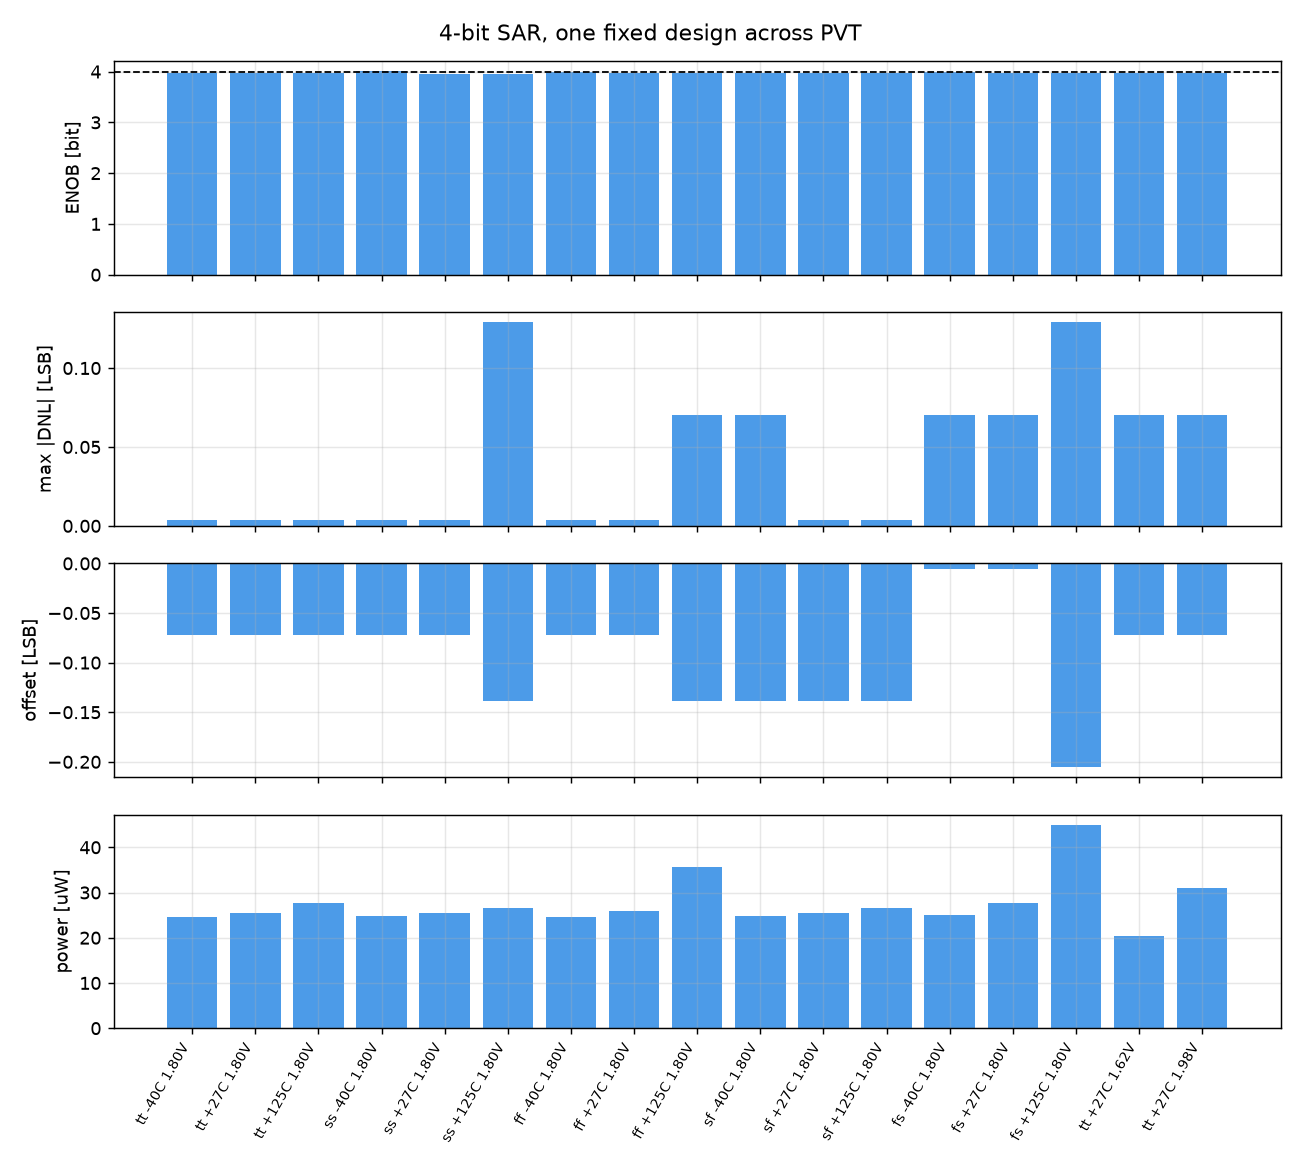

In [38]:
show(L / "pvt_core.md"); show(L / "pvt_core.png")

**The same generators at 6 bit** - 64 unit capacitors instead of 16 in the same common-centroid packing and dummy ring, a larger top-plate
switch and SAR logic; nothing was redrawn by hand. (The pre/post-layout table below was simulated with the original
top-plate switch; the core and its signoff are the current ones, and the switch alone is verified in section 12f.)

| block | size [um] | area [um^2] | KLayout DRC (incl. capm.10) | magic DRC | LVS |
| --- | --- | --- | --- | --- | --- |
| 6-bit CDAC (common-centroid, dummy-cap ring) | 57.91 x 38.58 | 2234 | 0 | 0 | match (321/321 devices) |
| StrongARM comparator | 13.19 x 8.99 | 119 | 0 | 0 | match (22/22 devices) |
| top-plate sampling switch (guard rings) | 7.40 x 7.69 | 57 | 0 | 0 | match (4/4 devices) |
| SAR logic (LibreLane, sky130_fd_sc_hd) | 28.30 x 28.30 | 801 | 0 | 0 | match (30/30 devices) |
| 6-bit SAR ADC core (all blocks routed) | 94.61 x 56.89 | 5382 | 0 | 0 | match (4/4 block instances) |

cdacu6b


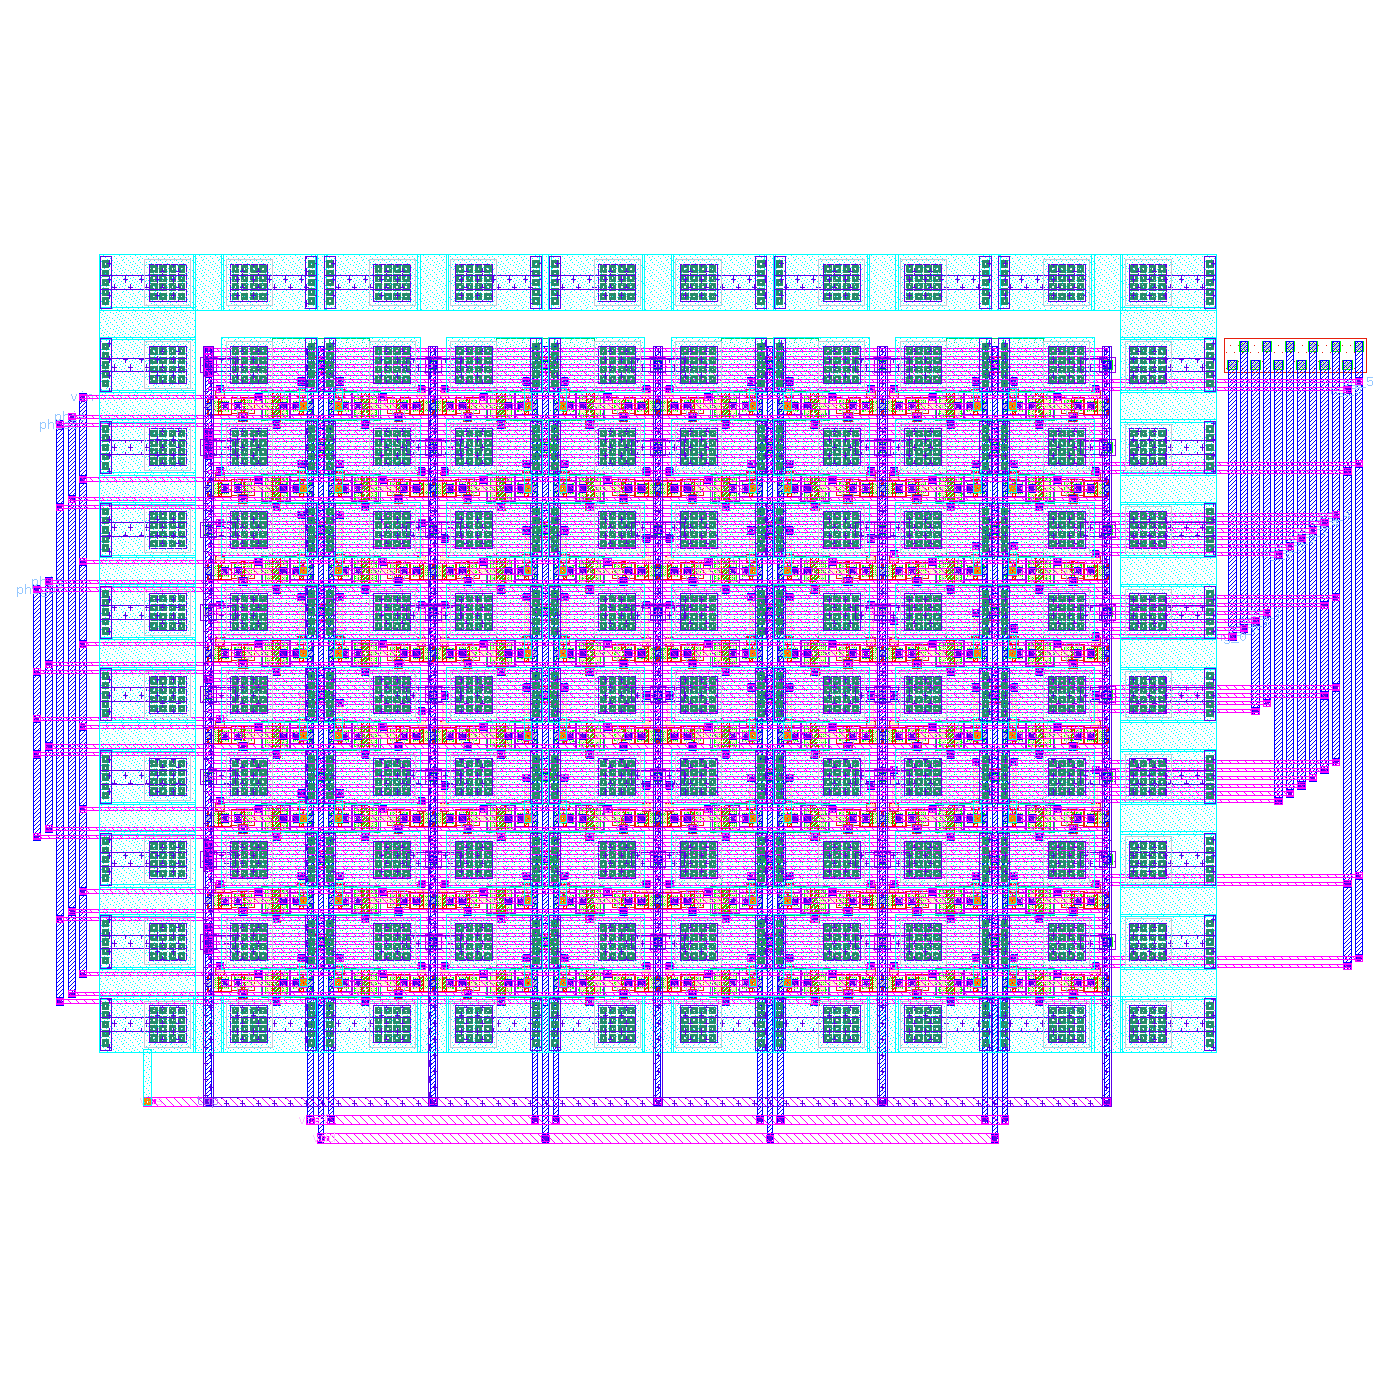

sar6b_core


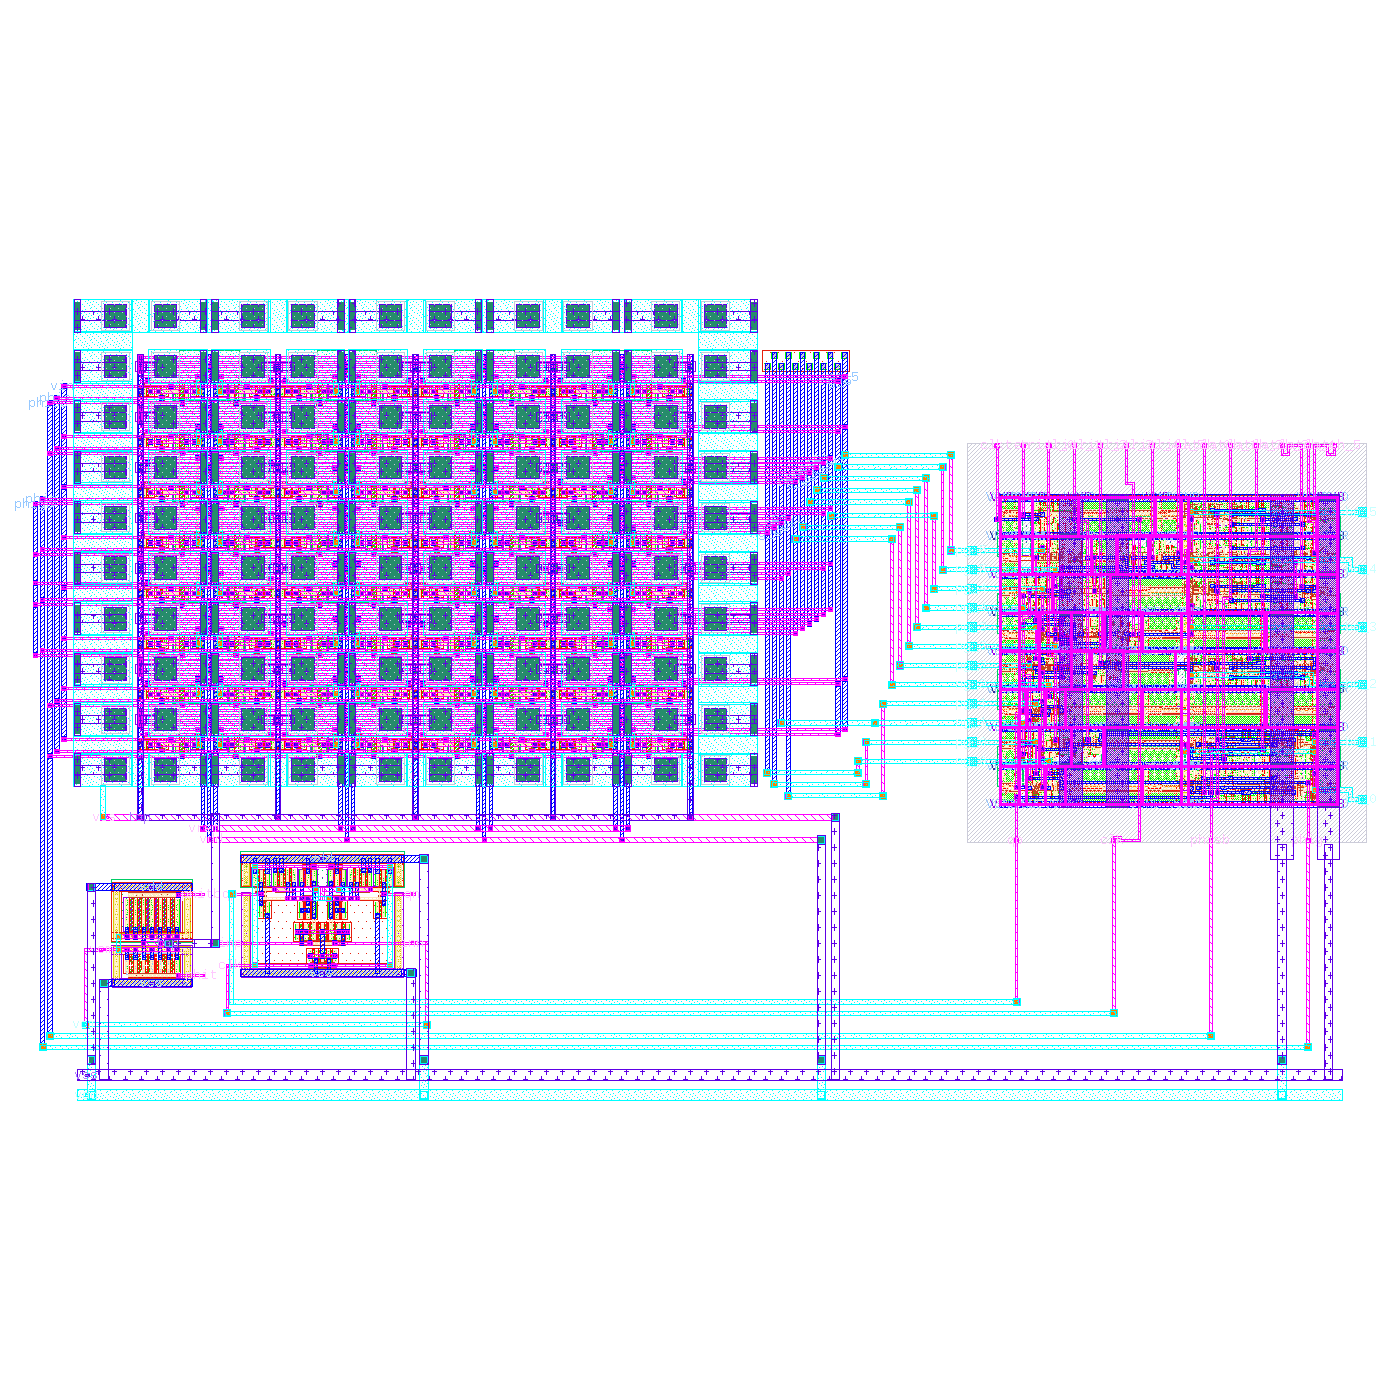

| metric | schematic | full core from layout |
| --- | --- | --- |
| ENOB [bit] | 6.010 | 6.024 |
| max DNL [LSB] | 0.207 | 0.048 |
| max INL [LSB] | 0.165 | 0.067 |
| offset [LSB] | -0.119 | -0.183 |
| gain error [LSB] | 0.017 | -0.110 |
| power [uW] | 33.821 | 63.088 |

In [39]:
L6 = R / "6bit/layout"
show(L6 / "signoff.md")
for name in ("cdacu6b", "sar6b_core"):
    print(name); show(L6 / f"{name}.png")
show(L6 / "prepost.md")

**The same generators at 8 bit** - 256 unit capacitors in the same packing and dummy ring, the comparator with a
14-finger input pair, 28-finger tail and 9-finger latch, a 47 + 95 um top-plate switch (24 + 24 fingers, L = 0.3 um) and
the 8-bit SAR logic,
routed into one core. At 8 bit the sizing makes the unit cap matching-limited (2.7 x 2.7 um instead of the 2 um minimum),
and the layout uses the sized cap, so schematic and layout compare the same array. The extracted 8-bit core takes
~2.7 h per transient run, so post-layout uses 4 ramp hits per code: DNL is resolved in 1/4-LSB steps, while ENOB
(coherent FFT) is unaffected. The top-plate wiring adds ~330 fF, but its coupling to the bottom plates is the same
1.00 fF on every unit cap, so it scales all bit weights alike.

| block | size [um] | area [um^2] | KLayout DRC (incl. capm.10) | magic DRC | LVS |
| --- | --- | --- | --- | --- | --- |
| CDAC unit cell (MIM cap + its own switches) | 6.35 x 5.67 | 36 | 0 | 0 | match (5/5 devices) |
| unit-cell abutment test (2 x 3) | 18.17 x 13.16 | 239 | 0 | 0 | match (30/30 devices) |
| 8-bit CDAC (common-centroid, dummy-cap ring) | 112.45 x 79.45 | 8935 | 0 | 0 | match (1281/1281 devices) |
| StrongARM comparator | 24.56 x 12.47 | 306 | 0 | 0 | match (24/24 devices) |
| top-plate sampling switch (guard rings) | 19.20 x 10.33 | 198 | 0 | 0 | match (4/4 devices) |
| SAR logic (LibreLane, sky130_fd_sc_hd) | 33.50 x 33.50 | 1122 | 0 | 0 | match (38/38 devices) |
| 8-bit SAR ADC core (all blocks routed) | 156.75 x 101.14 | 15854 | 0 | 0 | match (4/4 block instances) |

cdacu8b


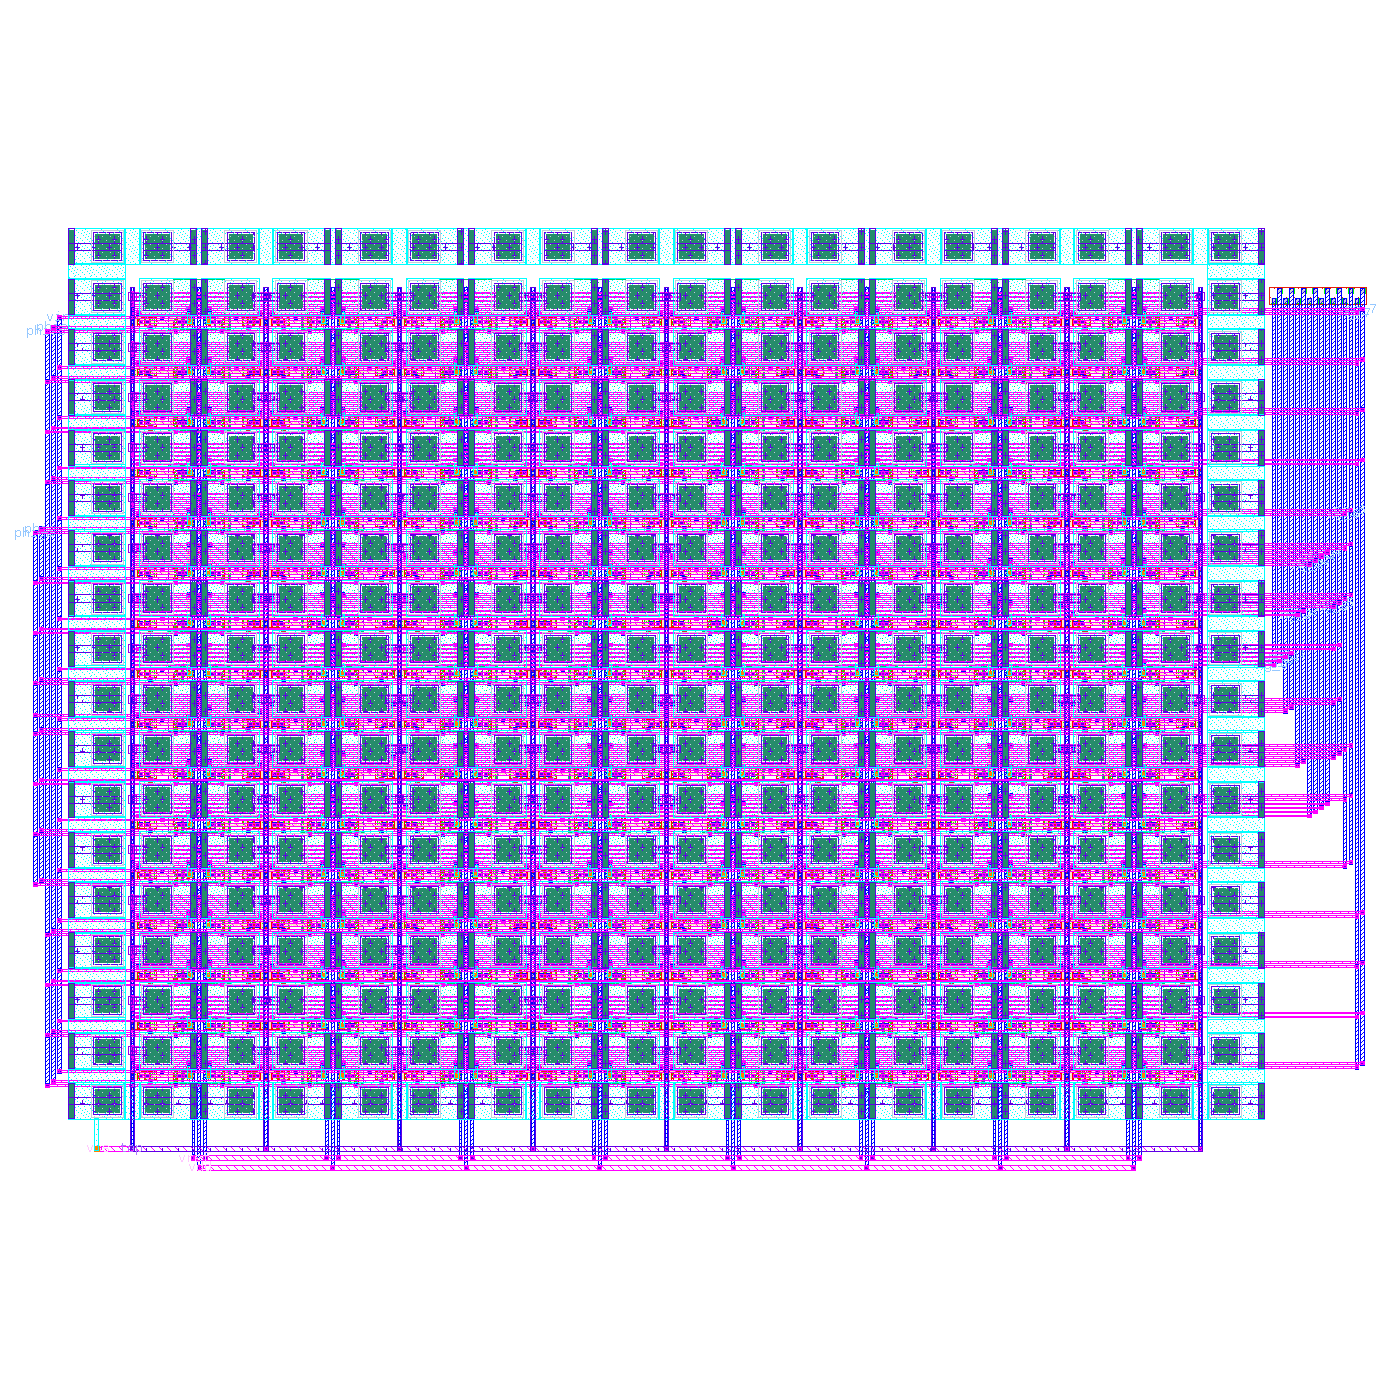

strongarm


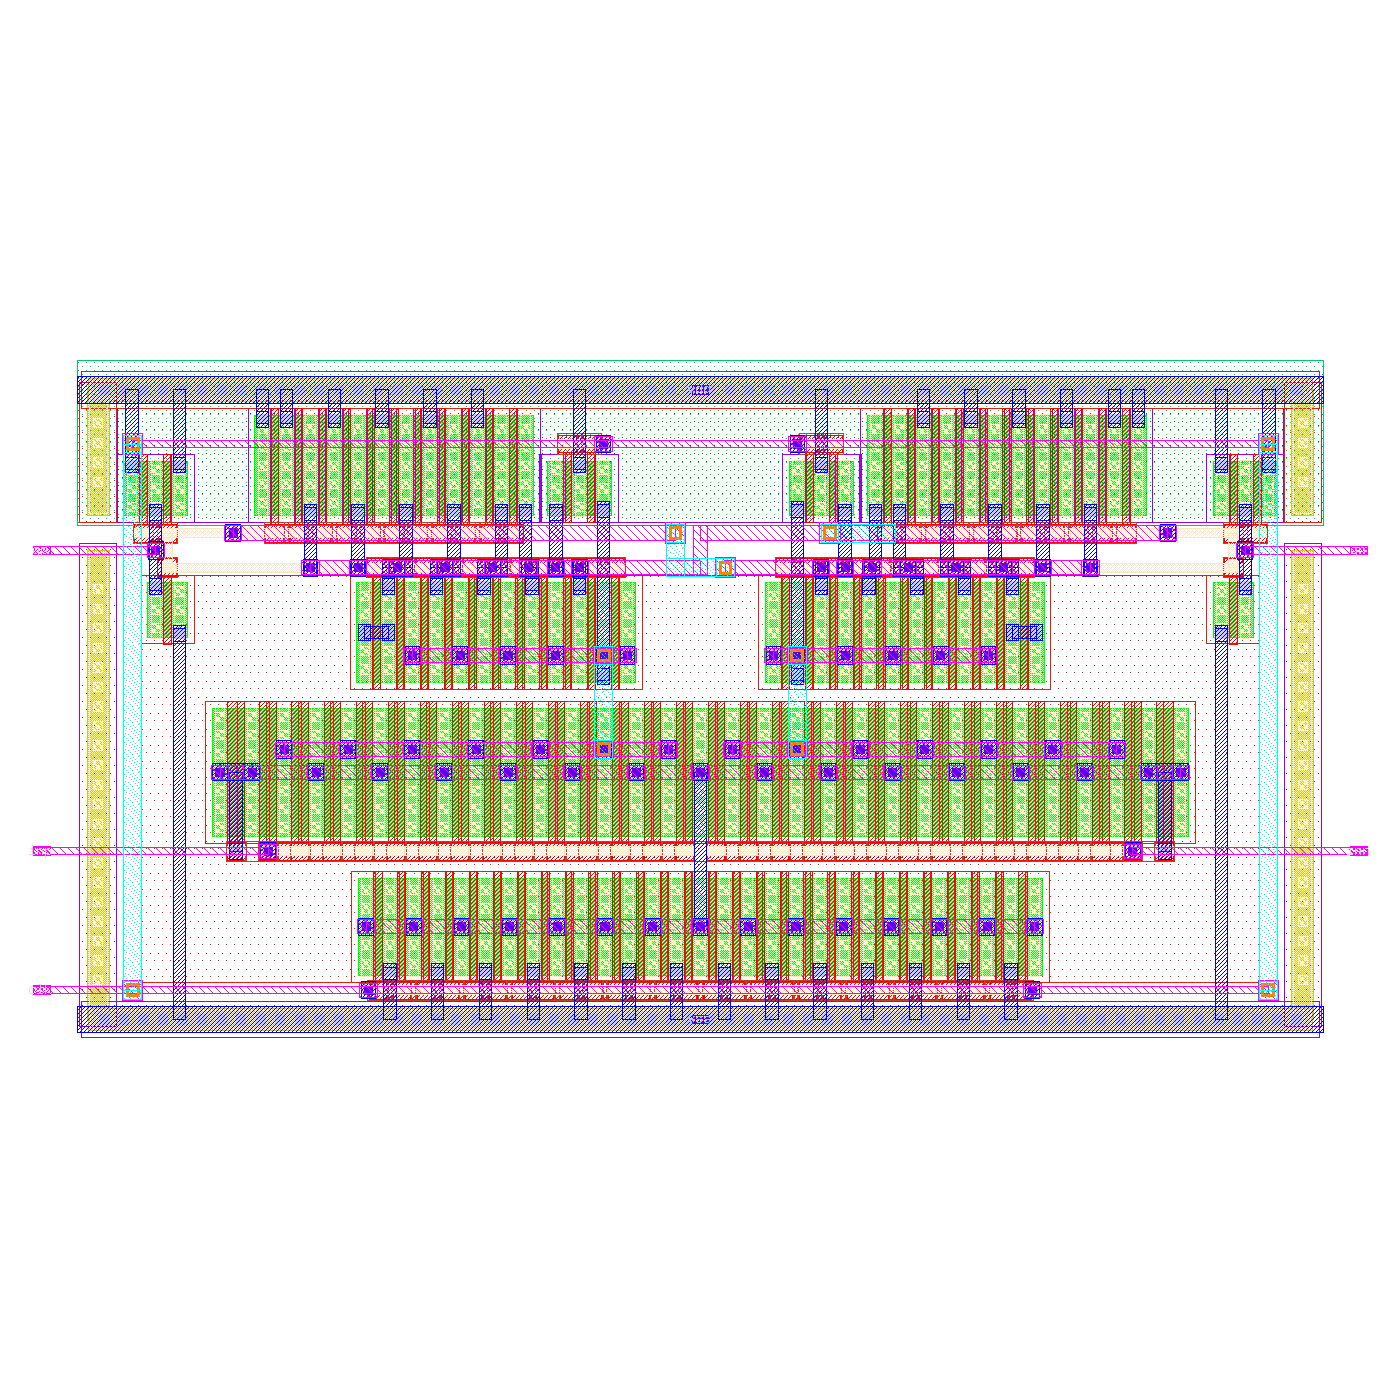

topsw


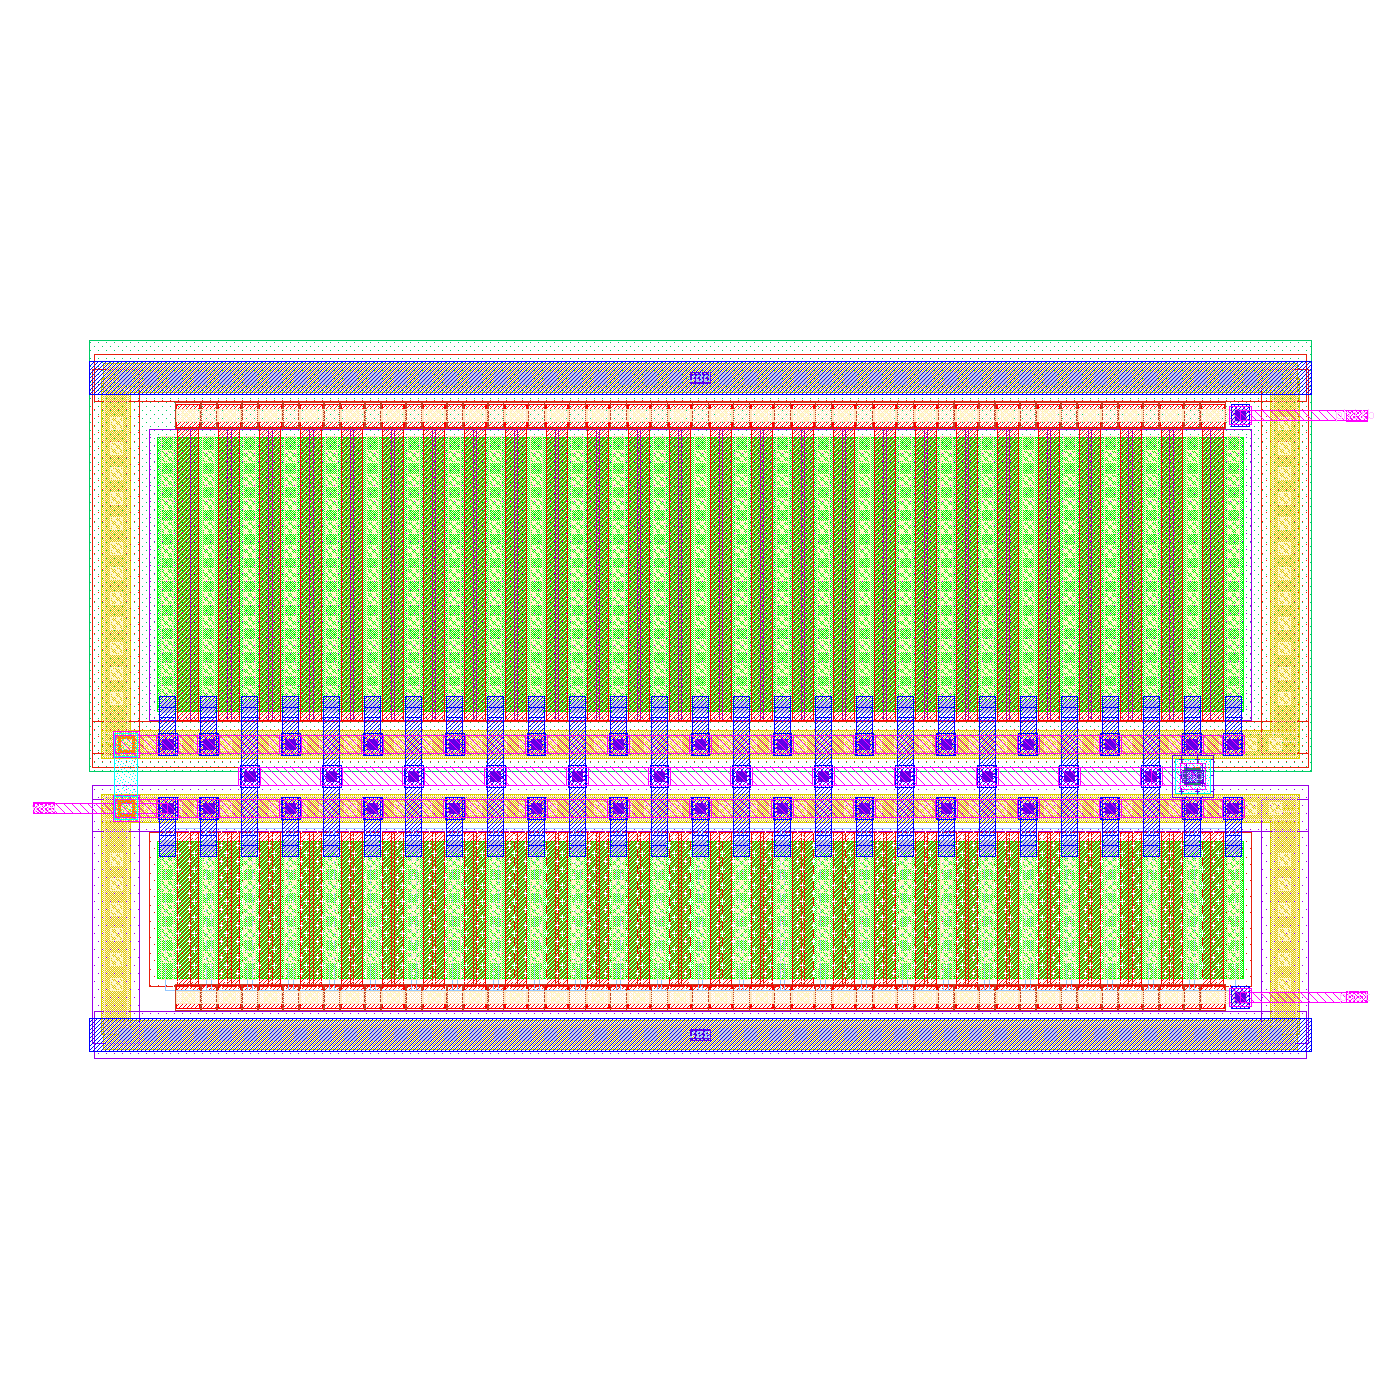

sar8b_core


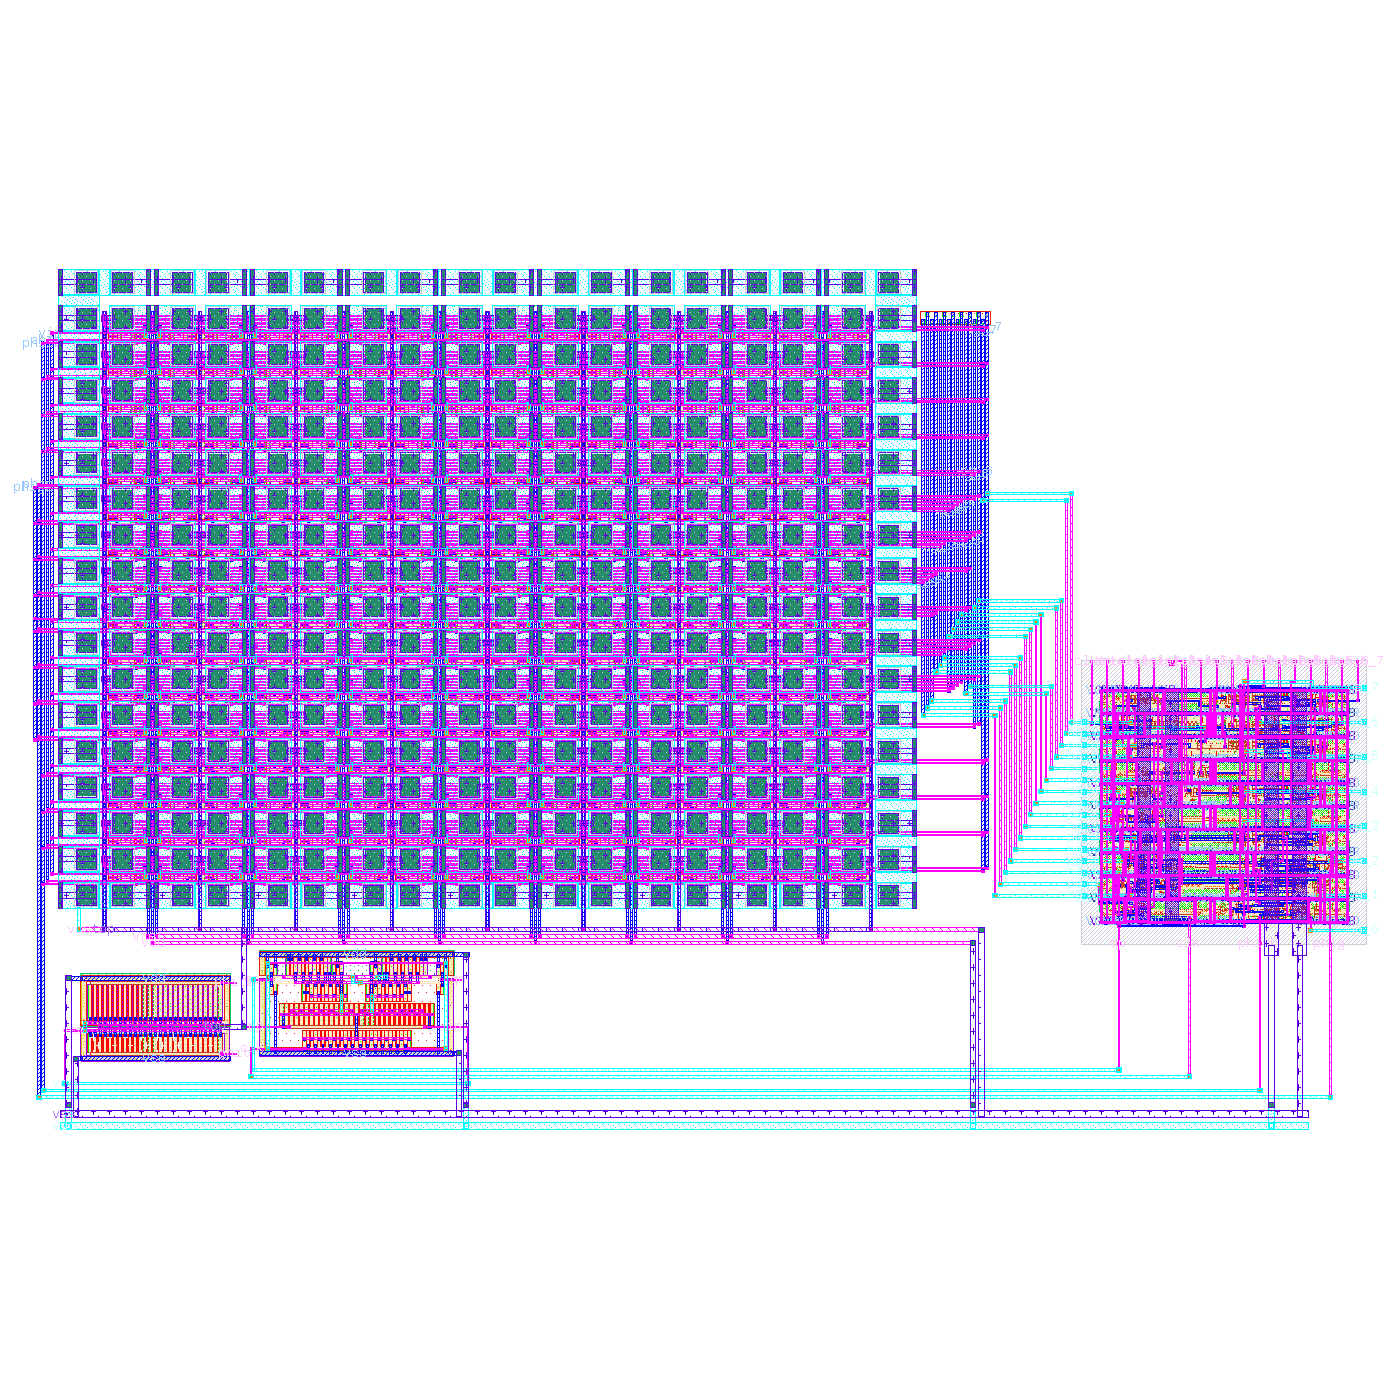

| metric | schematic | full core from layout | unit-cell CDAC |
| --- | --- | --- | --- |
| ENOB [bit] | 7.677 | 7.712 | 7.938 |
| max DNL [LSB] | 0.373 | 0.255 | 0.255 |
| max INL [LSB] | 0.369 | 0.218 | 0.298 |
| offset [LSB] | -1.500 | -1.375 | -0.873 |
| gain error [LSB] | -0.890 | -0.765 | -0.765 |
| power [uW] | 186.876 | 288.687 | 251.406 |

In [40]:
L8 = R / "8bit/layout"
show(L8 / "signoff.md")
for name in ("cdacu8b", "strongarm", "topsw", "sar8b_core"):
    print(name); show(L8 / f"{name}.png")
show(L8 / "prepost.md")

**Why the 8-bit ENOB is ~7.7 at full scale (schematic and layout alike), and why it is not distortion.** The
standard test sine spans 0.99 of the input range, which leaves 1.3 LSB of headroom at each end. The leakage-aware
top-plate switch (section 12f) is wider, so it injects more charge when it opens: the codes sit ~2 LSB above
mid-scale, the sine's peaks run into the last code, and the clipped peaks add harmonics. Repeating only the sine at
-0.5 dBFS (`studies/sine_backoff.py`) removes the clipping: ENOB 7.85 (schematic) and 7.88 (extracted core), so
layout costs nothing; DNL / INL stay within 0.4 LSB. A static
offset is removed by a one-time digital calibration; balancing the switch's charge injection is on the roadmap.
(In the table above, the unit-cell CDAC column was simulated with the original switch.)

In [41]:
show(L8 / "sine_backoff.md")

8-bit, 128-point coherent FFT at 1.02 MHz. Full scale = 0.99 of the input range (prepost.json); backed off = -0.5 dBFS.

| case | ENOB full scale | ENOB at -0.5 dBFS | SFDR at -0.5 dBFS [dB] | samples at the end codes | mean code - mid-scale |
| --- | --- | --- | --- | --- | --- |
| schematic | 7.68 | 7.85 | 59.5 | 0 | +1.99 |
| full core from layout | 7.71 | 7.88 | 57.4 | 0 | +1.75 |

**Matching rules in the generated layout, and checking them.** The comparator follows the usual rules for matched
devices [7]: mirror symmetry about one axis (clock and tail on it), identical surroundings for both halves, matched
devices close together, all gates in one direction, and a dummy finger at both ends of every matched device. Three
checks show what this buys, with the tools at hand:

1. **Length of diffusion (LOD).** SKY130's transistor models change a device's current with the distance from its
   gate to the end of its diffusion (stress): up to 0.6x - 1.7x here. The extraction does not write these distances
   (every device gets "stress off"), so the generator computes them per finger from its own placement
   (`sargen/layout/lod.py`) and writes them into the netlist. Both halves of every matched pair come out identical, and
   the end dummies lengthen the shortest diffusion of the latch fingers from 0.29 to 0.73 um, which pulls the latch
   PMOS current closer to its nominal value (`studies/lod_matching.py`).
2. **The extracted comparator, before and after** (`studies/comparator_layout_ab.py`): the systematic offset from
   wiring parasitics drops from 1.3 / 1.5 mV to 0.2 / 0.3 mV at 4 / 6 bit; at 8 bit it moves from +0.4 to -0.7 mV
   (0.09 LSB, a residual of the new link routing). The dummies' gate capacitance costs 16 - 22 % of delay, far inside
   the time a bit decision gets; the random offset spread is unchanged and within its sizing target.
3. **The whole 8-bit ADC with the drawn devices** (`studies/lod_system.py`, offset and gain to 1/32 LSB): neither the
   stress effect nor the dummies move the offset by more than 0.06 LSB, and neither does the simulator tolerance: the
   ~1.7 LSB offset belongs to the top-plate switch's charge injection (above), not to the layout or the numerics.

In [42]:
show(L8 / "lod_matching.md")
for b in (4, 6, 8):
    show(R / f"{b}bit/layout/comparator_layout_ab.md")
show(L8 / "lod_system.md")

### 8-bit: matched devices as drawn, before / after the end dummies

| pair | fingers | shortest diffusion, before -> after [um] | longest [um] | identical on both sides |
| --- | --- | --- | --- | --- |
| Mi1 / Mi2 | 14 | 0.88 -> 0.88 | 16.81 | yes |
| Mn1 / Mn2 | 9 | 0.29 -> 0.73 | 4.25 | yes |
| Mp1 / Mp2 | 9 | 0.29 -> 0.73 | 4.25 | yes |
| Mr1 / Mr2 | 1 | 0.29 -> 0.29 | 0.73 | yes |
| Mr3 / Mr4 | 1 | 0.29 -> 0.29 | 0.73 | yes |
| Mon1 / Mon2 | 1 | 0.29 -> 0.29 | 0.29 | yes |
| Mop1 / Mop2 | 2 | 0.29 -> 0.29 | 0.73 | yes |
| Md1 / Md2 | 1 | 0.29 -> 0.29 | 17.40 | yes |
| Mdl1 / Mdl2 | 1 | 0.29 -> 0.29 | 4.69 | yes |
| top switch Mttn | 24 -> 24 | 0.29 -> 0.88 | 14.45 | - |
| top switch Mttp | 48 -> 24 | 0.29 -> 0.88 | 14.45 | - |

### Current with the drawn diffusion lengths / with the stress off (sa = sb = 0)

| block | device | saturation, before | after | triode (switch on), before | after |
| --- | --- | --- | --- | --- | --- |
| strongarm | Md1 | 0.943 | 0.943 | 0.991 | 0.991 |
| strongarm | Md2 | 0.943 | 0.943 | 0.991 | 0.991 |
| strongarm | Mdl1 | 0.918 | 0.920 | 0.988 | 0.988 |
| strongarm | Mdl2 | 0.918 | 0.920 | 0.988 | 0.988 |
| strongarm | Mi1 | 1.070 | 1.070 | 1.011 | 1.011 |
| strongarm | Mi2 | 1.070 | 1.070 | 1.011 | 1.011 |
| strongarm | Mn1 | 1.036 | 1.055 | 1.005 | 1.008 |
| strongarm | Mn2 | 1.036 | 1.055 | 1.005 | 1.008 |
| strongarm | Mon1 | 0.761 | 0.761 | 0.965 | 0.965 |
| strongarm | Mon2 | 0.761 | 0.761 | 0.965 | 0.965 |
| strongarm | Mop1 | 1.354 | 1.354 | 1.061 | 1.061 |
| strongarm | Mop2 | 1.354 | 1.354 | 1.061 | 1.061 |
| strongarm | Mp1 | 0.965 | 0.860 | 0.993 | 0.976 |
| strongarm | Mp2 | 0.965 | 0.860 | 0.993 | 0.976 |
| strongarm | Mr1 | 1.354 | 1.354 | 1.061 | 1.061 |
| strongarm | Mr2 | 1.354 | 1.354 | 1.061 | 1.061 |
| strongarm | Mr3 | 1.354 | 1.354 | 1.061 | 1.061 |
| strongarm | Mr4 | 1.354 | 1.354 | 1.061 | 1.061 |
| strongarm | Mt | 1.080 | 1.080 | 1.011 | 1.011 |
| topsw | Mttn | 1.029 | 1.035 | 1.006 | 1.008 |
| topsw | Mttp | 0.615 | 0.606 | 0.960 | 0.960 |

CDAC unit-cell switches: stand-alone fingers, sa = sb = 0.29 um in every cell (unchanged).

### Comparator as drawn, no mismatch (offset resolution 10 uV)

| netlist | systematic offset [uV] | delay at +1 mV [ps] | delay at -1 mV [ps] |
| --- | --- | --- | --- |
| schematic | +5 | 185 | 186 |
| before, stress off | +5 | 184 | 185 |
| before, with LOD | +5 | 161 | 161 |
| after, stress off | +5 | 195 | 196 |
| after, with LOD | +5 | 168 | 169 |

4-bit comparator, layout extraction (Magic, parasitic C).

| layout | systematic offset [uV] | delay at offset +-1 mV [ps] | Monte Carlo sigma [mV] (n) | MC mean [mV] |
| --- | --- | --- | --- | --- |
| before | +1295 | 584 / 589 | 9.32 (96) | +2.46 |
| after | +155 | 708 / 715 | 9.63 (96) | +0.33 |

Sizing target sigma 37.50 mV.

6-bit comparator, layout extraction (Magic, parasitic C).

| layout | systematic offset [uV] | delay at offset +-1 mV [ps] | Monte Carlo sigma [mV] (n) | MC mean [mV] |
| --- | --- | --- | --- | --- |
| before | +1455 | 574 / 578 | 8.00 (96) | +2.21 |
| after | -275 | 698 / 705 | 9.18 (96) | -1.40 |

Sizing target sigma 9.38 mV.

8-bit comparator, layout extraction (Magic, parasitic C).

| layout | systematic offset [uV] | delay at offset +-1 mV [ps] | Monte Carlo sigma [mV] (n) | MC mean [mV] |
| --- | --- | --- | --- | --- |
| before | +425 | 222 / 223 | 2.20 (96) | +0.45 |
| after | -655 | 258 / 262 | 2.14 (96) | -0.23 |

Sizing target sigma 2.34 mV.

8-bit schematic testbench; comparator, top-plate switch and CDAC unit switches as drawn where noted.

| case | offset [LSB] | gain error [LSB] |
| --- | --- | --- |
| schematic, default tolerances | -1.734 | -0.625 |
| schematic | -1.672 | -0.594 |
| as drawn before, stress off | -1.609 | -0.594 |
| as drawn before, with LOD | -1.672 | -0.562 |
| as drawn after, stress off | -1.609 | -0.594 |
| as drawn after, with LOD | -1.672 | -0.562 |

Endpoint ramps of 32 points per LSB (resolution 1/32 LSB).

**Top-plate switch threshold vs. PVT** (schematic, fixed 4-bit design with the original switch;
`studies/top_switch_leakage.py`). The floating top plate leaks through the switch's PMOS when hot (LVT), but the same
PMOS carries the settling when cold (standard-Vt): at equal size no single threshold wins every corner. This study led
to the leakage-aware sizing rule of section 12f (size at V<sub>cm</sub>, then the least leaky flavour within a width
cap), which every core above now uses.

In [43]:
show(R / "4bit/sweeps/top_switch_leakage.md")

| top-plate switch | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| LVT N + LVT P (sized) | 3.96 | 0.195 | 0.185 | -0.27 | +0.14 | 23.5 |
| LVT N + LVT P (sized) | 3.95 | 0.262 | 0.285 | -0.40 | +0.28 | 31.1 |
| LVT N + LVT P (sized) | 3.98 | 0.063 | 0.057 | -0.07 | +0.01 | 13.6 |
| LVT N + LVT P (sized) | 3.96 | 0.129 | 0.100 | -0.14 | +0.01 | 13.9 |
| SVT N + SVT P | 3.97 | 0.070 | 0.057 | -0.14 | +0.01 | 23.2 |
| SVT N + SVT P | 3.98 | 0.070 | 0.062 | -0.14 | +0.01 | 30.9 |
| SVT N + SVT P | 3.98 | 0.004 | 0.000 | -0.07 | -0.05 | 13.4 |
| SVT N + SVT P | 2.99 | 0.203 | - | +1.79 | +nan | 10.8 |
| SVT N + SVT P | 3.19 | 0.203 | 0.180 | +0.99 | -0.12 | 13.6 |
| SVT N + SVT P | 3.94 | 0.129 | 0.066 | -0.07 | -0.05 | 13.9 |
| SVT N + LVT P | 3.96 | 0.195 | 0.185 | -0.27 | +0.14 | 23.4 |
| SVT N + LVT P | 3.94 | 0.328 | 0.332 | -0.47 | +0.41 | 31.0 |
| SVT N + LVT P | 3.97 | 0.004 | 0.000 | -0.07 | -0.05 | 13.4 |
| SVT N + LVT P | 3.74 | 0.129 | 0.100 | -0.07 | +0.01 | 10.9 |
| SVT N + LVT P | 3.99 | 0.070 | 0.066 | -0.07 | -0.05 | 13.6 |
| SVT N + LVT P | 3.98 | 0.129 | 0.076 | -0.14 | +0.08 | 13.9 |
| LVT N + SVT P | 3.98 | 0.070 | 0.057 | -0.14 | +0.01 | 23.4 |
| LVT N + SVT P | 3.98 | 0.070 | 0.066 | -0.07 | -0.05 | 30.9 |
| LVT N + SVT P | 3.29 | 0.527 | 0.474 | +0.13 | +0.34 | 10.7 |
| LVT N + SVT P | 3.60 | 0.070 | 0.066 | -0.07 | -0.05 | 13.5 |

**Checks beyond the ideal testbench** (studies inspired by the design literature; scripts in `studies/`).

* *Comparator noise* - ngspice has no device noise in transient analysis, so the input pair's thermal noise is
  injected as an equivalent `TRNOISE` source (its scaling checked against an RC filter) and the comparator itself
  integrates it; the input-referred sigma is read with the probability method [8]: the input
  at which 16 % of the decisions flip.
* *Offset Monte Carlo of the extracted comparator* - PDK mismatch on every extracted finger.
* *Kickback* onto the floating top plate - the single-ended converter's comparator sees the CDAC on one input and
  V<sub>cm</sub> on the other; the plate floats for a whole conversion.
* *Real sources* - every source behind a TinyTapeout analog pin (500 Ohm, 5 pF), with on-chip decap on V<sub>ref</sub>
  and V<sub>cm</sub>.
* *Wiring resistance* (Magic extresist): comparator offset moves by 0.01 LSB and its delay by < 2 %; the CDAC's shared
  vref / vin trunks are <= 65 / 148 Ohm (tau ~ 0.6 ns against 8.5 ns of tracking), so capacitance-only extraction holds.

In [44]:
for f in ("comparator_noise.md", "comparator_mc_layout.md", "comparator_kickback.md", "4bit/sweeps/source_impedance.md"):
    print(f); show(R / f)

comparator_noise.md


| bits | W/L input pair [um] | gm [mS] | T_int [ps] | sigma, estimate [uV] | sigma, simulated [uV] | LSB [mV] | sigma / LSB | SNR loss [dB] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4 | 2.0/0.30 | 0.32 | 183 | 529 | 480 | 112.50 | 1/234 | 0.001 |
| 6 | 2.1/0.30 | 0.34 | 183 | 520 | 461 | 28.12 | 1/61 | 0.014 |
| 8 | 33.1/0.30 | 5.55 | 90 | 182 | 174 | 7.03 | 1/41 | 0.032 |

Input pair thermal noise (gamma = 1) injected as an equivalent TRNOISE source; 300 decisions per input level, probit fit (Razavi, SSC Magazine 2020).

comparator_mc_layout.md


| bits | case | mean offset [mV] | sigma [mV] | sigma, sizing target [mV] | 3 sigma [LSB] | n |
| --- | --- | --- | --- | --- | --- | --- |
| 4 | schematic | +0.83 | 8.64 | 37.50 | 0.23 | 192 |
| 4 | layout (C extraction) | +2.04 | 8.93 | 37.50 | 0.24 | 192 |
| 6 | schematic | +0.74 | 8.45 | 9.38 | 0.90 | 192 |
| 6 | layout (C extraction) | +2.16 | 8.38 | 9.38 | 0.89 | 192 |
| 8 | schematic | +0.20 | 2.12 | 2.34 | 0.90 | 192 |
| 8 | layout (C extraction) | +0.62 | 2.22 | 2.34 | 0.95 | 192 |

comparator_kickback.md


| bits | comparator | input | top-plate drift after 1 decision [uV] | after N decisions [uV] | after N [LSB] |
| --- | --- | --- | --- | --- | --- |
| 4 | schematic | +LSB/2 | +20.4 | +22.4 | +0.0002 |
| 4 | schematic | -LSB/2 | +17.4 | +18.6 | +0.0002 |
| 4 | layout | +LSB/2 | +26.0 | +35.1 | +0.0003 |
| 4 | layout | -LSB/2 | +19.4 | +20.3 | +0.0002 |
| 6 | schematic | +LSB/2 | +7.2 | +14.1 | +0.0005 |
| 6 | schematic | -LSB/2 | +6.3 | +10.3 | +0.0004 |
| 6 | layout | +LSB/2 | +7.2 | +11.7 | +0.0004 |
| 6 | layout | -LSB/2 | +7.5 | +14.3 | +0.0005 |
| 8 | schematic | +LSB/2 | +16.2 | +34.3 | +0.0049 |
| 8 | schematic | -LSB/2 | +16.0 | +33.5 | +0.0048 |
| 8 | layout | +LSB/2 | +15.8 | +31.7 | +0.0045 |
| 8 | layout | -LSB/2 | +15.8 | +32.3 | +0.0046 |

Top plate = ideal C_total of the CDAC (no parasitics); Vcm ideal.

4bit/sweeps/source_impedance.md


| sources | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
| --- | --- | --- | --- | --- | --- | --- |
| ideal sources | 3.96 | 0.129 | 0.100 | -0.14 | +0.01 | 13.9 |
| input through the pin | 3.98 | 0.129 | 0.104 | -0.14 | +0.01 | 14.0 |
| vref, vcm decap 10 x C_DAC (1 pF) | 3.97 | 0.129 | 0.095 | -0.14 | +0.08 | 13.9 |
| vref, vcm decap 100 x C_DAC (15 pF) | 3.98 | 0.129 | 0.066 | -0.14 | +0.08 | 14.0 |
| all three (decap 100 x C_DAC) | 3.96 | 0.137 | 0.076 | -0.14 | +0.08 | 14.0 |

Each source through 500 Ohm (TinyTapeout analog pin); input pin 5 pF; 16 hits per code.

**Benchmark.** Walden FoM = P / (2<sup>ENOB</sup> f<sub>s</sub>), Schreier FoM = SNDR + 10 log(f<sub>s</sub>/2 / P), from
the transistor-level and the extracted cores; then published converters of the same class (numbers from their
abstracts). The ISSCC / VLSI survey [19] has only a handful of plain SARs at
38-64 dB SNDR, 0.1-100 MS/s, >= 65 nm since 2010 (median about 13 fJ/conv-step): this class has moved to journals.
SARGen's contribution is the open, automated flow rather than the FoM; its power also pays for a synchronous
100 MHz clock (asynchronous logic is on the roadmap) and the control wiring found above.

In [45]:
import json, math
rows = ["| bits | case | ENOB | power [uW] | Walden FoM [fJ/conv-step] | Schreier FoM [dB] |", "|---|---|---|---|---|---|"]
for b in (4, 6, 8):
    fs = json.loads((R / f"{b}bit/summary.json").read_text())["spec"]["fs"]
    pp = json.loads((R / f"{b}bit/layout/prepost.json").read_text())
    for case in ("schematic", "full core from layout"):
        r = pp[case]; p = r["p_uw"] * 1e-6
        rows.append(f"| {b} | {case} | {r['enob']:.2f} | {r['p_uw']:.1f} | {p / (2 ** r['enob'] * fs) * 1e15:.0f} "
                    f"| {r['sndr_db'] + 10 * math.log10(fs / 2 / p):.1f} |")
display(Markdown("\n".join(rows)))

| bits | case | ENOB | power [uW] | Walden FoM [fJ/conv-step] | Schreier FoM [dB] |
|---|---|---|---|---|---|
| 4 | schematic | 3.97 | 13.9 | 88 | 141.2 |
| 4 | full core from layout | 3.96 | 26.4 | 170 | 138.4 |
| 6 | schematic | 6.01 | 33.8 | 52 | 149.6 |
| 6 | full core from layout | 6.02 | 63.1 | 97 | 147.0 |
| 8 | schematic | 7.68 | 186.9 | 91 | 152.3 |
| 8 | full core from layout | 7.71 | 288.7 | 138 | 150.6 |

| design | process | bits / f<sub>s</sub> | Walden FoM | silicon |
|---|---|---|---|---|
| Harpe et al. [15] (async, 0.5 fF unit caps) | 90 nm | 8 b / 10.24 MS/s | 12 fJ | measured |
| Liu et al. [17] (async) | 180 nm | 10 b / 10 MS/s | 11 fJ | measured |
| Liu et al. [16] (monotonic switching) | 130 nm | 10 b / 50 MS/s | 29 fJ | measured |
| Ding et al. [18] (SAR generator) | 40 nm | 8 b / 32 MS/s | 30.7 fJ | measured |
| Wulff & Ytterdal [12] (compiled SAR) | 28 nm FDSOI | 9 b / 20 MS/s | 3.5 fJ | measured |
| OpenSAR [11] (open compiler; silicon in SSC-L 2022) | 40 nm | 12 b / 1 MS/s | Schreier 173.9 dB | measured |
| TT06 SAR [14] | SKY130 | 8 b / 4 MS/s | ~110 fJ (from its listed 48 uA, ENOB 7.63) | simulated |
| **SARGen, 8 bit (this work)** | **SKY130** | **8 b / 10 MS/s** | **138 fJ extracted core (91 fJ schematic)** | **simulated, from extraction** |

## 14. Summary
**Specification check** (repeated from the top, now that every number behind it has been shown):

In [46]:
display(Markdown(spec_check()))

| requirement | target | 4 bit | 6 bit | 8 bit |
|---|---|---|---|---|
| missing codes, extracted core | 0 | 0 ✅ | 0 ✅ | 0 ✅ |
| max DNL, extracted core [LSB] | <= 0.5 | 0.07 ✅ | 0.05 ✅ | 0.25 ✅ |
| DNL, 99 % of chips (mismatch MC) [LSB] | <= 0.5 | 0.13 ✅ | 0.30 ✅ | 0.44 ✅ |
| comparator offset 3 sigma, extracted [LSB] | <= 1 | 0.26 ✅ | 0.98 ✅ | 0.91 ✅ |
| comparator noise sigma [LSB] | <= 0.1 | 0.004 ✅ | 0.016 ✅ | 0.024 ✅ |
| DRC errors (KLayout + Magic), core | 0 | 0 ✅ | 0 ✅ | 0 ✅ |
| LVS, core | match | match ✅ | match ✅ | match ✅ |

**The 4-bit run of this notebook in detail** (transistor level, before layout):

In [47]:
display(Markdown("## Results" + (OUT / "report.md").read_text().split("## Results")[1]))

## Results (transistor level, pre-layout)
| metric | value |
|---|---|
| ENOB (FFT, 1.016 MHz) | **3.97 bit** (ideal quantizer: 3.97) |
| SNDR / SFDR / THD | 25.68 dB / 35.7 dB / -32.3 dB |
| max DNL / INL (histogram) | 0.095 / 0.085 LSB |
| max DNL / INL (transition levels) | 0.096 / 0.092 LSB |
| missing codes | 0 |
| offset / gain error | -0.155 / -0.021 LSB |
| comparator offset sigma (MC, n=192) | 8.64 mV (0.077 LSB) |
| power (comparator + CDAC + switches + SAR logic cells) | 13.88 uW |
| energy / conversion | 1.388 pJ |
| Walden FoM | 88.4 fJ/conv-step |
| MC (1000 runs) 99th-pct DNL / INL | 0.130 / 0.083 LSB |
| MC yield (max DNL < 0.5 LSB) | 100.0 % |

Runtime: 667 s


## Conclusion
* **One generator, 4 to 8 bits, specification to signed-off layout.** Every size comes from a logged rule fed by
  SKY130 characterization; every block is drawn from PDK cells and passes DRC (two engines), LVS and the antenna
  check; the routed cores are re-simulated from their extraction.
* **Layout keeps the schematic's accuracy and every target is met** (sections 13 and 14): the extracted cores are
  within 0.04 bit of the schematic ENOB at every resolution, with no missing codes and DNL <= 0.25 LSB; each
  systematic difference was traced to a measured cause (a 4.3 fF coupling path for the 8-bit gain error, the
  top-plate switch's charge injection for its offset).
* **The checks change the generator.** Corners, mismatch, noise, kickback, wiring resistance, real sources and a
  matching review were simulated rather than assumed; three of them changed the generator - a leakage-aware top-plate
  switch (hot corners), antenna diodes (6 and 8 bit), and a matching rework (dummies, matched devices close together,
  stress-aware netlists) that cut the comparator's wiring offset 5 - 9x at 4 and 6 bit.
* **Explainable by construction:** the animation, the 3D figures and the decision log show *why* each number is
  what it is, which is what makes the flow reusable for other resolutions and, later, other PDKs.

## Limitations
* Clock phases, V<sub>ref</sub> and V<sub>cm</sub> are ideal sources; their generation and buffering are not included in power,
  and the SAR sequencer (trial / latch timing) is ideal - the layout contains the data path of the SAR logic.
* Post-layout runs use capacitance-only extraction; wiring resistance was checked separately (Magic extresist) and is
  negligible up to 8 bits. SKY130's extraction does not model MIM-to-underlying coupling, nor the diffusion-length
  stress the models carry: the generator adds that from its own placement (section 13), and it moves the 8-bit
  offset by < 0.1 LSB; well-proximity and process gradients are not in the open models at all.
* Comparator noise is modelled as the input pair's thermal noise (gamma = 1) injected at the input, not as device noise
  (ngspice has none in transient); latch noise is not included.
* The 8-bit core has a 1.4 - 1.7 LSB offset from the top-plate switch's charge injection; the full-scale (0.99) test
  sine clips on it, so the 8-bit layout ENOB is also reported at -0.5 dBFS (section 13).
* Histogram/transition INL-DNL resolution is 1/hits LSB (1/32 at 4 bit, 1/8 at 8 bit, 1/4 in the 8-bit post-layout run).

## Roadmap
* A bootstrapped top-plate switch: the leakage-aware switch fixed the missing codes, but the 8-bit design still
  loses ~0.2 bit at fs / 125 C against tt.
* On-chip input and reference buffers for an 8-bit TinyTapeout version (500 Ohm pins, section 12f).
* A charge-balanced (or dummy-compensated) top-plate switch to bring the 8-bit offset back under 1 LSB.
* Post-layout PVT of the cores with the current switch (the 4-bit table predates it), the 6-bit pre/post-layout
  comparison with the current switch, post-layout Monte Carlo at 6 and 8 bits; an on-chip SAR sequencer.
* TinyTapeout tile integration (pins, analog ground, on-chip V<sub>ref</sub> decoupling).
* Noise-aware comparator sizing and a preamplifier option for >8 bits.
* Asynchronous SAR logic (and optional redundancy), a differential CDAC option, and a sizing loop with layout and
  extraction inside (as the OpenSAR compiler does).

## References
1. J. L. McCreary and P. R. Gray, "All-MOS charge redistribution analog-to-digital conversion techniques - Part I," IEEE JSSC, 1975.
2. M. J. M. Pelgrom, A. C. J. Duinmaijer, A. P. G. Welbers, "Matching properties of MOS transistors," IEEE JSSC, 1989.
3. B. Razavi, "The StrongARM latch," IEEE Solid-State Circuits Magazine, 2015.
4. IEEE Std 1241-2010, Terminology and test methods for analog-to-digital converters (code-density test, ENOB).
5. SkyWater SKY130 PDK, https://github.com/google/skywater-pdk (periphery rules capm.*, latch-up LU.*)
6. IIC-OSIC-TOOLS, https://github.com/iic-jku/IIC-OSIC-TOOLS
7. A. Hastings, *The Art of Analog Layout*, Prentice Hall (matching, dummies, guard rings).
8. B. Razavi, "The Design of a Comparator," IEEE Solid-State Circuits Magazine, 2020.
9. A. Sharma et al., common-centroid vs. clustered layouts of small StrongARM latches, DATE 2021.
10. LibreLane (OpenROAD-based RTL-to-GDS flow), https://github.com/librelane/librelane
11. M. Liu et al., "OpenSAR: An open source automated end-to-end SAR ADC compiler," IEEE/ACM ICCAD, 2021.
12. C. Wulff and T. Ytterdal, "A compiled 9-bit 20-MS/s 3.5-fJ/conv.step SAR ADC in 28-nm FDSOI for Bluetooth Low
    Energy receivers," IEEE JSSC, 2017.
13. E. Chang et al., "BAG2: A process-portable framework for generator-based AMS circuit design," IEEE CICC, 2018.
14. C. Wulff, 8-bit SAR ADC on the Tiny Tapeout 6 shuttle (SKY130), https://tinytapeout.com
15. P. Harpe et al., "A 26 uW 8 bit 10 MS/s asynchronous SAR ADC for low energy radios," IEEE JSSC, 2011.
16. C.-C. Liu et al., "A 10-bit 50-MS/s SAR ADC with a monotonic capacitor switching procedure," IEEE JSSC, 2010.
17. C.-C. Liu et al., "A 1V 11fJ/conversion-step 10bit 10MS/s asynchronous SAR ADC in 0.18um CMOS," Symp. VLSI
    Circuits, 2010.
18. M. Ding et al., automated SAR ADC design flow with a 40 nm 8-bit test chip, DATE, 2018.
19. B. Murmann, "ADC Performance Survey 1997-2025," https://github.com/bmurmann/ADC-survey

## Acknowledgements
SARGen stands on open-source work: the SkyWater / Google SKY130 PDK and open_pdks, the IIC-OSIC-TOOLS container
(JKU Linz), ngspice, Magic, Netgen, KLayout, gdsfactory / gLayout and LibreLane. Thanks to the IEEE SSCS Open-Source
Ecosystem team for running Code-a-Chip.